# Mineração de Dados Eleitorais 2026 — Projeto Completo
## Recorte: Deputados Federais da Região Norte (AC · AM · AP · PA · RO · RR · TO)

**Disciplina:** Aprendizagem de Máquina Não Supervisionada — Prof. Rogério Lopes
**Integrantes do grupo:** _preencher os nomes aqui_
**Fonte:** Portal de Dados Abertos do TSE — Eleições 2026 · **Base:** 925 candidatos

Este notebook reúne **todo o projeto num só arquivo**, da preparação dos dados à detecção de anomalias, com todas as células executadas.

> **Como rodar.** Local (VS Code): criar o `.venv` a partir do `requirements.txt` e selecionar o kernel. Colab: enviar a pasta (com `dados/`) e, se faltar biblioteca, rodar `!pip install -q "mlxtend==0.23.1"`. A pasta `dados/` precisa dos três zips do TSE (`consulta_cand_2026.zip`, `bem_candidato_2026.zip`, `prestacao_de_contas_eleitorais_candidatos_2026.zip`).

### Roteiro
0. **Fase 0** — Preparação dos dados
1. **Fase 1** — Análise descritiva
2. **Fase 2** — Clusterização (K-Means e Bisecting K-Means)
2b. **Fase 2b** — DBSCAN e clusterização hierárquica
   • **Desafio** — Gastos de campanha e variáveis por quartil
   • **Fase 2 estendida** — Clusterização com 4 variáveis (inclui o gasto de campanha)
3. **Fase 3** — Regras de associação (Apriori)
4. **Fase 4** — Detecção de anomalias (Isolation Forest)


---

# Fase 0 — Preparação dos Dados

Leitura dos cadastros do TSE (consulta_cand + bem_candidato), filtro por **cargo** e **UF**, cálculo de patrimônio e idade, e gravação do dataset limpo.

# Fase 0 — Preparação de Dados: Candidatos 2026 (TSE)

Este notebook baixa e prepara os dados de candidatos das Eleições 2026, e salva um **dataset limpo** que todas as fases seguintes (1 a 4) vão reutilizar — assim ninguém precisa baixar e limpar os dados de novo em cada notebook.

## Configuração

Ajuste as três variáveis abaixo antes de rodar. É a **única coisa que muda** entre a análise do professor (Brasil, Governador) e o trabalho de vocês (um cargo, uma UF).

In [1]:
CARGO = "DEPUTADO FEDERAL"
# Recorte deste trabalho: Deputados Federais da REGIÃO NORTE (7 UFs).
# O molde original do professor usa uma única UF (string) ou None (Brasil inteiro).
# Aqui estendemos a configuração: UF pode ser uma LISTA de siglas -> filtramos com .isin(...).
UF = ["AC", "AM", "AP", "PA", "RO", "RR", "TO"]   # None = Brasil; "SP" = uma UF; lista = região
NOME_RECORTE = "NORTE"     # rótulo usado no nome do arquivo quando UF é uma lista/região
ANO_ELEICAO = 2026

# Seções de comparação entre UFs: no molde do professor só rodavam na visão Brasil (UF = None).
# Como agora o recorte é uma região com 7 UFs, faz sentido rodá-las para comparar os estados.
mostrar_por_uf = (UF is None) or (isinstance(UF, (list, tuple, set)) and len(UF) > 1)

> **Para os alunos:** troquem `CARGO` para `"SENADOR"` ou `"DEPUTADO FEDERAL"` e `UF` para a sigla do estado do seu trabalho (ex.: `UF = "PE"`). O resto do notebook não muda.

> **Sobre "congelar" a versão dos dados:** o arquivo do TSE pode ser atualizado por eles a qualquer momento (novas candidaturas, correções, impugnações). Para não ficar refém disso, os zips baixados manualmente ficam parados em `dados/` e só mudam quando você baixar uma versão nova de propósito. O que fica **versionado no git** é o resultado desta fase (`dados/*.csv`) — depois de rodar e conferir, faça `git commit` desse CSV: esse commit *é* a versão congelada que a turma toda vai usar.

## 1) Preparação do ambiente

In [2]:
import warnings
warnings.filterwarnings("ignore")

import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option('display.max_columns', None)

os.makedirs('dados', exist_ok=True)

## 2) Obter os dados

O download automático pelo CDN do TSE é bloqueado por um firewall (Akamai) que rejeita requisições que não vêm de um navegador de verdade — isso acontece tanto no Colab quanto localmente, então não vale a pena automatizar. **O fluxo é manual:**

1. Baixe os dois arquivos pelo navegador:
   - Candidatos: `https://cdn.tse.jus.br/estatistica/sead/odsele/consulta_cand/consulta_cand_2026.zip`
   - Bens: `https://cdn.tse.jus.br/estatistica/sead/odsele/bem_candidato/bem_candidato_2026.zip`
2. Salve os dois **dentro da pasta `dados/`**, com esses nomes exatos:
   - `dados/consulta_cand_2026.zip`
   - `dados/bem_candidato_2026.zip`
3. Rode as células abaixo — elas conferem se os arquivos estão no lugar certo e descompactam.

In [3]:
ZIP_CAND = f"dados/consulta_cand_{ANO_ELEICAO}.zip"
ZIP_BEM = f"dados/bem_candidato_{ANO_ELEICAO}.zip"

def conferir_zip(caminho):
    if not os.path.exists(caminho):
        raise FileNotFoundError(
            f"Não encontrei {caminho}. Baixe o arquivo pelo navegador e salve exatamente nesse caminho "
            "(veja os links na célula de markdown acima)."
        )
    if not zipfile.is_zipfile(caminho):
        raise ValueError(f"{caminho} existe, mas não é um .zip válido — baixe de novo pelo navegador.")
    tamanho_mb = os.path.getsize(caminho) / (1024 * 1024)
    print(f"OK: {caminho} ({tamanho_mb:.1f} MB)")

def descompactar(nome_arquivo_zip, destino):
    with zipfile.ZipFile(nome_arquivo_zip, 'r') as zip_ref:
        zip_ref.extractall(destino)
    print(f"Descompactado em {destino}")

conferir_zip(ZIP_CAND)
conferir_zip(ZIP_BEM)

OK: dados/consulta_cand_2026.zip (3.0 MB)
OK: dados/bem_candidato_2026.zip (3.6 MB)


In [4]:
descompactar(ZIP_CAND, './files_cand')
descompactar(ZIP_BEM, './files_bem')

Descompactado em ./files_cand


Descompactado em ./files_bem


## 3) Filtrar candidatos (CARGO + UF)

In [5]:
df = pd.read_csv(f'./files_cand/consulta_cand_{ANO_ELEICAO}_BRASIL.csv', sep=';', encoding='latin-1')

# Rastreabilidade: o próprio TSE grava quando gerou este extrato — assim dá pra saber
# exatamente qual snapshot da base está sendo usado, mesmo que o arquivo mude no futuro.
print(f"Extrato gerado pelo TSE em: {df['DT_GERACAO'].iloc[0]} {df['HH_GERACAO'].iloc[0]}")

print("\nCargos disponíveis:")
print(df.DS_CARGO.value_counts())

dfCargo = df[df['DS_CARGO'] == CARGO].copy()
if UF is not None:
    ufs_recorte = [UF] if isinstance(UF, str) else list(UF)   # aceita 'SP' ou ['AC','AM',...]
    dfCargo = dfCargo[dfCargo['SG_UF'].isin(ufs_recorte)].copy()

# uma linha por candidato: fica com o turno mais avançado (2º turno quando existir)
dfCargoFinal = dfCargo.loc[dfCargo.groupby('SQ_CANDIDATO')['NR_TURNO'].idxmax()]

print()
print(f"CARGO={CARGO!r}  UF={UF!r}  ->  {dfCargoFinal.shape[0]} candidatos")
dfCargoFinal[['SQ_CANDIDATO', 'NM_CANDIDATO', 'SG_UF', 'SG_PARTIDO', 'DT_NASCIMENTO']].head()

Extrato gerado pelo TSE em: 23/08/2026 19:30:42

Cargos disponíveis:
DS_CARGO
DEPUTADO ESTADUAL     11191
DEPUTADO FEDERAL       7707
DEPUTADO DISTRITAL      429
2º SUPLENTE             327
1º SUPLENTE             326
SENADOR                 317
VICE-GOVERNADOR         202
GOVERNADOR              199
PRESIDENTE               13
VICE-PRESIDENTE          13
Name: count, dtype: int64

CARGO='DEPUTADO FEDERAL'  UF=['AC', 'AM', 'AP', 'PA', 'RO', 'RR', 'TO']  ->  927 candidatos


,SQ_CANDIDATO,NM_CANDIDATO,SG_UF,SG_PARTIDO,DT_NASCIMENTO
13381,10002532416,ADGICLEIA DOS SANTOS GUIMARÃES,AC,MDB,22/07/1991
18679,10002532417,FÁBIO DE ARAÚJO FREITAS,AC,MDB,25/06/1981
3027,10002532418,JOZINEY ALVES AMORIM,AC,MDB,24/01/1977
3026,10002532419,ANTÔNIA LUCILEIA CRUZ RAMOS CÂMARA,AC,MDB,17/07/1970
10768,10002532420,MINORU MARTINS KINPARA,AC,MDB,02/12/1968


## 4) Patrimônio declarado (bens)

In [6]:
dfBem = pd.read_csv('./files_bem/bem_candidato_%d_BRASIL.csv' % ANO_ELEICAO, sep=';', encoding='latin-1')
dfBem['VR_BEM_CANDIDATO'] = dfBem['VR_BEM_CANDIDATO'].str.replace(',', '.').astype(float)

def categorize_assets(asset):
    a = asset.lower()
    if 'veículo' in a or 'moto' in a or 'aeronave' in a or 'embarcação' in a:
        return 'BENS MÓVEIS'
    elif 'casa' in a or 'terreno' in a or 'apartamento' in a or 'prédio' in a or 'loja' in a or 'terra nua' in a:
        return 'BENS IMÓVEIS'
    elif 'poupança' in a or 'renda fixa' in a or 'cdb' in a or 'rdb' in a:
        return 'INVESTIMENTOS RENDA FIXA'
    elif 'ações' in a or 'fundo' in a or 'investimento' in a or 'mercado' in a:
        return 'INVESTIMENTOS RENDA VARIÁVEL'
    elif 'dinheiro' in a or 'depósito bancário' in a or 'numerário' in a:
        return 'DINHEIRO'
    else:
        return 'OUTROS BENS'

dfBem['Categoria_BEM'] = dfBem['DS_TIPO_BEM_CANDIDATO'].apply(categorize_assets)

dfBem_pivot = dfBem.pivot_table(
    index='SQ_CANDIDATO', columns='Categoria_BEM', values='VR_BEM_CANDIDATO', aggfunc='sum'
)
dfBem_pivot.fillna(0, inplace=True)
dfBem_pivot['Total_Bens'] = dfBem_pivot.sum(axis=1)
dfBem_pivot['Total_Bens_Log'] = np.log1p(dfBem_pivot['Total_Bens'])

dfBem_pivot[['Total_Bens', 'Total_Bens_Log']].describe()

Categoria_BEM,Total_Bens,Total_Bens_Log
count,1.373000e+04,13730.000000
mean,2.496684e+06,12.693722
std,2.771848e+07,2.044055
min,0.000000e+00,0.000000
25%,1.165086e+05,11.665729
50%,4.014611e+05,12.902868
75%,1.130000e+06,13.937729
max,2.075000e+09,21.453227


## 5) Juntar tudo, calcular idade e limpar

A idade mínima elegível **depende do cargo** (regra constitucional) — por isso o filtro de idade é montado a partir de `CARGO`, não fixo.

In [7]:
IDADE_MINIMA_POR_CARGO = {
    'PRESIDENTE': 35, 'VICE-PRESIDENTE': 35,
    'GOVERNADOR': 30, 'VICE-GOVERNADOR': 30,
    'SENADOR': 35,
    'DEPUTADO FEDERAL': 21, 'DEPUTADO ESTADUAL': 21, 'DEPUTADO DISTRITAL': 21,
    'PREFEITO': 21, 'VICE-PREFEITO': 21,
    'VEREADOR': 18,
}
idade_minima = IDADE_MINIMA_POR_CARGO.get(CARGO, 18)
print(f"Idade mínima elegível para {CARGO}: {idade_minima} anos")

dfCandBem = dfCargoFinal.merge(dfBem_pivot, on='SQ_CANDIDATO', how='left')
dfCandBem['Total_Bens'] = dfCandBem['Total_Bens'].fillna(0)
dfCandBem['Total_Bens_Log'] = dfCandBem['Total_Bens_Log'].fillna(0)

dfCandBem['DT_ELEICAO'] = pd.to_datetime(dfCandBem['DT_ELEICAO'], format='%d/%m/%Y')
dfCandBem['DT_NASCIMENTO'] = pd.to_datetime(dfCandBem['DT_NASCIMENTO'], format='%d/%m/%Y')
dfCandBem['IDADE'] = (dfCandBem['DT_ELEICAO'] - dfCandBem['DT_NASCIMENTO']).dt.days // 365

# remover idades inválidas (erro de cadastro) usando a idade mínima constitucional do cargo
antes = dfCandBem.shape[0]
dfCandBem = dfCandBem[dfCandBem['IDADE'].between(idade_minima, 100)].copy()
print(f"Candidatos removidos por idade inválida: {antes - dfCandBem.shape[0]}")

print(dfCandBem.shape)
dfCandBem[['NM_CANDIDATO', 'SG_UF', 'IDADE', 'Total_Bens', 'Total_Bens_Log']].sample(min(5, len(dfCandBem)))

Idade mínima elegível para DEPUTADO FEDERAL: 21 anos
Candidatos removidos por idade inválida: 2
(925, 59)


,NM_CANDIDATO,SG_UF,IDADE,Total_Bens,Total_Bens_Log
291,LUIZ DE SOUZA BORGES NETO,AM,59,655000.00,13.392392
528,ALEXANDRO XAVIER NUNES,PA,49,540000.00,13.199326
428,KELSON CORTEZ RODRIGUES,PA,38,312706.67,12.653024
503,JULIO CEZAR SOARES DOS SANTOS,PA,53,0.00,0.000000
576,JACKSON CLAUDIO PAZ CAVALCANTE,PA,55,0.00,0.000000


> **Nota:** propositalmente **não removemos outliers de patrimônio aqui** — a Fase 1 (análise descritiva) precisa vê-los para serem discutidos, e o tratamento de outliers é específico de cada técnica (vamos fazer isso dentro da Fase 2, clusterização).

## 6) Salvar o dataset limpo

In [8]:
nome_uf = 'BRASIL' if UF is None else (NOME_RECORTE if isinstance(UF, (list, tuple, set)) else UF)
nome_cargo = CARGO.replace(' ', '_')
arquivo_saida = f"dados/candidatos_{nome_cargo}_{nome_uf}_{ANO_ELEICAO}.csv"

dfCandBem.to_csv(arquivo_saida, index=False)
print(f"Dataset salvo em: {arquivo_saida}  ({dfCandBem.shape[0]} candidatos, {dfCandBem.shape[1]} colunas)")

Dataset salvo em: dados/candidatos_DEPUTADO_FEDERAL_NORTE_2026.csv  (925 candidatos, 59 colunas)


---
## Congelando esta versão

Depois de conferir o resultado acima, faça o commit desse arquivo:

```bash
git add dados/*.csv
git commit -m "Dados: candidatos <CARGO> <UF> <ANO> (snapshot TSE de <DT_GERACAO>)"
```

A partir daí, **esse commit é a versão oficial** que a Fase 1 em diante (e o resto da turma, via `git pull`) vai usar — mesmo que o TSE atualize o arquivo-fonte depois. Só repita a Fase 0 e recommite quando quiser atualizar de propósito.

## Próximo passo

Vá para **`01_analise_descritiva.ipynb`** e use exatamente os mesmos valores de `CARGO`, `UF` e `ANO_ELEICAO` na célula de configuração, para carregar este mesmo arquivo.

---

# Fase 1 — Análise Descritiva

Distribuições, outliers, proporções e correlações das variáveis — candidatos e bens — incluindo a comparação entre os 7 estados do Norte.

# Fase 1 — Análise Descritiva: Candidatos 2026 (TSE)

Esta fase é **exploração pura**: olhar para os dados de candidatos e de bens declarados sem nenhum compromisso com o que vem depois (clusterização, regras de associação, anomalias). A ideia é conhecer o dataset por conta própria — distribuições, proporções, outliers, relações entre variáveis — **antes** de qualquer modelo apontar o que "importa". As fases seguintes vão te pedir pra escolher variáveis; essa escolha deve nascer do que você observar aqui, não o contrário.

Este notebook parte do arquivo salvo pela **Fase 0** (`00_preparacao_dados.ipynb`).

## Configuração

Use os **mesmos valores** que você usou na Fase 0, para carregar o arquivo certo.

In [9]:
CARGO = "DEPUTADO FEDERAL"
# Recorte deste trabalho: Deputados Federais da REGIÃO NORTE (7 UFs).
# O molde original do professor usa uma única UF (string) ou None (Brasil inteiro).
# Aqui estendemos a configuração: UF pode ser uma LISTA de siglas -> filtramos com .isin(...).
UF = ["AC", "AM", "AP", "PA", "RO", "RR", "TO"]   # None = Brasil; "SP" = uma UF; lista = região
NOME_RECORTE = "NORTE"     # rótulo usado no nome do arquivo quando UF é uma lista/região
ANO_ELEICAO = 2026

# Seções de comparação entre UFs: no molde do professor só rodavam na visão Brasil (UF = None).
# Como agora o recorte é uma região com 7 UFs, faz sentido rodá-las para comparar os estados.
mostrar_por_uf = (UF is None) or (isinstance(UF, (list, tuple, set)) and len(UF) > 1)

In [10]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option('display.max_columns', None)
pd.set_option("display.float_format", "{:,.2f}".format)

nome_uf = 'BRASIL' if UF is None else (NOME_RECORTE if isinstance(UF, (list, tuple, set)) else UF)
nome_cargo = CARGO.replace(' ', '_')
arquivo = f"dados/candidatos_{nome_cargo}_{nome_uf}_{ANO_ELEICAO}.csv"

df = pd.read_csv(arquivo)
print(f"Carregado: {arquivo}  ->  {df.shape[0]} candidatos, {df.shape[1]} colunas")
df.head()

Carregado: dados/candidatos_DEPUTADO_FEDERAL_NORTE_2026.csv  ->  925 candidatos, 59 colunas


,DT_GERACAO,HH_GERACAO,ANO_ELEICAO,CD_TIPO_ELEICAO,NM_TIPO_ELEICAO,NR_TURNO,CD_ELEICAO,DS_ELEICAO,DT_ELEICAO,TP_ABRANGENCIA,SG_UF,SG_UE,NM_UE,CD_CARGO,DS_CARGO,SQ_CANDIDATO,NR_CANDIDATO,NM_CANDIDATO,NM_URNA_CANDIDATO,NM_SOCIAL_CANDIDATO,NR_CPF_CANDIDATO,DS_EMAIL,CD_SITUACAO_CANDIDATURA,DS_SITUACAO_CANDIDATURA,TP_AGREMIACAO,NR_PARTIDO,SG_PARTIDO,NM_PARTIDO,NR_FEDERACAO,NM_FEDERACAO,SG_FEDERACAO,DS_COMPOSICAO_FEDERACAO,SQ_COLIGACAO,NM_COLIGACAO,DS_COMPOSICAO_COLIGACAO,SG_UF_NASCIMENTO,DT_NASCIMENTO,NR_TITULO_ELEITORAL_CANDIDATO,CD_GENERO,DS_GENERO,CD_GRAU_INSTRUCAO,DS_GRAU_INSTRUCAO,CD_ESTADO_CIVIL,DS_ESTADO_CIVIL,CD_COR_RACA,DS_COR_RACA,CD_OCUPACAO,DS_OCUPACAO,CD_SIT_TOT_TURNO,DS_SIT_TOT_TURNO,BENS IMÓVEIS,BENS MÓVEIS,DINHEIRO,INVESTIMENTOS RENDA FIXA,INVESTIMENTOS RENDA VARIÁVEL,OUTROS BENS,Total_Bens,Total_Bens_Log,IDADE
0,23/08/2026,19:30:42,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,AC,AC,ACRE,6,DEPUTADO FEDERAL,10002532416,1567,ADGICLEIA DOS SANTOS GUIMARÃES,DR.. KEL GUIMARÃES,#NULO,1138048224,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,15,MDB,MOVIMENTO DEMOCRÁTICO BRASILEIRO,-1,#NULO,#NULO,#NULO,10001800109,PARTIDO ISOLADO,MDB,AC,1991-07-22,5979012437,4,FEMININO,8,SUPERIOR COMPLETO,3,CASADO(A),3,PARDA,111,MÉDICO,-1,#NULO,0.00,"60,000.00",0.00,0.00,0.00,0.00,"60,000.00",11.00,35
1,23/08/2026,19:30:42,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,AC,AC,ACRE,6,DEPUTADO FEDERAL,10002532417,1511,FÁBIO DE ARAÚJO FREITAS,FÁBIO ARAÚJO,#NULO,52152901215,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,15,MDB,MOVIMENTO DEMOCRÁTICO BRASILEIRO,-1,#NULO,#NULO,#NULO,10001800109,PARTIDO ISOLADO,MDB,AC,1981-06-25,3405502488,2,MASCULINO,8,SUPERIOR COMPLETO,3,CASADO(A),3,PARDA,278,VEREADOR,-1,#NULO,0.00,"266,330.00",0.00,"50,000.00",0.00,0.00,"316,330.00",12.66,45
2,23/08/2026,19:30:42,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,AC,AC,ACRE,6,DEPUTADO FEDERAL,10002532418,1577,JOZINEY ALVES AMORIM,NEY AMORIM,#NULO,59549050297,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,15,MDB,MOVIMENTO DEMOCRÁTICO BRASILEIRO,-1,#NULO,#NULO,#NULO,10001800109,PARTIDO ISOLADO,MDB,AC,1977-01-24,2849542429,2,MASCULINO,8,SUPERIOR COMPLETO,3,CASADO(A),1,BRANCA,257,EMPRESÁRIO,-1,#NULO,"3,250,000.00",0.00,0.00,0.00,0.00,0.00,"3,250,000.00",14.99,49
3,23/08/2026,19:30:42,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,AC,AC,ACRE,6,DEPUTADO FEDERAL,10002532419,1515,ANTÔNIA LUCILEIA CRUZ RAMOS CÂMARA,ANTÔNIA LÚCIA,#NULO,50791524272,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,15,MDB,MOVIMENTO DEMOCRÁTICO BRASILEIRO,-1,#NULO,#NULO,#NULO,10001800109,PARTIDO ISOLADO,MDB,AC,1970-07-17,16497022232,4,FEMININO,8,SUPERIOR COMPLETO,9,DIVORCIADO(A),3,PARDA,277,DEPUTADO,-1,#NULO,0.00,"195,000.00",0.00,0.00,0.00,"3,920,000.00","4,115,000.00",15.23,56
4,23/08/2026,19:30:42,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,AC,AC,ACRE,6,DEPUTADO FEDERAL,10002532420,1500,MINORU MARTINS KINPARA,MINORU KINPARA,#NULO,21722099291,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,15,MDB,MOVIMENTO DEMOCRÁTICO BRASILEIRO,-1,#NULO,#NULO,#NULO,10001800109,PARTIDO ISOLADO,MDB,GO,1968-12-02,1448152437,2,MASCULINO,8,SUPERIOR COMPLETO,3,CASADO(A),3,PARDA,142,PROFESSOR DE ENSINO SUPERIOR,-1,#NULO,"300,000.00","155,000.00",0.00,0.00,0.00,"1,771,244.57","2,226,244.57",14.62,57


## 1) Visão geral: tamanho, tipos e dados ausentes

Antes de olhar variável por variável, um raio-x da tabela inteira.

925 candidatos x 59 colunas



object     31
int64      20
float64     8
Name: nº de colunas, dtype: int64

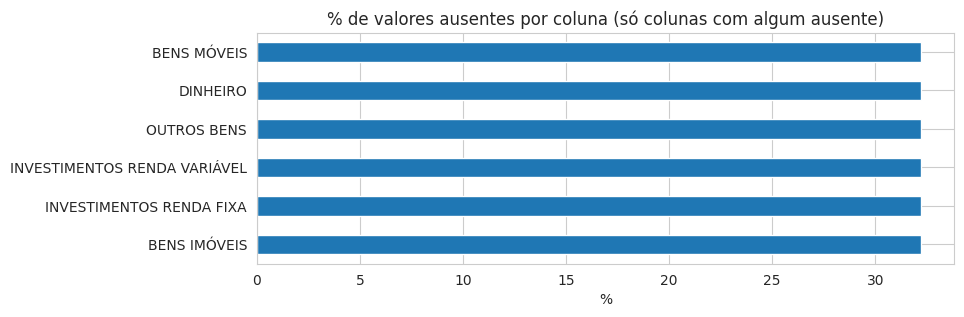

In [11]:
print(f"{df.shape[0]} candidatos x {df.shape[1]} colunas\n")
display(df.dtypes.value_counts().rename('nº de colunas'))

faltantes = (df.isna().mean() * 100).sort_values(ascending=False)
faltantes = faltantes[faltantes > 0]

if len(faltantes) > 0:
    plt.figure(figsize=(9, max(3, len(faltantes) * 0.3)))
    faltantes.plot(kind='barh')
    plt.title('% de valores ausentes por coluna (só colunas com algum ausente)')
    plt.xlabel('%')
    plt.gca().invert_yaxis()
    plt.show()
else:
    print("Nenhuma coluna com valores ausentes.")

## 2) Escolhendo o que explorar

O dataset tem dezenas de colunas — muitas são identificadores administrativos (`SQ_CANDIDATO`, `NR_CPF_CANDIDATO`, `DS_EMAIL`, hashes de geração...) sem valor analítico. As duas listas abaixo reúnem as colunas com conteúdo substantivo — **sintam-se livres para adicionar outras que despertarem curiosidade** (`df.columns` mostra tudo o que está disponível).

In [12]:
display(pd.DataFrame({"Coluna": df.columns}))

,Coluna
0,DT_GERACAO
1,HH_GERACAO
2,ANO_ELEICAO
3,CD_TIPO_ELEICAO
4,NM_TIPO_ELEICAO
5,NR_TURNO
6,CD_ELEICAO
7,DS_ELEICAO
8,DT_ELEICAO
9,TP_ABRANGENCIA


In [13]:
colunas_numericas = [
    'IDADE',
    'Total_Bens',
    'Total_Bens_Log',
    'BENS MÓVEIS',
    'BENS IMÓVEIS',
    'DINHEIRO',
    'INVESTIMENTOS RENDA FIXA',
    'INVESTIMENTOS RENDA VARIÁVEL',
    'OUTROS BENS',
]
colunas_numericas = [c for c in colunas_numericas if c in df.columns]

colunas_categoricas = [
    'DS_GENERO',
    'DS_ESTADO_CIVIL',
    'DS_COR_RACA',
    'DS_GRAU_INSTRUCAO',
    'DS_SITUACAO_CANDIDATURA',
    'DS_SIT_TOT_TURNO',
    'TP_AGREMIACAO',
    'SG_PARTIDO',
    'DS_OCUPACAO',
    'NR_TURNO',
    'SG_UE',
]
colunas_categoricas = [c for c in colunas_categoricas if c in df.columns]

print("Numéricas:")
display(pd.DataFrame({"Coluna": colunas_numericas}))
print("Categóricas:")
display(pd.DataFrame({"Coluna": colunas_categoricas}))

Numéricas:


,Coluna
0,IDADE
1,Total_Bens
2,Total_Bens_Log
3,BENS MÓVEIS
4,BENS IMÓVEIS
5,DINHEIRO
6,INVESTIMENTOS RENDA FIXA
7,INVESTIMENTOS RENDA VARIÁVEL
8,OUTROS BENS


Categóricas:


,Coluna
0,DS_GENERO
1,DS_ESTADO_CIVIL
2,DS_COR_RACA
3,DS_GRAU_INSTRUCAO
4,DS_SITUACAO_CANDIDATURA
5,DS_SIT_TOT_TURNO
6,TP_AGREMIACAO
7,SG_PARTIDO
8,DS_OCUPACAO
9,NR_TURNO


## 3) Variáveis numéricas: distribuição e outliers

In [14]:
display(df[colunas_numericas].describe().T)

,count,mean,std,min,25%,50%,75%,max
IDADE,925.00,47.67,11.80,21.00,40.00,48.00,55.00,85.00
Total_Bens,925.00,"1,175,961.77","4,795,021.35",0.00,0.00,"143,900.00","780,000.00","78,473,746.16"
Total_Bens_Log,925.00,8.68,6.20,0.00,0.00,11.88,13.57,18.18
BENS MÓVEIS,627.00,"106,716.01","243,391.95",0.00,0.00,"20,000.00","118,000.00","2,910,400.00"
BENS IMÓVEIS,627.00,"685,480.93","2,315,347.64",0.00,0.00,"200,000.00","685,643.76","47,183,850.00"
DINHEIRO,627.00,"52,467.52","415,054.37",0.00,0.00,0.00,"8,771.38","8,655,533.00"
INVESTIMENTOS RENDA FIXA,627.00,"159,270.37","2,776,059.05",0.00,0.00,0.00,0.00,"68,772,246.95"
INVESTIMENTOS RENDA VARIÁVEL,627.00,"109,389.20","669,073.13",0.00,0.00,0.00,0.00,"10,850,143.63"
OUTROS BENS,627.00,"621,547.80","3,308,583.58",0.00,0.00,0.00,"100,000.00","50,099,827.38"


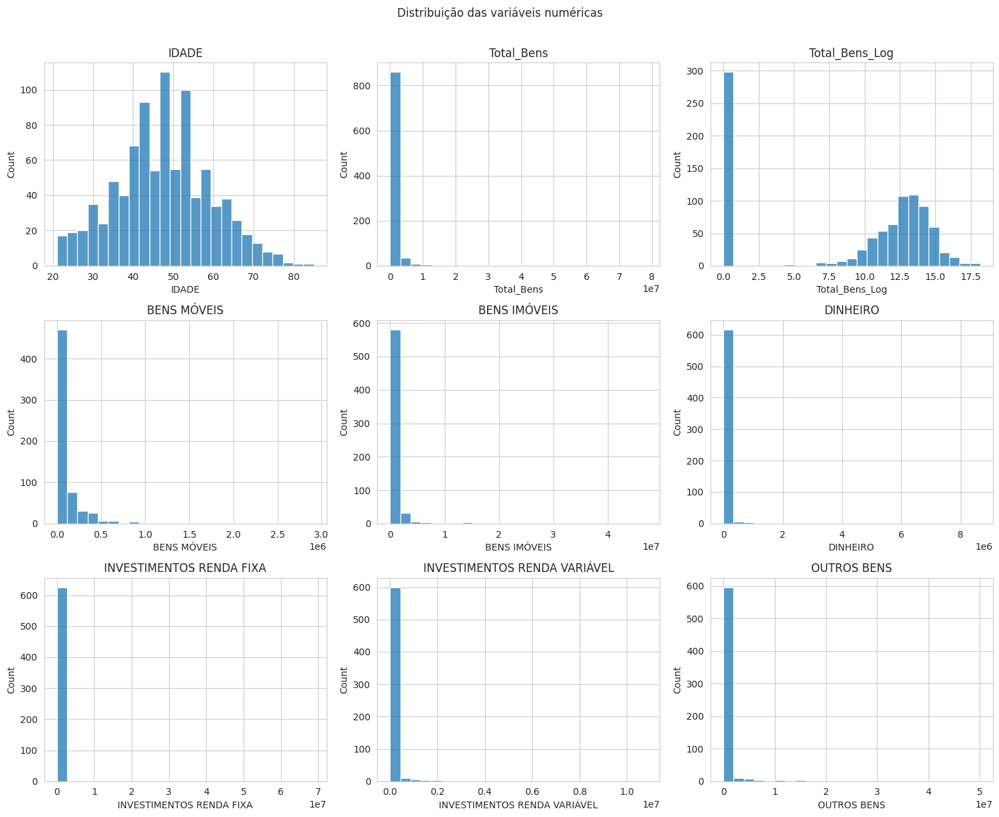

In [15]:
n = len(colunas_numericas)
ncols = 3
nrows = -(-n // ncols)  # arredonda pra cima

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = axes.flatten()

for i, col in enumerate(colunas_numericas):
    sns.histplot(df[col], bins=25, ax=axes[i])
    axes[i].set_title(col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Distribuição das variáveis numéricas', y=1.01)
plt.tight_layout()
plt.show()

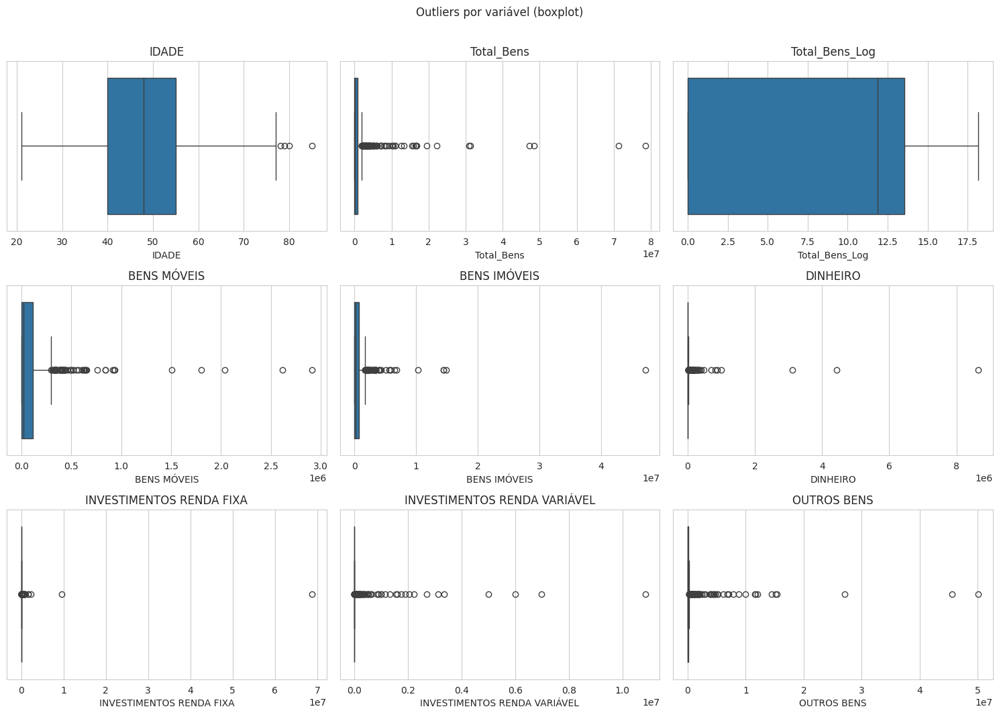

In [16]:
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.5 * nrows))
axes = axes.flatten()

for i, col in enumerate(colunas_numericas):
    sns.boxplot(x=df[col], ax=axes[i])
    axes[i].set_title(col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Outliers por variável (boxplot)', y=1.01)
plt.tight_layout()
plt.show()

### 3.1) Quantificando os outliers (regra do IQR)

O boxplot mostra visualmente; esta tabela quantifica: quantos candidatos ficam fora do intervalo `[Q1 - 1.5·IQR, Q3 + 1.5·IQR]` em cada variável.

In [17]:
linhas = []
for col in colunas_numericas:
    Q1, Q3 = df[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    lim_inf, lim_sup = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    linhas.append({
        'variavel': col, 'limite_inferior': lim_inf, 'limite_superior': lim_sup,
        'qtd_outliers': n_outliers, 'pct_outliers': round(100 * n_outliers / len(df), 1),
    })

pd.DataFrame(linhas).sort_values('pct_outliers', ascending=False)

,variavel,limite_inferior,limite_superior,qtd_outliers,pct_outliers
5,DINHEIRO,"-13,157.06","21,928.44",125,13.50
8,OUTROS BENS,"-150,000.00","250,000.00",120,13.00
6,INVESTIMENTOS RENDA FIXA,0.00,0.00,120,13.00
7,INVESTIMENTOS RENDA VARIÁVEL,0.00,0.00,113,12.20
1,Total_Bens,"-1,170,000.00","1,950,000.00",107,11.60
3,BENS MÓVEIS,"-177,000.00","295,000.00",65,7.00
4,BENS IMÓVEIS,"-1,028,465.63","1,714,109.39",51,5.50
0,IDADE,17.50,77.50,4,0.40
2,Total_Bens_Log,-20.35,33.92,0,0.00


## 4) Variáveis categóricas: contagens e proporções

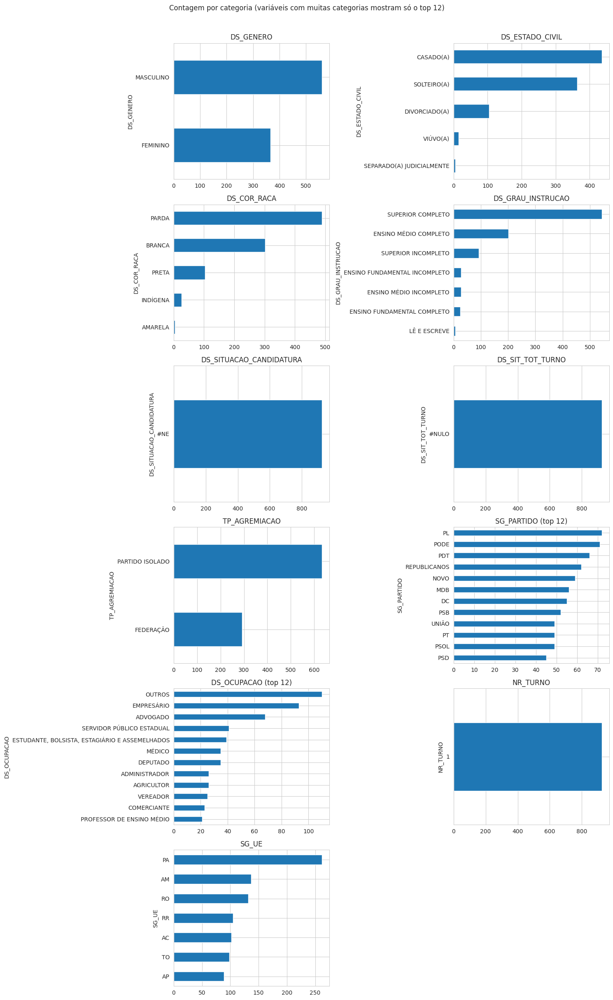

In [18]:
def plot_categorica(ax, coluna, top_n=12):
    contagem = df[coluna].value_counts().head(top_n)
    contagem.plot(kind='barh', ax=ax)
    ax.set_title(coluna + (f' (top {top_n})' if df[coluna].nunique() > top_n else ''))
    ax.invert_yaxis()

n = len(colunas_categoricas)
ncols = 2
nrows = -(-n // ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = axes.flatten()

for i, col in enumerate(colunas_categoricas):
    plot_categorica(axes[i], col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Contagem por categoria (variáveis com muitas categorias mostram só o top 12)', y=1.01)
plt.tight_layout()
plt.show()

In [19]:
for col in colunas_categoricas:
    print(f"--- {col} ({df[col].nunique()} categorias) ---")
    print((df[col].value_counts(normalize=True).head(8) * 100).round(1).astype(str) + '%')
    print()

--- DS_GENERO (2 categorias) ---
DS_GENERO
MASCULINO    60.5%
FEMININO     39.5%
Name: proportion, dtype: object

--- DS_ESTADO_CIVIL (5 categorias) ---
DS_ESTADO_CIVIL
CASADO(A)                    47.1%
SOLTEIRO(A)                  39.4%
DIVORCIADO(A)                11.4%
VIÚVO(A)                      1.6%
SEPARADO(A) JUDICIALMENTE     0.5%
Name: proportion, dtype: object

--- DS_COR_RACA (5 categorias) ---
DS_COR_RACA
PARDA       52.9%
BRANCA      32.6%
PRETA       11.1%
INDÍGENA     2.8%
AMARELA      0.5%
Name: proportion, dtype: object

--- DS_GRAU_INSTRUCAO (7 categorias) ---
DS_GRAU_INSTRUCAO
SUPERIOR COMPLETO                58.8%
ENSINO MÉDIO COMPLETO            21.8%
SUPERIOR INCOMPLETO               9.9%
ENSINO FUNDAMENTAL INCOMPLETO     3.0%
ENSINO MÉDIO INCOMPLETO           2.9%
ENSINO FUNDAMENTAL COMPLETO       2.7%
LÊ E ESCREVE                      0.8%
Name: proportion, dtype: object

--- DS_SITUACAO_CANDIDATURA (1 categorias) ---
DS_SITUACAO_CANDIDATURA
#NE    100.0%
Nam

## 5) Dispersão entre variáveis numéricas

Correlação e gráficos de dispersão par a par — sem nenhuma variável de destaque, só pra ver como as variáveis se relacionam (ou não).

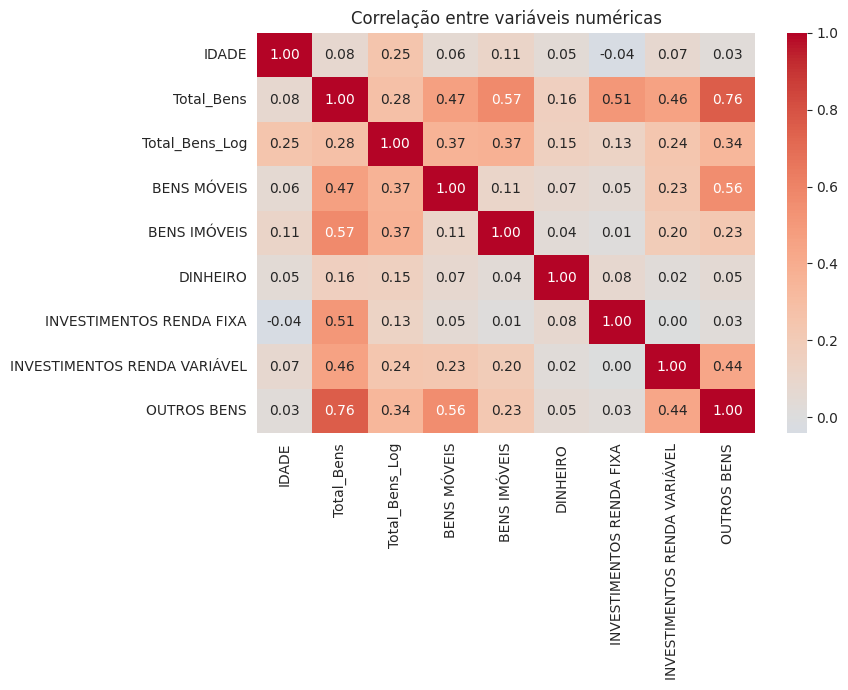

In [20]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[colunas_numericas].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlação entre variáveis numéricas')
plt.tight_layout()
plt.show()

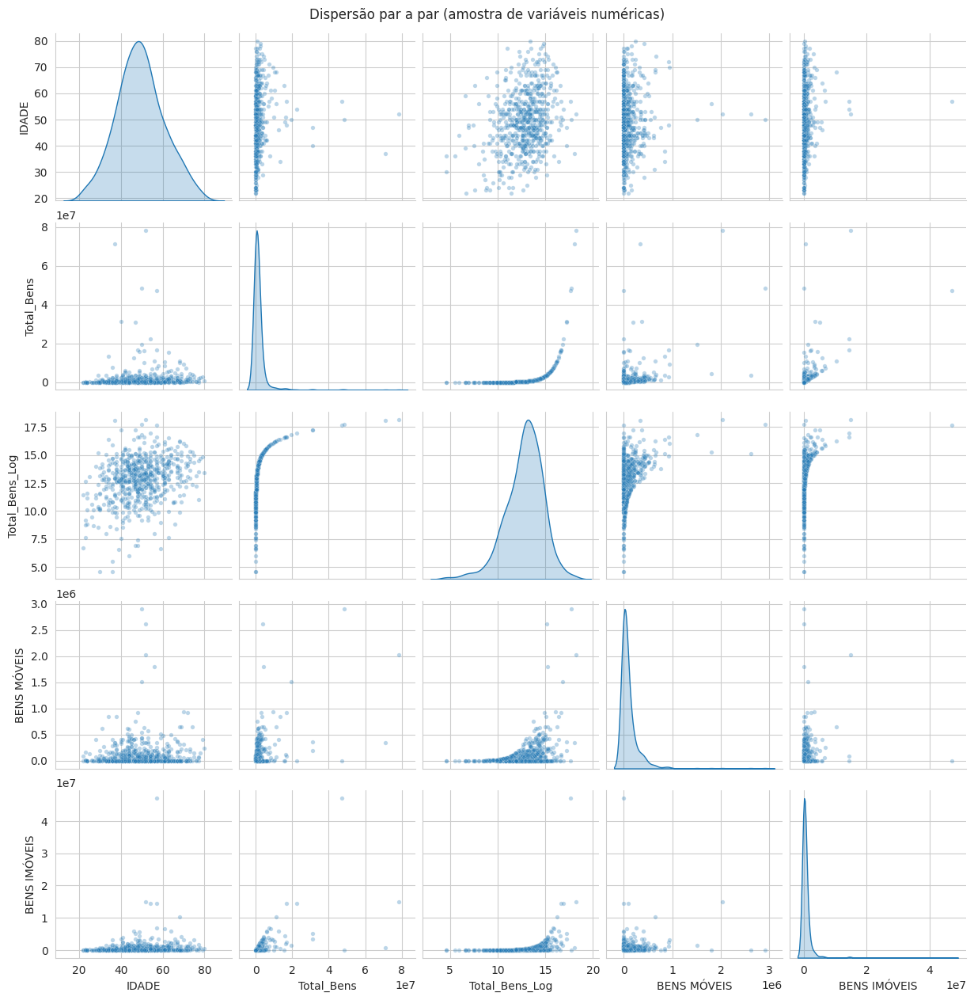

In [21]:
# Pairplot com um subconjunto (pairplot com muitas variáveis fica pesado/ilegível)
subset = colunas_numericas[:5]
sns.pairplot(df[subset].dropna(), diag_kind='kde', plot_kws={'alpha': 0.3, 's': 15})
plt.suptitle('Dispersão par a par (amostra de variáveis numéricas)', y=1.01)
plt.show()

### 5.1) Um exemplo de dispersão colorida

Só um exemplo de como cruzar uma variável numérica com outra numérica *e* uma categórica ao mesmo tempo — troquem `x`, `y` e `hue` livremente para explorar outras combinações.

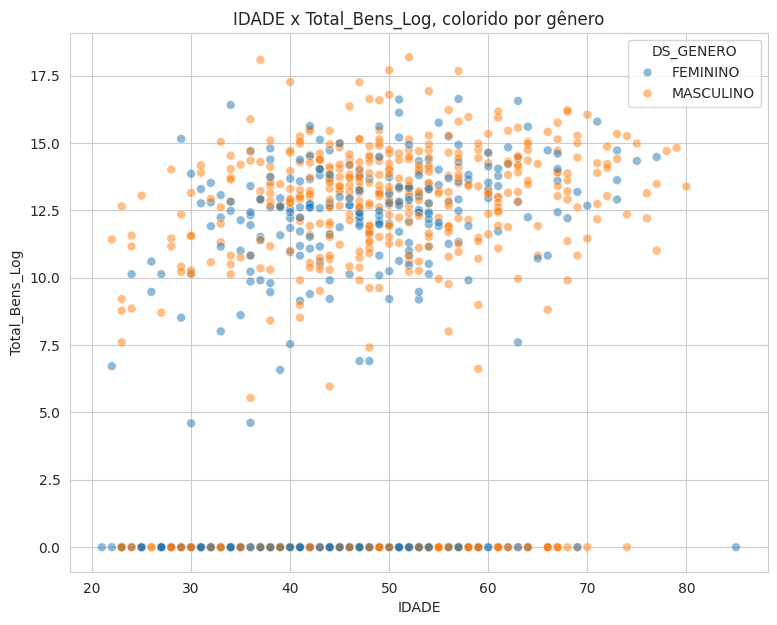

In [22]:
plt.figure(figsize=(9, 7))
sns.scatterplot(data=df, x='IDADE', y='Total_Bens_Log', hue='DS_GENERO', alpha=0.5, s=40)
plt.title('IDADE x Total_Bens_Log, colorido por gênero')
plt.show()

## 6) Proporções entre grupos

Alguns exemplos de cruzamentos categóricos — não são os únicos possíveis, só uma amostra do tipo de pergunta que dá pra fazer.

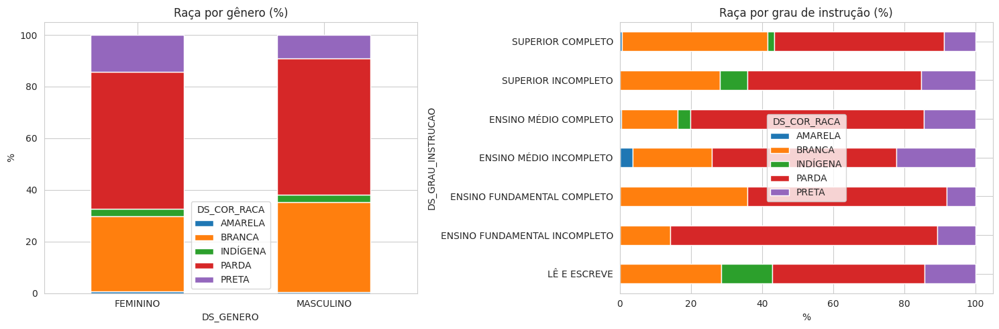

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

pd.crosstab(df['DS_GENERO'], df['DS_COR_RACA'], normalize='index').mul(100).plot(
    kind='bar', stacked=True, ax=axes[0]
)
axes[0].set_title('Raça por gênero (%)')
axes[0].set_ylabel('%')
axes[0].tick_params(axis='x', rotation=0)

ordem_instrucao = df[['CD_GRAU_INSTRUCAO', 'DS_GRAU_INSTRUCAO']].drop_duplicates().sort_values('CD_GRAU_INSTRUCAO')['DS_GRAU_INSTRUCAO']
pd.crosstab(df['DS_GRAU_INSTRUCAO'], df['DS_COR_RACA'], normalize='index').loc[ordem_instrucao].mul(100).plot(
    kind='barh', stacked=True, ax=axes[1]
)
axes[1].set_title('Raça por grau de instrução (%)')
axes[1].set_xlabel('%')

plt.tight_layout()
plt.show()

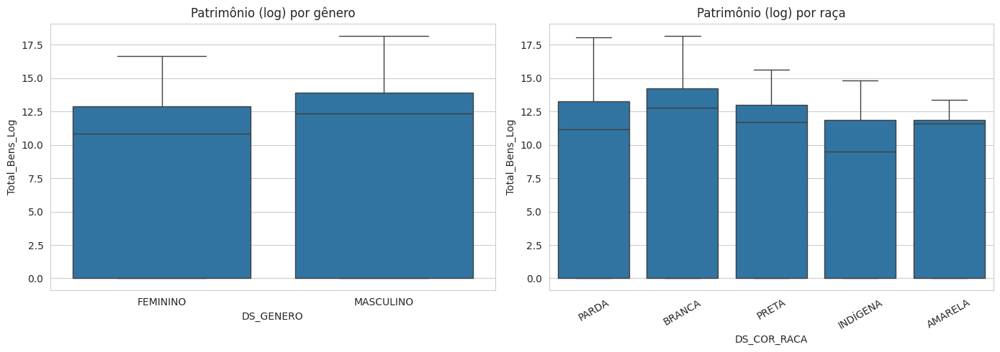

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x='DS_GENERO', y='Total_Bens_Log', ax=axes[0])
axes[0].set_title('Patrimônio (log) por gênero')

sns.boxplot(data=df, x='DS_COR_RACA', y='Total_Bens_Log', ax=axes[1])
axes[1].set_title('Patrimônio (log) por raça')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

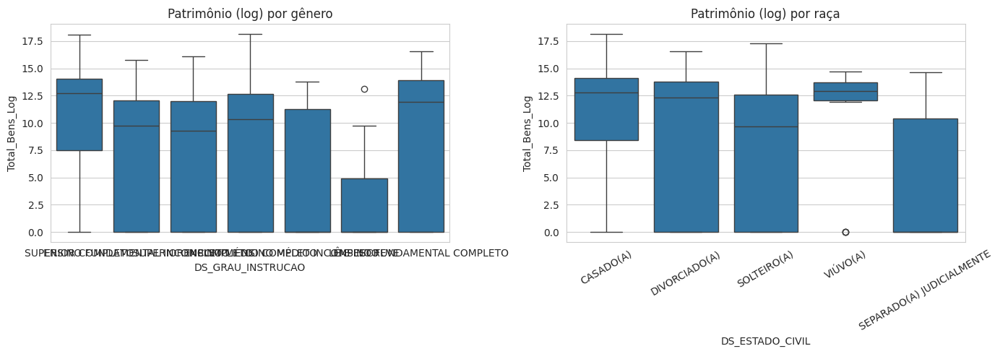

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x='DS_GRAU_INSTRUCAO', y='Total_Bens_Log', ax=axes[0])
axes[0].set_title('Patrimônio (log) por gênero')

sns.boxplot(data=df, x='DS_ESTADO_CIVIL', y='Total_Bens_Log', ax=axes[1])
axes[1].set_title('Patrimônio (log) por raça')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

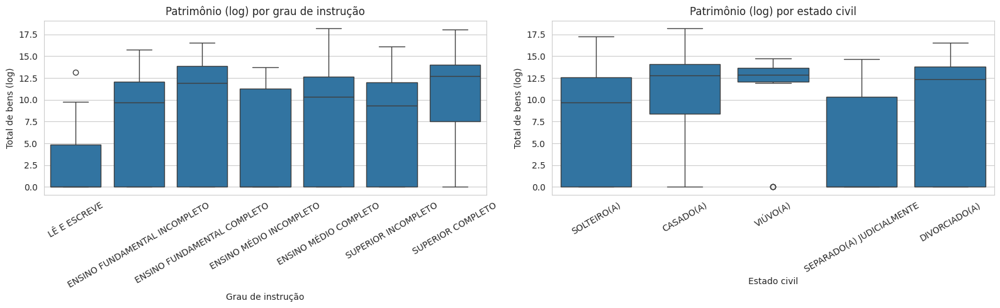

In [26]:
# Ordem do grau de instrução pelo respectivo código
ordem_instrucao = (
    df[['CD_GRAU_INSTRUCAO', 'DS_GRAU_INSTRUCAO']]
    .drop_duplicates()
    .sort_values('CD_GRAU_INSTRUCAO')
    ['DS_GRAU_INSTRUCAO']
    .tolist()
)

# Ordem do estado civil pelo respectivo código
ordem_estado_civil = (
    df[['CD_ESTADO_CIVIL', 'DS_ESTADO_CIVIL']]
    .drop_duplicates()
    .sort_values('CD_ESTADO_CIVIL')
    ['DS_ESTADO_CIVIL']
    .tolist()
)


# Cria os dois gráficos lado a lado
fig, axes = plt.subplots(1, 2, figsize=(16, 5))


# Grau de instrução
sns.boxplot(
    data=df,
    x='DS_GRAU_INSTRUCAO',
    y='Total_Bens_Log',
    order=ordem_instrucao,
    ax=axes[0]
)

axes[0].set_title('Patrimônio (log) por grau de instrução')
axes[0].set_xlabel('Grau de instrução')
axes[0].set_ylabel('Total de bens (log)')
axes[0].tick_params(axis='x', rotation=30)


# Estado civil
sns.boxplot(
    data=df,
    x='DS_ESTADO_CIVIL',
    y='Total_Bens_Log',
    order=ordem_estado_civil,
    ax=axes[1]
)

axes[1].set_title('Patrimônio (log) por estado civil')
axes[1].set_xlabel('Estado civil')
axes[1].set_ylabel('Total de bens (log)')
axes[1].tick_params(axis='x', rotation=30)


plt.tight_layout()
plt.show()

## 7) Comparação entre UFs

Esta seção só roda na visão **Brasil** (quando `UF = None`) — não se aplica ao recorte por estado.

,qtd_candidatos,idade_media,patrimonio_mediano,pct_feminino
SG_UF,,,,
PA,262,46.60,"58,500.00",38.50
AM,137,46.90,"44,462.50",39.40
RO,132,49.20,"348,600.00",35.60
RR,105,48.50,"150,000.00",41.00
AC,102,47.50,"172,500.00",42.20
TO,98,48.00,"359,319.00",40.80
AP,89,48.60,"121,000.00",41.60


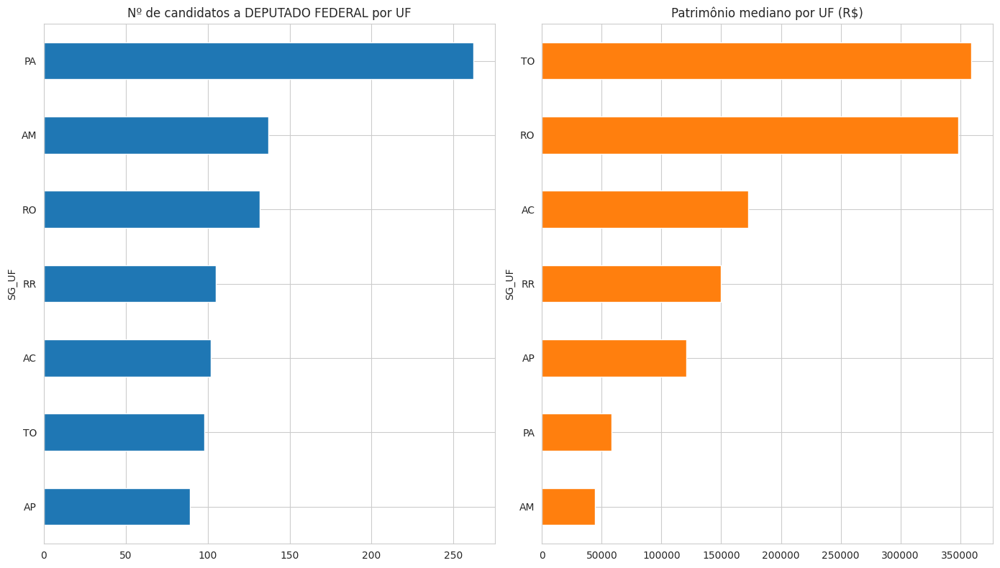

In [27]:
if mostrar_por_uf:
    resumo_uf = df.groupby('SG_UF').agg(
        qtd_candidatos=('SQ_CANDIDATO', 'count'),
        idade_media=('IDADE', 'mean'),
        patrimonio_mediano=('Total_Bens', 'median'),
        pct_feminino=('DS_GENERO', lambda x: (x == 'FEMININO').mean() * 100),
    ).round(1).sort_values('qtd_candidatos', ascending=False)

    display(resumo_uf)

    fig, axes = plt.subplots(1, 2, figsize=(14, 8))
    resumo_uf['qtd_candidatos'].sort_values().plot(kind='barh', ax=axes[0])
    axes[0].set_title(f'Nº de candidatos a {CARGO} por UF')

    resumo_uf['patrimonio_mediano'].sort_values().plot(kind='barh', ax=axes[1], color='tab:orange')
    axes[1].set_title('Patrimônio mediano por UF (R$)')

    plt.tight_layout()
    plt.show()
else:
    print(f"UF = {UF!r} — seção não se aplica (dados já filtrados para uma única UF).")

---
## Fechamento

Este notebook não teve o objetivo de "preparar terreno" para nenhuma técnica específica — foi só olhar para os dados. Antes de seguir, escrevam algumas observações próprias: quais variáveis têm mais outliers? Alguma proporção chamou atenção? Alguma dispersão sugere relação entre variáveis (ou ausência dela)? Essas observações são o ponto de partida — não a conclusão — das próximas fases.

## Próximo passo

**Fase 2 — Clusterização** (K-Means, DBSCAN, hierárquico e Bisecting K-Means) — liberada em breve. A escolha de variáveis para essa fase parte do que vocês observaram aqui.

---

# Fase 2 — Clusterização (K-Means e Bisecting K-Means)

Agrupamento por idade, escolaridade e patrimônio. Escolha de *k* por cotovelo/silhueta e adoção do **Bisecting K-Means (k=5)** como resultado oficial, com nomes interpretáveis.

# Fase 2 — Clusterização: Candidatos 2026 (TSE)

## Pergunta de negócio

> **Existem perfis demográfico-sociais distintos entre os candidatos, nas Eleições 2026? Combinando idade, escolaridade e patrimônio declarado, os candidatos se agrupam em segmentos claramente diferentes — e, se sim, como esses segmentos se distribuem em termos de gênero, cor/raça e estado civil?**

Para responder isso com K-Means, separamos as variáveis em dois papéis:

- **Variáveis-driver** (entram na conta de distância, definem os clusters): idade, escolaridade e patrimônio declarado.
- **Variáveis de perfil** (não entram no modelo — descrevem os clusters depois de prontos): `DS_GENERO`, `DS_COR_RACA`, `DS_ESTADO_CIVIL`.

> `DS_SIT_TOT_TURNO` (situação eleitoral — eleito ou não) fica de fora por enquanto: a eleição de 2026 ainda não aconteceu, então essa coluna vem toda nula nesta base. Assim que o resultado sair, vale voltar aqui e cruzar os clusters com quem foi eleito.

Essa separação importa: jogar categóricas como gênero/raça direto numa distância Euclidiana exigiria codificação cuidadosa (fora do escopo desta primeira versão). Em vez disso, os grupos nascem de 3 variáveis contínuas/ordinais bem comportadas, e o "perfil demográfico-social" completo — que é o que a pergunta pede — aparece na leitura dos clusters, não na formação deles.

**Este notebook cobre a Parte 1 (K-Means)**, em **duas rodadas de propósito**, pra mostrar por que escolha de variável e escolha de métrica importam:

1. **Versão 1**: exatamente como fizemos na primeira tentativa — escolaridade entra como o código bruto do TSE, seleção de `k` só com cotovelo + silhouette.
2. **Versão 2**: escolaridade recodificada como variável intervalar, e mais duas métricas (Davies-Bouldin, Calinski-Harabasz) apoiando a escolha de `k`.

DBSCAN, hierárquico e Bisecting K-Means serão adicionados nas próximas atualizações, reaproveitando a mesma base e a mesma pergunta.

Parte do arquivo salvo pela **Fase 0** (`00_preparacao_dados.ipynb`).

## Configuração

Use os **mesmos valores** que você usou na Fase 0/1, para carregar o arquivo certo.

In [28]:
CARGO = "DEPUTADO FEDERAL"
# Recorte deste trabalho: Deputados Federais da REGIÃO NORTE (7 UFs).
# O molde original do professor usa uma única UF (string) ou None (Brasil inteiro).
# Aqui estendemos a configuração: UF pode ser uma LISTA de siglas -> filtramos com .isin(...).
UF = ["AC", "AM", "AP", "PA", "RO", "RR", "TO"]   # None = Brasil; "SP" = uma UF; lista = região
NOME_RECORTE = "NORTE"     # rótulo usado no nome do arquivo quando UF é uma lista/região
ANO_ELEICAO = 2026

# Seções de comparação entre UFs: no molde do professor só rodavam na visão Brasil (UF = None).
# Como agora o recorte é uma região com 7 UFs, faz sentido rodá-las para comparar os estados.
mostrar_por_uf = (UF is None) or (isinstance(UF, (list, tuple, set)) and len(UF) > 1)

In [29]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

sns.set_style("whitegrid")
pd.set_option('display.max_columns', None)

SEMENTE = 42
np.random.seed(SEMENTE)  # reprodutibilidade defensiva — o KMeans já usa random_state próprio,
                          # mas fixar a semente global evita surpresa se alguém adicionar
                          # outro trecho aleatório (amostragem, shuffle, etc.) mais adiante.

nome_uf = 'BRASIL' if UF is None else (NOME_RECORTE if isinstance(UF, (list, tuple, set)) else UF)
nome_cargo = CARGO.replace(' ', '_')
arquivo = f"dados/candidatos_{nome_cargo}_{nome_uf}_{ANO_ELEICAO}.csv"

df = pd.read_csv(arquivo)
print(f"Carregado: {arquivo}  ->  {df.shape[0]} candidatos, {df.shape[1]} colunas")
df.head()

# Nomes dos clusters do Bisecting K-Means (k=5), por perfil socioeconômico — definidos aqui
# para já ficarem disponíveis nos gráficos de exploração (radar/dispersão), não só mais adiante.
NOMES_CLUSTER_BISECTING = {
    'A': 'Prósperos',
    'B': 'Batalhadores',
    'C': 'Promissores',
    'D': 'Recém-chegados',
    'E': 'Desassistidos',
}


Carregado: dados/candidatos_DEPUTADO_FEDERAL_NORTE_2026.csv  ->  925 candidatos, 59 colunas


---
# Versão 1 — a primeira tentativa

Variáveis-driver: `IDADE`, `CD_GRAU_INSTRUCAO` (código bruto do TSE, 2 a 8), `Total_Bens_Log`. Escolha de `k` só com cotovelo (WCSS) + silhouette.

### V1.1) Outliers e padronização

In [30]:
colunas_driver_v1 = ['IDADE', 'CD_GRAU_INSTRUCAO', 'Total_Bens_Log']

antes = df.shape[0]
Q1, Q3 = df['Total_Bens_Log'].quantile([0.25, 0.75])
IQR = Q3 - Q1
limite_superior = Q3 + 1.5 * IQR

df_cluster_v1 = df[df['Total_Bens_Log'] <= limite_superior].copy()
print(f"Removidos {antes - df_cluster_v1.shape[0]} candidatos com patrimônio extremo "
      f"(Total_Bens_Log > {limite_superior:.2f}, ~R$ {np.expm1(limite_superior):,.0f})")
print(f"Base para clusterização: {df_cluster_v1.shape[0]} candidatos")

scaler_v1 = MinMaxScaler()
X_v1 = scaler_v1.fit_transform(df_cluster_v1[colunas_driver_v1])

df_cluster_v1[colunas_driver_v1].describe()

Removidos 0 candidatos com patrimônio extremo (Total_Bens_Log > 33.92, ~R$ 537,326,053,302,416)
Base para clusterização: 925 candidatos


,IDADE,CD_GRAU_INSTRUCAO,Total_Bens_Log
count,925.00,925.00,925.00
mean,47.67,7.07,8.68
std,11.80,1.36,6.20
min,21.00,2.00,0.00
25%,40.00,6.00,0.00
50%,48.00,8.00,11.88
75%,55.00,8.00,13.57
max,85.00,8.00,18.18


### V1.2) Escolhendo k (cotovelo + silhouette)

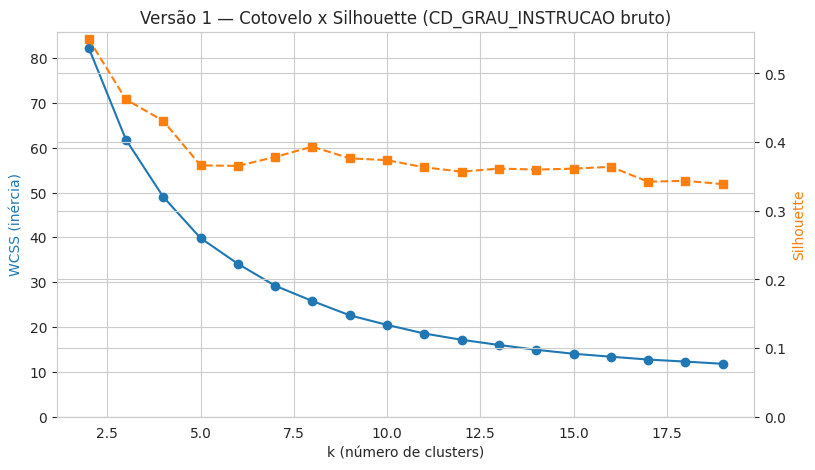

k=2  WCSS=82.337  silhouette=0.550
k=3  WCSS=61.801  silhouette=0.462
k=4  WCSS=49.034  silhouette=0.431
k=5  WCSS=39.852  silhouette=0.366
k=6  WCSS=34.114  silhouette=0.365
k=7  WCSS=29.222  silhouette=0.378
k=8  WCSS=25.802  silhouette=0.393
k=9  WCSS=22.616  silhouette=0.376
k=10  WCSS=20.484  silhouette=0.374
k=11  WCSS=18.558  silhouette=0.363
k=12  WCSS=17.156  silhouette=0.357
k=13  WCSS=16.005  silhouette=0.361
k=14  WCSS=14.931  silhouette=0.360
k=15  WCSS=14.044  silhouette=0.361
k=16  WCSS=13.384  silhouette=0.364
k=17  WCSS=12.754  silhouette=0.342
k=18  WCSS=12.292  silhouette=0.344
k=19  WCSS=11.808  silhouette=0.339


In [31]:
wcss_v1, sil_v1 = [], []
faixa_k = range(2, 20)

for k in faixa_k:
    km = KMeans(n_clusters=k, random_state=SEMENTE, n_init=10)
    labels = km.fit_predict(X_v1)
    wcss_v1.append(km.inertia_)
    sil_v1.append(silhouette_score(X_v1, labels))

fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(list(faixa_k), wcss_v1, marker='o', color='tab:blue')
ax1.set_xlabel('k (número de clusters)')
ax1.set_ylabel('WCSS (inércia)', color='tab:blue')
ax1.set_ylim(bottom=0)  # eixo começa em zero: um eixo cortado pode fazer o cotovelo parecer mais dramático do que é
ax1.set_title('Versão 1 — Cotovelo x Silhouette (CD_GRAU_INSTRUCAO bruto)')

ax2 = ax1.twinx()
ax2.plot(list(faixa_k), sil_v1, marker='s', linestyle='--', color='tab:orange')
ax2.set_ylabel('Silhouette', color='tab:orange')
ax2.set_ylim(bottom=min(0, min(sil_v1)))
plt.show()

for k, w, s in zip(faixa_k, wcss_v1, sil_v1):
    print(f"k={k}  WCSS={w:.3f}  silhouette={s:.3f}")

> Repare que o cotovelo não mostra uma quebra nítida — a curva desce suavemente, sem um "V" claro. Isso pode ser dado real (candidatos formando mais um contínuo do que grupos separados) ou pode ser efeito de tratar uma variável ordinal como se fosse intervalar. Seguimos mesmo assim com um `k` razoável, só pra completar a Versão 1 e comparar depois.

In [32]:
k_v1 = 5  # ajuste conforme a célula anterior, se quiser

kmeans_v1 = KMeans(n_clusters=k_v1, random_state=SEMENTE, n_init=10)
df_cluster_v1['cluster'] = kmeans_v1.fit_predict(X_v1)
df_cluster_v1['cluster'] = df_cluster_v1['cluster'].map(lambda x: chr(65 + x))

# Nomes próprios dos grupos do K-Means Versão 1 (por perfil socioeconômico), a partir da ficha abaixo.
NOMES_KMEANS_V1 = {
    'A': 'Recém-chegados',
    'B': 'Prósperos (jovens)',  # subgrupo; esta solução não separa Desassistidos
    'C': 'Promissores',
    'D': 'Prósperos',
    'E': 'Batalhadores',
}

df_cluster_v1['cluster'] = df_cluster_v1['cluster'].map(NOMES_KMEANS_V1)

centroides_v1 = scaler_v1.inverse_transform(kmeans_v1.cluster_centers_)
df_centroides_v1 = pd.DataFrame(centroides_v1, columns=colunas_driver_v1)
df_centroides_v1.index = [NOMES_KMEANS_V1[chr(65 + i)] for i in range(k_v1)]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(data=df_cluster_v1, x='IDADE', y='Total_Bens_Log', hue='cluster', palette='Set2', alpha=0.5, s=40, ax=axes[0])
axes[0].scatter(df_centroides_v1['IDADE'], df_centroides_v1['Total_Bens_Log'], marker='X', s=300, c='black')
axes[0].set_title('IDADE x Total_Bens_Log')

sns.scatterplot(data=df_cluster_v1, x='CD_GRAU_INSTRUCAO', y='Total_Bens_Log', hue='cluster', palette='Set2', alpha=0.5, s=40, ax=axes[1])
axes[1].scatter(df_centroides_v1['CD_GRAU_INSTRUCAO'], df_centroides_v1['Total_Bens_Log'], marker='X', s=300, c='black')
axes[1].set_title('CD_GRAU_INSTRUCAO x Total_Bens_Log')

plt.suptitle(f'Versão 1 — clusters nas variáveis naturais (k={k_v1})', y=1.02)
plt.tight_layout()
plt.show()

resumo_v1 = df_cluster_v1.groupby('cluster').agg(
    qtd_candidatos=('SQ_CANDIDATO', 'count'),
    idade_media=('IDADE', 'mean'),
    instrucao_media=('CD_GRAU_INSTRUCAO', 'mean'),
    patrimonio_mediano=('Total_Bens', 'median'),
).round(1)
display(resumo_v1)

,qtd_candidatos,idade_media,instrucao_media,patrimonio_mediano
cluster,,,,
Batalhadores,153,51.20,5.40,"300,000.00"
Prósperos (jovens),256,40.50,7.80,"354,504.70"
Promissores,173,44.70,7.80,0.00
Prósperos,214,58.70,7.90,"720,468.40"
Recém-chegados,129,43.40,5.30,0.00


---
# Versão 2 — ajustando a variável e a métrica

Dois ajustes em relação à Versão 1:

1. **Escolaridade como variável intervalar.** `CD_GRAU_INSTRUCAO` é um código **ordinal**, não intervalar: nada garante que o "salto" entre dois códigos consecutivos valha o mesmo em todos os pontos da escala (a diferença entre "lê e escreve" e "fundamental incompleto" não é comparável à diferença entre "superior incompleto" e "superior completo"). Como o K-Means calcula médias e distância Euclidiana, ele *assume* espaçamento igual — então usar o código bruto distorce essa variável. Trocamos pelo proxy padrão em pesquisa social: **anos de escolaridade equivalentes** (mesma lógica usada em censos/pesquisas domiciliares).
2. **Mais métricas para escolher `k`.** Além de WCSS e silhouette, adicionamos Davies-Bouldin e Calinski-Harabasz — quando o cotovelo é ambíguo (como foi o caso), várias métricas concordando é um sinal mais forte do que uma métrica só.

In [33]:
ANOS_ESTUDO_POR_GRAU = {
    'ANALFABETO': 0,
    'LÊ E ESCREVE': 1,
    'ENSINO FUNDAMENTAL INCOMPLETO': 4,
    'ENSINO FUNDAMENTAL COMPLETO': 8,
    'ENSINO MÉDIO INCOMPLETO': 9,
    'ENSINO MÉDIO COMPLETO': 11,
    'SUPERIOR INCOMPLETO': 13,
    'SUPERIOR COMPLETO': 16,
    # 'NÃO DIVULGÁVEL' fica de fora de propósito — não dá pra estimar anos de estudo sem essa informação
}

df['ANOS_ESTUDO'] = df['DS_GRAU_INSTRUCAO'].map(ANOS_ESTUDO_POR_GRAU)

print("Candidatos sem correspondência (NÃO DIVULGÁVEL ou similar):", df['ANOS_ESTUDO'].isna().sum())
df[['DS_GRAU_INSTRUCAO', 'ANOS_ESTUDO']].drop_duplicates().sort_values('ANOS_ESTUDO')

Candidatos sem correspondência (NÃO DIVULGÁVEL ou similar): 0


,DS_GRAU_INSTRUCAO,ANOS_ESTUDO
32,LÊ E ESCREVE,1
5,ENSINO FUNDAMENTAL INCOMPLETO,4
52,ENSINO FUNDAMENTAL COMPLETO,8
27,ENSINO MÉDIO INCOMPLETO,9
19,ENSINO MÉDIO COMPLETO,11
17,SUPERIOR INCOMPLETO,13
0,SUPERIOR COMPLETO,16


> **Alternativa mais rigorosa (fora do escopo desta primeira versão):** distância de **Gower** — que trata variáveis ordinais, nominais e contínuas de forma nativa, sem forçar nenhuma delas a um espaçamento artificial — combinada com **K-Medoids/PAM** em vez de K-Means (Gower não permite calcular "média", só distância entre pontos reais). Fica como comparação futura, ao lado de DBSCAN/hierárquico/Bisecting K-Means.

### V2.1) Outliers e padronização

In [34]:
colunas_driver = ['IDADE', 'ANOS_ESTUDO', 'Total_Bens_Log']

antes = df.shape[0]
df_cluster = df[(df['Total_Bens_Log'] <= limite_superior) & (df['ANOS_ESTUDO'].notna())].copy()
print(f"Removidos {antes - df_cluster.shape[0]} candidatos "
      f"(patrimônio extremo acima de ~R$ {np.expm1(limite_superior):,.0f}, ou escolaridade não divulgada)")
print(f"Base para clusterização: {df_cluster.shape[0]} candidatos")

scaler = MinMaxScaler()
X = scaler.fit_transform(df_cluster[colunas_driver])

df_cluster[colunas_driver].describe()

Removidos 0 candidatos (patrimônio extremo acima de ~R$ 537,326,053,302,416, ou escolaridade não divulgada)
Base para clusterização: 925 candidatos


,IDADE,ANOS_ESTUDO,Total_Bens_Log
count,925.00,925.00,925.00
mean,47.67,13.71,8.68
std,11.80,3.22,6.20
min,21.00,1.00,0.00
25%,40.00,11.00,0.00
50%,48.00,16.00,11.88
75%,55.00,16.00,13.57
max,85.00,16.00,18.18


### V2.2) Escolhendo k (cotovelo + silhouette + Davies-Bouldin + Calinski-Harabasz)

- **Silhouette** (quanto maior, melhor).
- **Davies-Bouldin** (quanto **menor**, melhor): quão parecidos/sobrepostos os clusters são entre si.
- **Calinski-Harabasz** (quanto maior, melhor): razão entre dispersão entre clusters e dispersão dentro dos clusters.

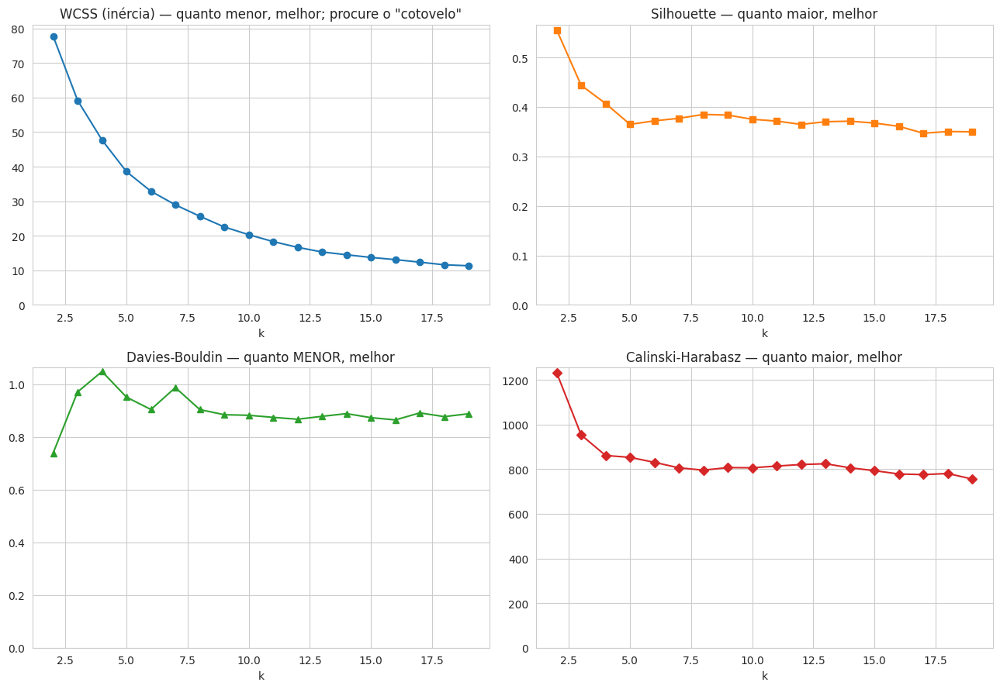

,k,wcss,silhouette,davies_bouldin,calinski_harabasz
0,2,77.73,0.56,0.74,"1,231.95"
1,3,59.15,0.44,0.97,953.41
2,4,47.69,0.41,1.05,861.28
3,5,38.55,0.36,0.95,852.83
4,6,32.89,0.37,0.90,830.48
5,7,28.95,0.38,0.99,806.01
6,8,25.66,0.39,0.90,795.53
7,9,22.55,0.38,0.88,806.91
8,10,20.33,0.38,0.88,806.09
9,11,18.32,0.37,0.87,813.87


In [35]:
wcss, sil, db, ch = [], [], [], []

for k in faixa_k:
    km = KMeans(n_clusters=k, random_state=SEMENTE, n_init=10)
    labels = km.fit_predict(X)
    wcss.append(km.inertia_)
    sil.append(silhouette_score(X, labels))
    db.append(davies_bouldin_score(X, labels))
    ch.append(calinski_harabasz_score(X, labels))

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

axes[0, 0].plot(list(faixa_k), wcss, marker='o', color='tab:blue')
axes[0, 0].set_title('WCSS (inércia) — quanto menor, melhor; procure o "cotovelo"')
axes[0, 0].set_ylim(bottom=0)

axes[0, 1].plot(list(faixa_k), sil, marker='s', color='tab:orange')
axes[0, 1].set_title('Silhouette — quanto maior, melhor')
axes[0, 1].set_ylim(bottom=min(0, min(sil)))

axes[1, 0].plot(list(faixa_k), db, marker='^', color='tab:green')
axes[1, 0].set_title('Davies-Bouldin — quanto MENOR, melhor')
axes[1, 0].set_ylim(bottom=0)

axes[1, 1].plot(list(faixa_k), ch, marker='D', color='tab:red')
axes[1, 1].set_title('Calinski-Harabasz — quanto maior, melhor')
axes[1, 1].set_ylim(bottom=0)

# eixo em zero: evita que um eixo cortado exagere visualmente uma quebra que não é tão forte assim
for ax in axes.flatten():
    ax.set_xlabel('k')
    ax.grid(True)

plt.tight_layout()
plt.show()

pd.DataFrame({'k': list(faixa_k), 'wcss': wcss, 'silhouette': sil, 'davies_bouldin': db, 'calinski_harabasz': ch}).round(3)

### V2.3) Ajustando o K-Means

Escolha o `k` cruzando as quatro métricas acima — se elas discordarem muito, prefira o `k` mais fácil de interpretar/explicar dentro da pergunta de negócio.

In [36]:
k_final = 5  # ajuste conforme a célula anterior

kmeans = KMeans(n_clusters=k_final, random_state=SEMENTE, n_init=10)
df_cluster['cluster'] = kmeans.fit_predict(X)
df_cluster['cluster'] = df_cluster['cluster'].map(lambda x: chr(65 + x))

# Nomes próprios dos grupos do K-Means Versão 2 (por perfil socioeconômico), atribuídos a partir
# da ficha técnica logo abaixo. Diferente do Bisecting, este K-Means divide os "com patrimônio +
# superior" por IDADE (veteranos x jovens) e não isola o grupo de baixa escolaridade.
NOMES_KMEANS_V2 = {
    'A': 'Recém-chegados',        # jovens, sem patrimônio, ensino médio
    'B': 'Prósperos (veteranos)',  # patrimônio alto, superior, mais velhos
    'C': 'Promissores',           # sem patrimônio, superior
    'D': 'Batalhadores',          # patrimônio médio, ensino médio
    'E': 'Prósperos (jovens)',  # patrimônio, superior, mais jovens
}
df_cluster['cluster'] = df_cluster['cluster'].map(NOMES_KMEANS_V2)


# ordem = A..E do K-Means, preservada para casar com a ordem dos centróides; paleta fixa por nome
clusters_ordenados = [NOMES_KMEANS_V2[chr(65 + i)] for i in range(k_final)]
df_cluster['cluster'] = pd.Categorical(df_cluster['cluster'], categories=clusters_ordenados, ordered=True)
cores_cluster = dict(zip(clusters_ordenados, sns.color_palette('Set2', n_colors=len(clusters_ordenados))))

df_cluster['cluster'].value_counts().reindex(clusters_ordenados)

In [37]:
resumo_driver = df_cluster.groupby('cluster').agg(
    qtd_candidatos=('SQ_CANDIDATO', 'count'),
    idade_media=('IDADE', 'mean'),
    anos_estudo_medio=('ANOS_ESTUDO', 'mean'),
    patrimonio_mediano=('Total_Bens', 'median'),
).round(1)
display(resumo_driver)

centroides_norm = kmeans.cluster_centers_
centroides_naturais = scaler.inverse_transform(centroides_norm)
df_centroides = pd.DataFrame(centroides_naturais, columns=colunas_driver)
df_centroides.index = clusters_ordenados
df_centroides.index.name = 'cluster'
df_centroides.round(1)

### Radar: todos os clusters juntos, e depois um a um

Primeiro, todos os clusters sobrepostos no mesmo radar — bom pra comparar formatos de relance. Logo abaixo, o mesmo radar **separado por cluster** — mais fácil de ler o formato de cada um sem o excesso de linhas sobrepostas. As duas versões usam os centróides **na escala padronizada (0 a 1)**, que é o que torna os 3 eixos comparáveis entre si.

In [38]:
from math import pi

def plot_radar(ax, centros, labels_eixos, labels_series, cores, titulo):
    n_eixos = len(labels_eixos)
    angulos = [n / float(n_eixos) * 2 * pi for n in range(n_eixos)]
    angulos += angulos[:1]

    ax.set_theta_offset(pi / 2)
    ax.set_theta_direction(-1)
    ax.set_xticks(angulos[:-1])
    ax.set_xticklabels(labels_eixos)
    ax.set_ylim(0, 1)

    for i, linha in enumerate(centros):
        valores = list(linha) + [linha[0]]
        cor = cores[labels_series[i]]
        ax.plot(angulos, valores, linewidth=2, label=labels_series[i], color=cor)
        ax.fill(angulos, valores, alpha=0.15, color=cor)

    ax.set_title(titulo, y=1.12)

# --- todos juntos ---
fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
plot_radar(ax, centroides_norm, colunas_driver, clusters_ordenados, cores_cluster,
           f'Todos os clusters juntos (k={k_final})')
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1))
plt.show()

# --- um radar por cluster ---
ncols = min(k_final, 3)
nrows = -(-k_final // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 5.5 * nrows), subplot_kw=dict(polar=True))
axes = axes.flatten() if k_final > 1 else [axes]

for i, cl in enumerate(clusters_ordenados):
    plot_radar(axes[i], [centroides_norm[i]], colunas_driver, [cl], cores_cluster, f'{cl}')

for j in range(len(clusters_ordenados), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(data=df_cluster, x='IDADE', y='Total_Bens_Log', hue='cluster', palette=cores_cluster, alpha=0.5, s=40, ax=axes[0])
axes[0].scatter(df_centroides['IDADE'], df_centroides['Total_Bens_Log'], marker='X', s=300, c='black')
axes[0].set_title('IDADE x Total_Bens_Log')

sns.scatterplot(data=df_cluster, x='ANOS_ESTUDO', y='Total_Bens_Log', hue='cluster', palette=cores_cluster, alpha=0.5, s=40, ax=axes[1])
axes[1].scatter(df_centroides['ANOS_ESTUDO'], df_centroides['Total_Bens_Log'], marker='X', s=300, c='black')
axes[1].set_title('ANOS_ESTUDO x Total_Bens_Log')

plt.suptitle(f'Versão 2 — clusters nas variáveis naturais (k={k_final})', y=1.02)
plt.tight_layout()
plt.show()

---
## Comparando Versão 1 x Versão 2

Duas coisas pra olhar lado a lado: a **métrica de qualidade** (silhouette) e o **tamanho dos grupos** — se a distribuição de candidatos por cluster mudou bastante, é sinal de que a troca de variável/métrica realmente importou.

In [40]:
print(f"Versão 1 (CD_GRAU_INSTRUCAO bruto), k={k_v1}: silhouette = {sil_v1[list(faixa_k).index(k_v1)]:.3f}")
print(f"Versão 2 (ANOS_ESTUDO),           k={k_final}: silhouette = {sil[list(faixa_k).index(k_final)]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df_cluster_v1['cluster'].value_counts().sort_index().plot(kind='bar', ax=axes[0], color='tab:gray')
axes[0].set_title(f'Tamanho dos clusters — Versão 1 (k={k_v1})')

contagem_v2 = df_cluster['cluster'].value_counts().sort_index()
contagem_v2.plot(kind='bar', ax=axes[1], color=[cores_cluster[c] for c in contagem_v2.index])
axes[1].set_title(f'Tamanho dos clusters — Versão 2 (k={k_final})')

plt.tight_layout()
plt.show()

---
## Perfil demográfico-social de cada cluster

A partir daqui usamos a **Versão 2** (ajustada) como resultado oficial. Primeiro pelas variáveis-driver (já visto acima), agora pelas variáveis de perfil — o que responde de fato a pergunta de negócio.

### Composição demográfica de cada cluster (variáveis de perfil)

In [41]:
# DS_SIT_TOT_TURNO fica de fora por enquanto — a eleição de 2026 ainda não ocorreu,
# então essa coluna vem toda nula na base atual.
colunas_perfil = ['DS_GENERO', 'DS_COR_RACA', 'DS_ESTADO_CIVIL']
colunas_perfil = [c for c in colunas_perfil if c in df_cluster.columns]

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
axes = axes.flatten()

for i, col in enumerate(colunas_perfil):
    pd.crosstab(df_cluster['cluster'], df_cluster[col], normalize='index').mul(100).plot(
        kind='bar', stacked=True, ax=axes[i]
    )
    axes[i].set_title(f'{col} por cluster (%)')
    axes[i].set_ylabel('%')
    axes[i].tick_params(axis='x', rotation=0)
    axes[i].legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### Pizza: a composição de cada cluster, isoladamente

As barras acima comparam os clusters entre si — é a leitura mais rigorosa quando o que importa é comparar. As pizzas abaixo mostram a mesma informação de um jeito mais familiar pra quem só quer ver "como é o cluster A por dentro", uma variável e um cluster de cada vez.

In [42]:
for col in colunas_perfil:
    fig, axes = plt.subplots(1, k_final, figsize=(4.2 * k_final, 4.5))
    if k_final == 1:
        axes = [axes]

    clusters_ordenados = list(df_cluster['cluster'].cat.categories)
    for ax, cl in zip(axes, clusters_ordenados):
        contagem = df_cluster.loc[df_cluster['cluster'] == cl, col].value_counts()
        ax.pie(contagem, labels=contagem.index, autopct='%1.0f%%', textprops={'fontsize': 8})
        ax.set_title(f'{cl}')

    plt.suptitle(f'{col} — composição de cada cluster', y=1.05)
    plt.tight_layout()
    plt.show()

### Direção inversa: onde cada grupo demográfico está distribuído entre os clusters

Até aqui perguntamos "dentro do cluster X, qual a composição por gênero/cor-raça/estado civil?". Agora invertemos: **de todos os candidatos de um determinado grupo (ex.: todos os do gênero masculino), em quais clusters eles estão?** É a mesma tabela de contingência, só trocando o que normaliza — por categoria demográfica em vez de por cluster.

In [43]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
axes = axes.flatten()

for i, col in enumerate(colunas_perfil):
    tabela = pd.crosstab(df_cluster[col], df_cluster['cluster'], normalize='index').mul(100)
    tabela = tabela[clusters_ordenados]  # garante a mesma ordem de colunas de cores_cluster
    tabela.plot(kind='bar', stacked=True, ax=axes[i], color=[cores_cluster[c] for c in tabela.columns])
    axes[i].set_title(f'Distribuição entre clusters, por categoria de {col} (%)')
    axes[i].set_ylabel('%')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=30)
    axes[i].legend(title='cluster', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### Comparação por UF

Esta seção só roda na visão **Brasil** (quando `UF = None`).

In [44]:
if mostrar_por_uf:
    composicao_uf = pd.crosstab(df_cluster['SG_UF'], df_cluster['cluster'], normalize='index').mul(100).round(1)
    display(composicao_uf)
else:
    print(f"UF = {UF!r} — seção não se aplica (dados já filtrados para uma única UF).")

---
## Respondendo à pergunta de negócio: nomeando os clusters

Esta é a etapa mais importante de toda a análise — é aqui que o K-Means (que só enxerga números) vira uma resposta que faz sentido pra gente. Três ferramentas de apoio, dos números pro nome:

1. **Ficha técnica**: uma tabela única por cluster, juntando drivers e perfil.
2. **O que destaca cada cluster**: um heatmap mostrando só o que foge da média geral — o "diferencial" de cada grupo.
3. **Rascunho automático**: um parágrafo gerado a partir da ficha técnica, pra vocês editarem em vez de escreverem do zero.

### 1) Ficha técnica por cluster

In [45]:
ficha = df_cluster.groupby('cluster').agg(
    qtd=('SQ_CANDIDATO', 'count'),
    idade_media=('IDADE', 'mean'),
    anos_estudo_medio=('ANOS_ESTUDO', 'mean'),
    patrimonio_mediano=('Total_Bens', 'median'),
).round(1)
ficha['pct_do_total'] = (ficha['qtd'] / ficha['qtd'].sum() * 100).round(1)

for col in colunas_perfil:
    ficha[f'{col}_predominante'] = df_cluster.groupby('cluster')[col].agg(lambda s: s.mode().iat[0])
    ficha[f'{col}_pct'] = df_cluster.groupby('cluster')[col].apply(
        lambda s: (s == s.mode().iat[0]).mean() * 100
    ).round(1)

ficha

### 2) O que destaca cada cluster (desvio em relação à média geral)

Quanto mais forte a cor (positiva ou negativa), mais aquele cluster se afasta da média geral de candidatos naquela variável — é isso que normalmente vira o "nome" do cluster.

In [46]:
medias_gerais = df_cluster[colunas_driver].mean()
desvios_gerais = df_cluster[colunas_driver].std()
medias_cluster = df_cluster.groupby('cluster')[colunas_driver].mean()

zscore_cluster = (medias_cluster - medias_gerais) / desvios_gerais

plt.figure(figsize=(7, 1 + k_final))
sns.heatmap(zscore_cluster, annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Desvio de cada cluster em relação à média geral (em desvios-padrão)')
plt.xlabel('')
plt.ylabel('cluster')
plt.show()

### 3) Rascunho automático — editem à vontade

In [47]:
for cl in clusters_ordenados:
    linha = ficha.loc[cl]
    print(f"{cl}  ({linha['qtd']:.0f} candidatos, {linha['pct_do_total']:.0f}% do total)")
    print(f"  Idade média: {linha['idade_media']:.0f} anos | Escolaridade média: {linha['anos_estudo_medio']:.0f} anos de estudo "
          f"| Patrimônio mediano: R$ {linha['patrimonio_mediano']:,.0f}")
    for col in colunas_perfil:
        print(f"  Predominância em {col}: {linha[f'{col}_predominante']} ({linha[f'{col}_pct']:.0f}%)")
    print(f"  >> Nome atribuído: {cl}")
    print()

### Nomes dos clusters exploratórios (K-Means, Versão 2, k=5)

A partir da ficha técnica e do heatmap de desvios acima, os cinco grupos do K-Means Versão 2 recebem nomes próprios por perfil socioeconômico:

- **Prósperos (veteranos)** — patrimônio alto e ensino superior, os mais velhos.
- **Prósperos (jovens)** — também com patrimônio e superior, porém mais jovens.
- **Batalhadores** — com algum patrimônio, mas escolaridade de ensino médio.
- **Promissores** — sem patrimônio declarado e ensino superior.
- **Recém-chegados** — os mais jovens, sem patrimônio e ensino médio.

> Esta solução **não identifica um grupo Desassistidos separado**: ela divide os candidatos com patrimônio por idade. Os nomes são rótulos descritivos desta partição exploratória, não indicam que seus clusters sejam equivalentes aos do Bisecting K-Means oficial.

---
# Parte 2 — Bisecting K-Means

**A ideia:** em vez de escolher um `k` e rodar o K-Means uma vez, o Bisecting K-Means começa com **1 cluster (todo mundo)** e vai dividindo em 2 repetidamente — a cada passo, escolhe **um** cluster já existente e o quebra em 2, aumentando `k` em 1 de cada vez (1→2→3→4→...).

O scikit-learn tem `BisectingKMeans`, mas ele só devolve o resultado final — não expõe **qual cluster foi escolhido em cada divisão**, que é exatamente o que você quer enxergar. Por isso implementamos o algoritmo manualmente aqui: a cada passo, guardamos qual cluster foi dividido, o tamanho dele e sua inércia média, o que nos dá:

1. **A árvore de divisões** — literalmente o que você pediu para enxergar.
2. **Um critério de parada visual**: enquanto o algoritmo estiver dividindo clusters **grandes**, cada divisão ainda separa bastante gente diferente — informação nova. Quando ele passa a dividir clusters **pequenos**, é sinal de que os grupos grandes e relevantes já foram encontrados, e o que resta é só "aparar as bordas". O gráfico de tamanho por nível, abaixo, mostra exatamente esse ponto de virada.

Usamos a mesma base da Versão 2 (`X`, já padronizada e sem outliers) para ficar diretamente comparável ao K-Means.

### 1) Implementação manual, guardando o histórico de divisões

In [48]:
def bisecting_kmeans_com_historico(X, k_max, criterio='inercia', random_state=SEMENTE):
    """
    Roda o Bisecting K-Means manualmente até k_max clusters, guardando o histórico
    de cada divisão (qual cluster foi escolhido, tamanho, inércia).

    criterio:
      'tamanho'  -> a cada passo, divide o cluster com MAIS pontos
      'inercia'  -> a cada passo, divide o cluster com MAIOR inércia MÉDIA (dispersão por
                    ponto, não a soma) — assim o critério não fica enviesado pra clusters
                    grandes só por terem mais pontos somando distância. Note que isso é
                    diferente do padrão do sklearn.cluster.BisectingKMeans ('biggest_inertia'),
                    que usa a soma total: a soma tende a crescer com o tamanho do cluster
                    quase por definição, então na prática quase sempre escolhe o maior
                    cluster disponível — o que não é o que queremos aqui.
    """
    def inercia(indices):
        if len(indices) < 2:
            return 0.0
        pontos = X[indices]
        centro = pontos.mean(axis=0)
        # média por ponto (não soma) — decisivo pra o critério não virar um proxy de tamanho
        return float(((pontos - centro) ** 2).sum(axis=1).mean())

    clusters = {0: np.arange(X.shape[0])}   # cluster raiz = todos os pontos
    historico = []
    proximo_id = 1

    for nivel in range(1, k_max):
        if criterio == 'tamanho':
            id_escolhido = max(clusters, key=lambda cid: len(clusters[cid]))
        else:
            id_escolhido = max(clusters, key=lambda cid: inercia(clusters[cid]))

        indices_pai = clusters[id_escolhido]
        if len(indices_pai) < 2:
            break

        km2 = KMeans(n_clusters=2, random_state=random_state, n_init=10)
        labels2 = km2.fit_predict(X[indices_pai])
        filho_a = indices_pai[labels2 == 0]
        filho_b = indices_pai[labels2 == 1]

        id_a, id_b = proximo_id, proximo_id + 1
        proximo_id += 2

        historico.append({
            'k_resultante': nivel + 1,
            'pai_id': id_escolhido, 'pai_tamanho': len(indices_pai), 'pai_inercia': inercia(indices_pai),
            'filho_a_id': id_a, 'filho_a_tamanho': len(filho_a),
            'filho_b_id': id_b, 'filho_b_tamanho': len(filho_b),
        })

        del clusters[id_escolhido]
        clusters[id_a] = filho_a
        clusters[id_b] = filho_b

    return clusters, historico

k_max_bisecting = max(faixa_k) + 1  # mesma faixa usada no K-Means (até 20)
clusters_finais, historico_bisecting = bisecting_kmeans_com_historico(X, k_max_bisecting, criterio='inercia')

print(f"Divisões realizadas: {len(historico_bisecting)}  (de k=1 até k={k_max_bisecting})")

Divisões realizadas: 19  (de k=1 até k=20)


### 2) Quando parar? Tamanho e inércia do cluster escolhido, a cada nível

Procure o ponto em que a curva despenca — é onde o algoritmo para de dividir clusters relevantes e passa a dividir sobras.

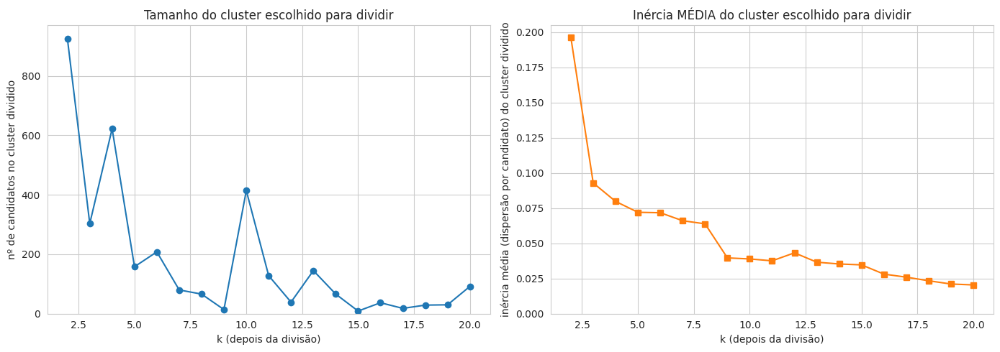

In [49]:
k_resultante = [h['k_resultante'] for h in historico_bisecting]
tamanho_escolhido = [h['pai_tamanho'] for h in historico_bisecting]
inercia_escolhida = [h['pai_inercia'] for h in historico_bisecting]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_resultante, tamanho_escolhido, marker='o')
axes[0].set_title('Tamanho do cluster escolhido para dividir')
axes[0].set_xlabel('k (depois da divisão)')
axes[0].set_ylabel('nº de candidatos no cluster dividido')
axes[0].set_ylim(bottom=0)
axes[0].grid(True)

axes[1].plot(k_resultante, inercia_escolhida, marker='s', color='tab:orange')
axes[1].set_title('Inércia MÉDIA do cluster escolhido para dividir')
axes[1].set_xlabel('k (depois da divisão)')
axes[1].set_ylabel('inércia média (dispersão por candidato) do cluster dividido')
axes[1].set_ylim(bottom=0)
axes[1].grid(True)

plt.tight_layout()
plt.show()

### 3) A árvore de divisões

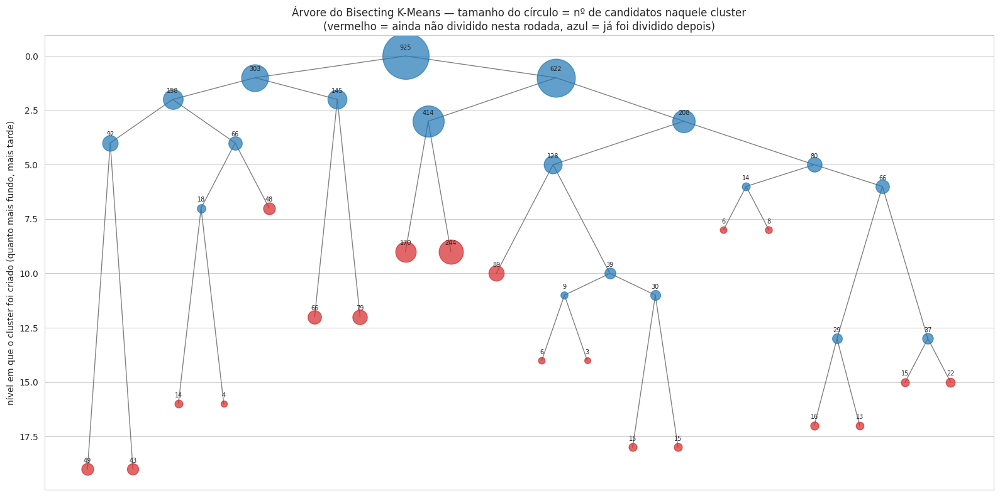

In [50]:
nos = {0: {'pai': None, 'nivel': 0, 'tamanho': X.shape[0], 'filhos': None}}
for h in historico_bisecting:
    nos[h['pai_id']]['filhos'] = [h['filho_a_id'], h['filho_b_id']]
    nos[h['filho_a_id']] = {'pai': h['pai_id'], 'nivel': h['k_resultante'] - 1, 'tamanho': h['filho_a_tamanho'], 'filhos': None}
    nos[h['filho_b_id']] = {'pai': h['pai_id'], 'nivel': h['k_resultante'] - 1, 'tamanho': h['filho_b_tamanho'], 'filhos': None}

# posição horizontal: folhas em ordem, nós internos = média dos filhos (layout clássico de árvore)
posicoes = {}
_x = [0]

def atribuir_x(no_id):
    filhos = nos[no_id]['filhos']
    if filhos is None:
        posicoes[no_id] = _x[0]
        _x[0] += 1
    else:
        for f in filhos:
            atribuir_x(f)
        posicoes[no_id] = sum(posicoes[f] for f in filhos) / len(filhos)

atribuir_x(0)

plt.figure(figsize=(16, 8))
for no_id, info in nos.items():
    if info['filhos']:
        for f in info['filhos']:
            plt.plot([posicoes[no_id], posicoes[f]], [info['nivel'], nos[f]['nivel']],
                      color='gray', linewidth=1, zorder=1)

for no_id, info in nos.items():
    e_folha = info['filhos'] is None
    plt.scatter(posicoes[no_id], info['nivel'], s=40 + info['tamanho'] * 3,
                color='tab:red' if e_folha else 'tab:blue', alpha=0.7, zorder=2)
    plt.text(posicoes[no_id], info['nivel'] - 0.3, str(info['tamanho']), ha='center', fontsize=7)

plt.gca().invert_yaxis()
plt.ylabel('nível em que o cluster foi criado (quanto mais fundo, mais tarde)')
plt.xticks([])
plt.title('Árvore do Bisecting K-Means — tamanho do círculo = nº de candidatos naquele cluster\n(vermelho = ainda não dividido nesta rodada, azul = já foi dividido depois)')
plt.tight_layout()
plt.show()

### 3.1) Animação: a árvore crescendo, nível a nível

A árvore estática fica poluída com muitos níveis de uma vez. Esta animação mostra **a mesma árvore**, mas revelando um nível por vez — a cada frame, um nó vermelho (folha ainda não dividida) "explode" em dois, e vira azul. As posições dos nós são as mesmas da árvore estática (calculadas uma vez só), então nada pula de lugar entre frames — só aparece o que é novo.

In [51]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

historico_por_k = {h['k_resultante']: h for h in historico_bisecting}
ks_disponiveis = list(range(1, max(historico_por_k) + 1))

def estado_arvore_no_k(k):
    """Quais nós já existem, e quais deles ainda são folha (não foram divididos), no frame k."""
    existentes = [nid for nid, info in nos.items() if info['nivel'] <= k - 1]
    set_existentes = set(existentes)
    folhas = []
    for nid in existentes:
        filhos = nos[nid]['filhos']
        if filhos is None or filhos[0] not in set_existentes:
            folhas.append(nid)
    return existentes, set(folhas)

max_nivel = max(info['nivel'] for info in nos.values())
x_min, x_max = min(posicoes.values()), max(posicoes.values())

fig, ax = plt.subplots(figsize=(16, 8))

def desenhar_frame_arvore(k):
    ax.clear()
    existentes, folhas = estado_arvore_no_k(k)
    set_existentes = set(existentes)

    for nid in existentes:
        filhos = nos[nid]['filhos']
        if filhos:
            for f in filhos:
                if f in set_existentes:
                    ax.plot([posicoes[nid], posicoes[f]], [nos[nid]['nivel'], nos[f]['nivel']],
                            color='gray', linewidth=1, zorder=1)

    for nid in existentes:
        info = nos[nid]
        cor = 'tab:red' if nid in folhas else 'tab:blue'
        ax.scatter(posicoes[nid], info['nivel'], s=40 + info['tamanho'] * 3, color=cor, alpha=0.7, zorder=2)
        ax.text(posicoes[nid], info['nivel'] - 0.3, str(info['tamanho']), ha='center', fontsize=7)

    ax.set_xlim(x_min - 1, x_max + 1)
    ax.set_ylim(max_nivel + 1, -1)  # eixo fixo e invertido (raiz no topo), sem "pulos" entre frames
    ax.set_xticks([])
    ax.set_ylabel('nível em que o cluster foi criado')
    if k in historico_por_k:
        h = historico_por_k[k]
        ax.set_title(f'Árvore do Bisecting K-Means — k={k}  (dividiu um cluster de {h["pai_tamanho"]} candidatos)')
    else:
        ax.set_title(f'Árvore do Bisecting K-Means — k={k} (estado inicial, 1 cluster só)')

anim = FuncAnimation(fig, desenhar_frame_arvore, frames=ks_disponiveis, interval=800, repeat=True)
plt.close(fig)  # evita mostrar também uma figura estática duplicada, além da animação
HTML(anim.to_jshtml())

> Se a animação demorar pra renderizar (muitos frames), aumente `interval` (ela roda mais devagar) ou reduza `k_max_bisecting` mais acima. Pra usar fora do notebook (ex.: num slide): `anim.save('arvore_bisecting.gif', writer='pillow')`.

### 4) Explorando diferentes k, na prática

Antes de fechar num único `k`, vale ver como os clusters realmente mudam à medida que o Bisecting K-Means continua dividindo — os dois gráficos anteriores (tamanho/inércia por nível, e a árvore) só sugerem isso de forma indireta. Reconstruímos a partição em `k=2, 3, 4` e `5`, mostrando a ficha resumida e o radar (reaproveitando a mesma `plot_radar` da Parte 1) de cada uma.

Como o Bisecting K-Means não calcula um centróide final único (ele só guarda os centros de cada divisão de 2 em 2, não da partição completa em k clusters), usamos a média das variáveis-driver padronizadas dentro de cada cluster como "centróide de fato" para o radar — mesma ideia de sempre.


--- Bisecting K-Means, k=2 ---


,qtd_candidatos,idade_media,anos_estudo_medio,patrimonio_mediano
Cluster A,622,49.40,14.20,"451,770.20"
Cluster B,303,44.10,12.80,0.00


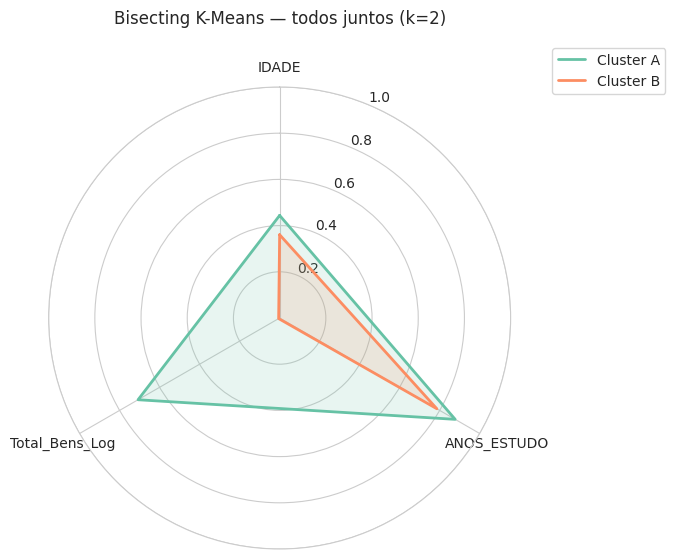

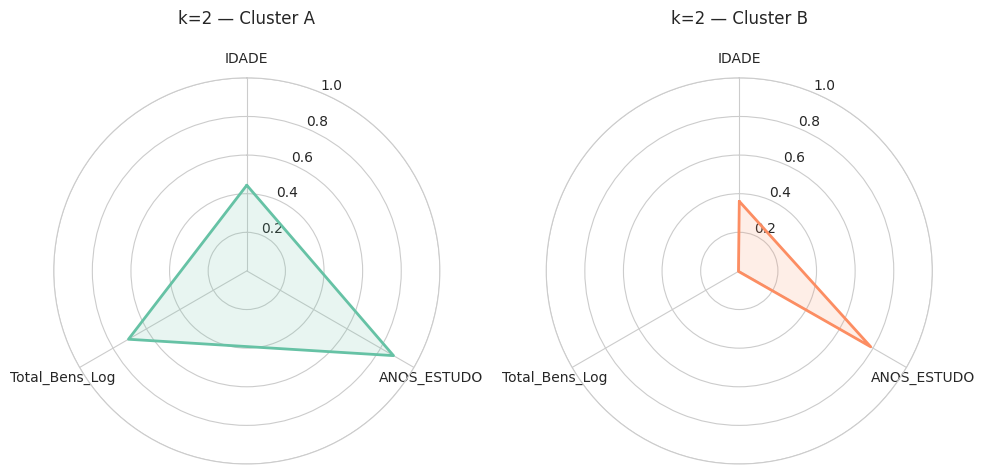

--- Bisecting K-Means, k=3 ---


,qtd_candidatos,idade_media,anos_estudo_medio,patrimonio_mediano
Cluster A,622,49.40,14.20,"451,770.20"
Cluster B,158,40.80,10.10,0.00
Cluster C,145,47.60,15.70,0.00


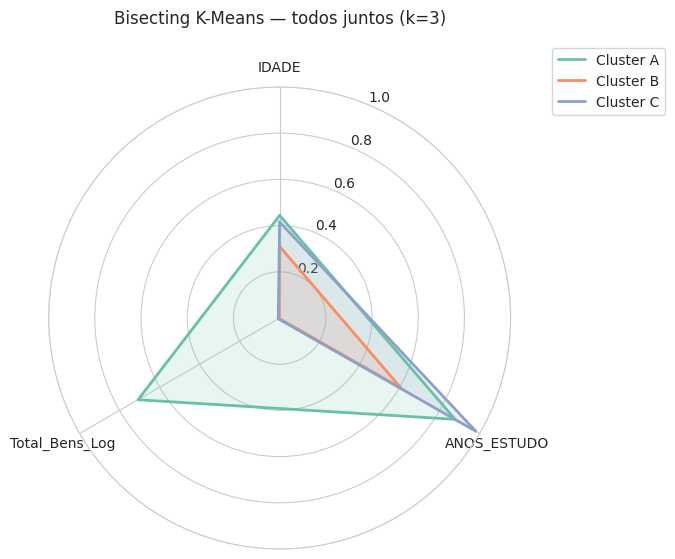

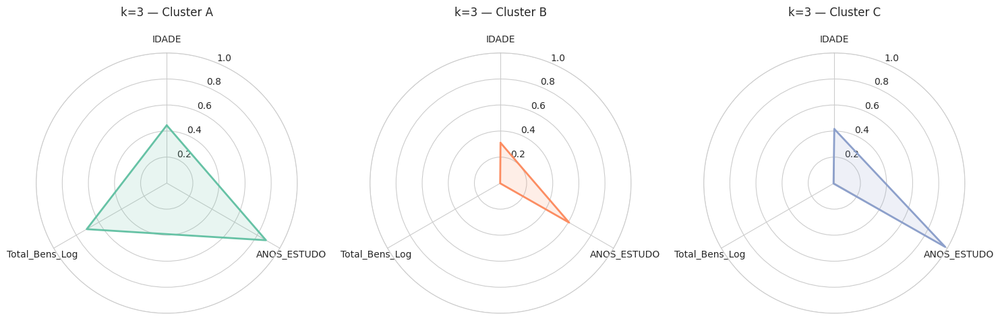

--- Bisecting K-Means, k=4 ---


,qtd_candidatos,idade_media,anos_estudo_medio,patrimonio_mediano
Cluster A,414,49.80,16.00,"581,180.20"
Cluster B,208,48.70,10.50,"240,050.00"
Cluster C,158,40.80,10.10,0.00
Cluster D,145,47.60,15.70,0.00


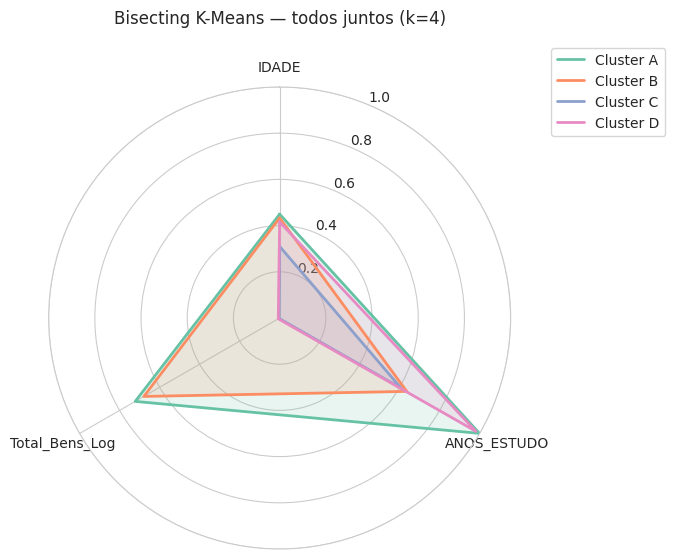

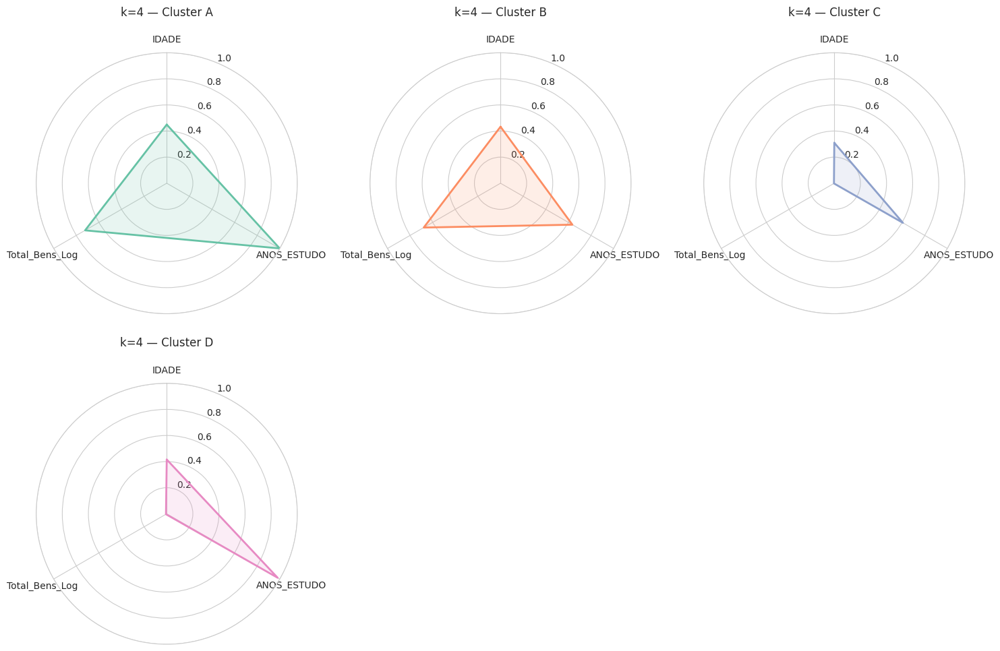

--- Bisecting K-Means, k=5 ---


,qtd_candidatos,idade_media,anos_estudo_medio,patrimonio_mediano
Prósperos,414,49.80,16.00,"581,180.20"
Batalhadores,208,48.70,10.50,"240,050.00"
Promissores,145,47.60,15.70,0.00
Recém-chegados,92,32.60,11.40,0.00
Desassistidos,66,52.40,8.30,0.00


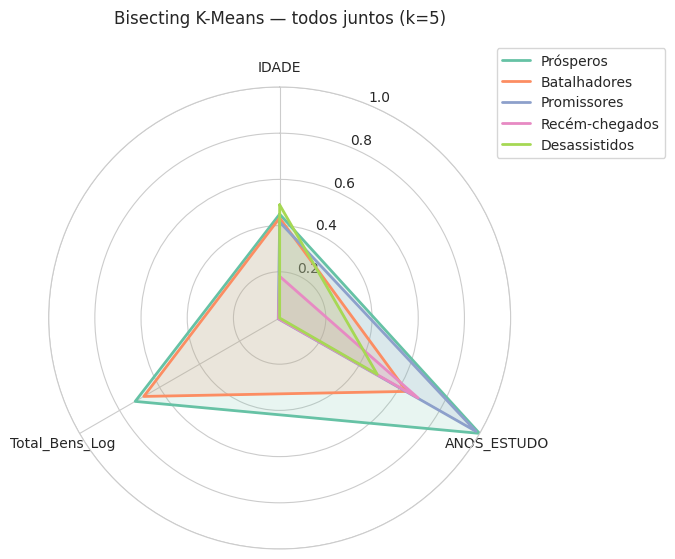

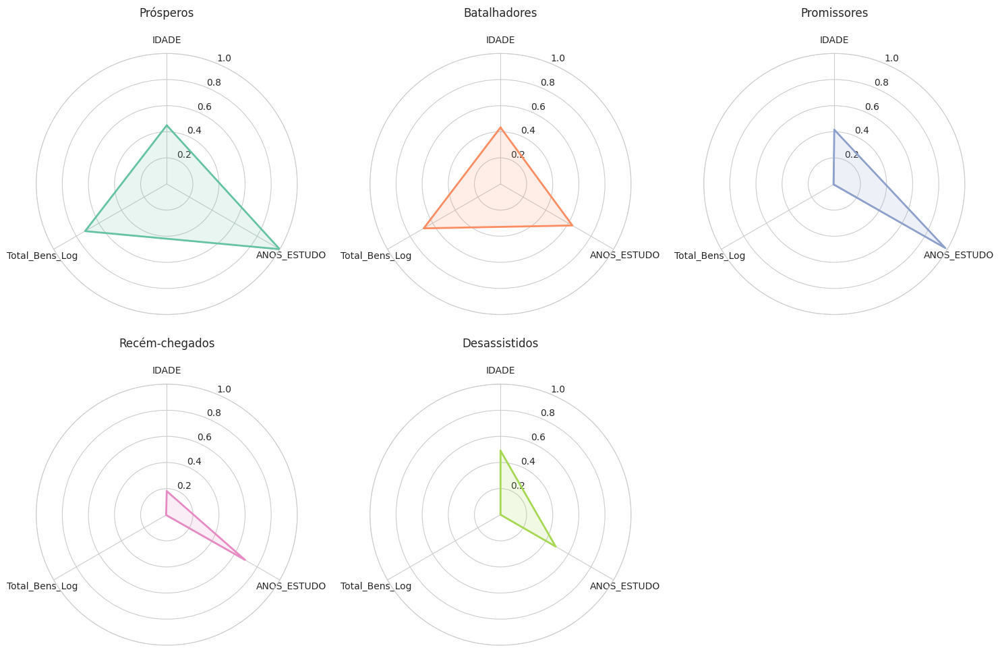

In [52]:
def clusters_bisecting_em_k(k):
    """Reconstrói a partição do Bisecting K-Means em k clusters, refazendo as divisões
    do histórico até esse ponto. Refazer o KMeans(n_clusters=2) é determinístico (mesma
    SEMENTE, mesmos dados de entrada), então reproduz exatamente a divisão já registrada —
    sem precisar guardar todos os índices no histórico."""
    clusters_no_k = {0: np.arange(X.shape[0])}
    for h in historico_bisecting:
        if h['k_resultante'] > k:
            break
        indices_pai = clusters_no_k.pop(h['pai_id'])
        km2 = KMeans(n_clusters=2, random_state=SEMENTE, n_init=10)
        labels2 = km2.fit_predict(X[indices_pai])
        clusters_no_k[h['filho_a_id']] = indices_pai[labels2 == 0]
        clusters_no_k[h['filho_b_id']] = indices_pai[labels2 == 1]

    # rótulos por ordem de tamanho (A = maior cluster, ...), mesma convenção usada em todo o notebook
    ids_por_tamanho = sorted(clusters_no_k, key=lambda cid: len(clusters_no_k[cid]), reverse=True)
    rotulos = np.empty(X.shape[0], dtype=object)
    for letra, cid in zip([chr(65 + i) for i in range(len(ids_por_tamanho))], ids_por_tamanho):
        rotulos[clusters_no_k[cid]] = letra
    return rotulos


for k in [2, 3, 4, 5]:
    rotulos_k = clusters_bisecting_em_k(k)
    clusters_k = sorted(set(rotulos_k))

    # No k final (=5) rotulamos com os NOMES dos clusters; nos k intermediários, letras.
    if k == 5:            # k=5 é o resultado final escolhido do projeto
        labels_k = [NOMES_CLUSTER_BISECTING[l] for l in clusters_k]
    else:
        labels_k = [f'Cluster {l}' for l in clusters_k]
    cores_k = dict(zip(labels_k, sns.color_palette('Set2', n_colors=k)))

    print(f"--- Bisecting K-Means, k={k} ---")
    resumo_k = pd.DataFrame({
        'cluster': rotulos_k,
        'IDADE': df_cluster['IDADE'].values,
        'ANOS_ESTUDO': df_cluster['ANOS_ESTUDO'].values,
        'Total_Bens': df_cluster['Total_Bens'].values,
    }).groupby('cluster').agg(
        qtd_candidatos=('IDADE', 'count'),
        idade_media=('IDADE', 'mean'),
        anos_estudo_medio=('ANOS_ESTUDO', 'mean'),
        patrimonio_mediano=('Total_Bens', 'median'),
    ).round(1)
    resumo_k.index = labels_k   # nomes no k=5, letras nos demais
    display(resumo_k)

    centroides_k_norm = np.array([X[rotulos_k == cl].mean(axis=0) for cl in clusters_k])

    fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))
    plot_radar(ax, centroides_k_norm, colunas_driver, labels_k, cores_k, f'Bisecting K-Means — todos juntos (k={k})')
    ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1))
    plt.show()

    ncols = min(k, 3)
    nrows = -(-k // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 5 * nrows), subplot_kw=dict(polar=True))
    axes = axes.flatten() if k > 1 else [axes]
    for i, nome in enumerate(labels_k):
        titulo = nome if k == 5 else f'k={k} — {nome}'
        plot_radar(axes[i], [centroides_k_norm[i]], colunas_driver, [nome], cores_k, titulo)
    for j in range(len(labels_k), len(axes)):
        fig.delaxes(axes[j])
    plt.tight_layout()
    plt.show()


### 5) Escolhendo k final e extraindo o resultado

Neste trabalho fixamos **k = 5** para obter uma **segmentação socioeconômica mais fina** dos candidatos. As métricas do K-Means (seção V2.2) favorecem k menores — a silhouette é maior em k=2–3 e cai suavemente até k=5 (~0,41 no Bisecting). Ou seja, k=5 troca um pouco de coesão estatística por **maior granularidade interpretativa**: separa os candidatos *com* patrimônio em dois níveis de escolaridade (superior e médio) e os *sem* patrimônio em três perfis distintos (escolarizados, jovens e de baixa escolaridade). É uma escolha de negócio — priorizar perfis acionáveis — assumida explicitamente, e não uma leitura automática das métricas.

In [53]:
k_bisecting = 5  # ajuste conforme os gráficos das seções anteriores, se quiser

df_cluster['cluster_bisecting'] = clusters_bisecting_em_k(k_bisecting)
df_cluster['cluster_bisecting'].value_counts().sort_index()


cluster_bisecting
A    414
B    208
C    145
D     92
E     66
Name: count, dtype: int64

### 6) Comparando com o K-Means (Versão 2)

Silhouette — K-Means (V2, k=5):        0.365
Silhouette — Bisecting K-Means (k=5): 0.414


,qtd_candidatos,idade_media,anos_estudo_medio,patrimonio_mediano
cluster_bisecting,,,,
A,414,49.80,16.00,"581,180.20"
B,208,48.70,10.50,"240,050.00"
C,145,47.60,15.70,0.00
D,92,32.60,11.40,0.00
E,66,52.40,8.30,0.00


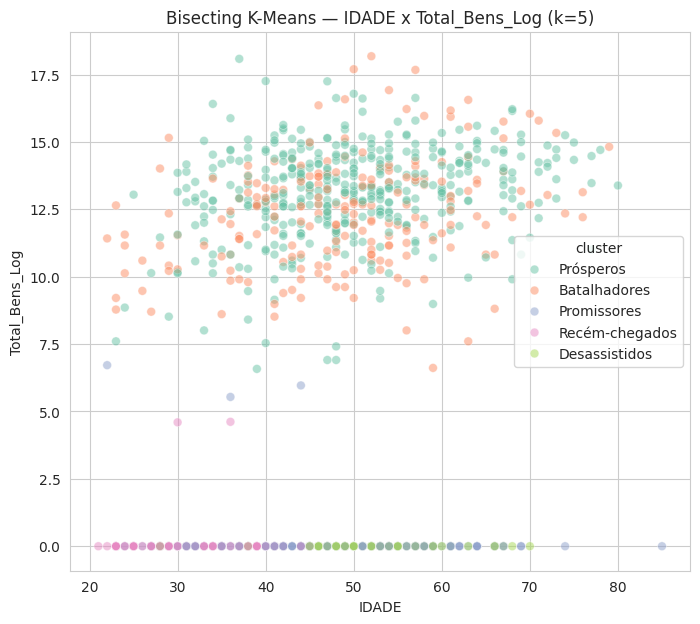

In [54]:
labels_bisecting = df_cluster['cluster_bisecting'].values
print(f"Silhouette — K-Means (V2, k={k_final}):        {silhouette_score(X, df_cluster['cluster']):.3f}")
print(f"Silhouette — Bisecting K-Means (k={k_bisecting}): {silhouette_score(X, labels_bisecting):.3f}")

resumo_bisecting = df_cluster.groupby('cluster_bisecting').agg(
    qtd_candidatos=('SQ_CANDIDATO', 'count'),
    idade_media=('IDADE', 'mean'),
    anos_estudo_medio=('ANOS_ESTUDO', 'mean'),
    patrimonio_mediano=('Total_Bens', 'median'),
).round(1)
display(resumo_bisecting)

clusters_bisecting_ordenados = sorted(df_cluster['cluster_bisecting'].unique())
nomes_bisecting_ord = [NOMES_CLUSTER_BISECTING[l] for l in clusters_bisecting_ordenados]
cores_bisecting = dict(zip(clusters_bisecting_ordenados, sns.color_palette('Set2', n_colors=len(clusters_bisecting_ordenados))))
cores_nome = dict(zip(nomes_bisecting_ord, sns.color_palette('Set2', n_colors=len(nomes_bisecting_ord))))

hue_nome = df_cluster['cluster_bisecting'].map(NOMES_CLUSTER_BISECTING)
plt.figure(figsize=(8, 7))
sns.scatterplot(data=df_cluster, x='IDADE', y='Total_Bens_Log', hue=hue_nome, hue_order=nomes_bisecting_ord, palette=cores_nome, alpha=0.5, s=40)
plt.legend(title='cluster')
plt.title(f'Bisecting K-Means — IDADE x Total_Bens_Log (k={k_bisecting})')
plt.show()

**Interpretação:** compare o `resumo_bisecting` com o `resumo_driver` do K-Means e a silhouette dos dois. Se os grupos ficarem parecidos, é um bom sinal de que a estrutura é real (dois algoritmos diferentes concordando); se ficarem bem diferentes, vale a pena entender por quê — o K-Means busca uma solução global pra todo o `k` de uma vez, enquanto o Bisecting constrói de forma incremental, e pode ficar "preso" a decisões tomadas em níveis anteriores.

Agora aplicamos de verdade o mesmo kit de nomeação da Parte 1 (ficha técnica, heatmap de desvio, rascunho automático) para os clusters do Bisecting — e ampliamos a leitura demográfica com partido e UF, que a Parte 1 não cobriu.


### 7) Ficha técnica por cluster (Bisecting K-Means)


In [55]:
ficha_bisecting = df_cluster.groupby('cluster_bisecting').agg(
    qtd=('SQ_CANDIDATO', 'count'),
    idade_media=('IDADE', 'mean'),
    anos_estudo_medio=('ANOS_ESTUDO', 'mean'),
    patrimonio_medio=('Total_Bens', 'mean'),
    patrimonio_mediano=('Total_Bens', 'median'),
).round(1)
ficha_bisecting['pct_do_total'] = (ficha_bisecting['qtd'] / ficha_bisecting['qtd'].sum() * 100).round(1)
ficha_bisecting['pct_sem_bens'] = df_cluster.groupby('cluster_bisecting')['Total_Bens'].apply(
    lambda s: (s == 0).mean() * 100
).round(1)

for col in colunas_perfil:
    ficha_bisecting[f'{col}_predominante'] = df_cluster.groupby('cluster_bisecting')[col].agg(lambda s: s.mode().iat[0])
    ficha_bisecting[f'{col}_pct'] = df_cluster.groupby('cluster_bisecting')[col].apply(
        lambda s: (s == s.mode().iat[0]).mean() * 100
    ).round(1)

ficha_bisecting


,qtd,idade_media,anos_estudo_medio,patrimonio_medio,patrimonio_mediano,pct_do_total,pct_sem_bens,DS_GENERO_predominante,DS_GENERO_pct,DS_COR_RACA_predominante,DS_COR_RACA_pct,DS_ESTADO_CIVIL_predominante,DS_ESTADO_CIVIL_pct
cluster_bisecting,,,,,,,,,,,,,
A,414,49.80,16.00,"1,661,785.60","581,180.20",44.80,0.00,MASCULINO,63.00,PARDA,45.20,CASADO(A),56.50
B,208,48.70,10.50,"1,922,037.20","240,050.00",22.50,0.00,MASCULINO,68.80,PARDA,64.90,CASADO(A),46.60
C,145,47.60,15.70,10.10,0.00,15.70,97.90,FEMININO,51.70,PARDA,55.20,CASADO(A),42.10
D,92,32.60,11.40,2.20,0.00,9.90,97.80,MASCULINO,51.10,PARDA,52.20,SOLTEIRO(A),76.10
E,66,52.40,8.30,0.00,0.00,7.10,100.00,MASCULINO,59.10,PARDA,59.10,SOLTEIRO(A),51.50


### 8) O que destaca cada cluster (desvio em relação à média geral)


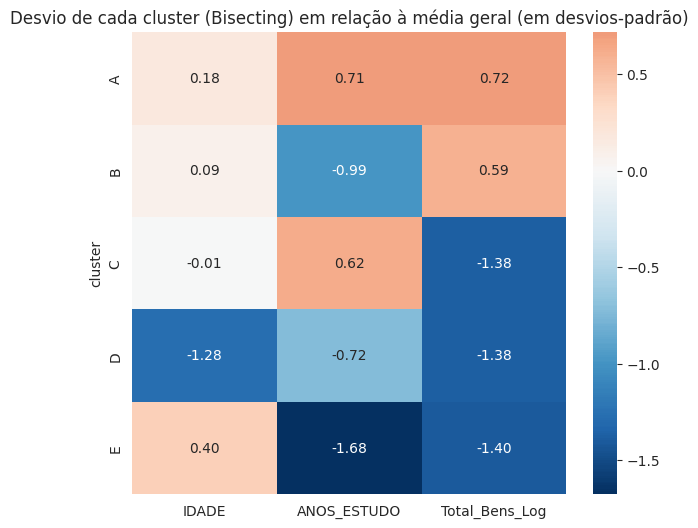

In [56]:
medias_cluster_bisecting = df_cluster.groupby('cluster_bisecting')[colunas_driver].mean()
zscore_cluster_bisecting = (medias_cluster_bisecting - medias_gerais) / desvios_gerais

plt.figure(figsize=(7, 1 + k_bisecting))
sns.heatmap(zscore_cluster_bisecting, annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Desvio de cada cluster (Bisecting) em relação à média geral (em desvios-padrão)')
plt.xlabel('')
plt.ylabel('cluster')
plt.show()


In [57]:
NOMES_CLUSTER_BISECTING = {
    'A': 'Prósperos',
    'B': 'Batalhadores',
    'C': 'Promissores',
    'D': 'Recém-chegados',
    'E': 'Desassistidos',
}
df_cluster['nome_cluster_bisecting'] = df_cluster['cluster_bisecting'].map(NOMES_CLUSTER_BISECTING)
_ordem_nomes = [NOMES_CLUSTER_BISECTING[l] for l in sorted(NOMES_CLUSTER_BISECTING)]  # A..E (ordem de tamanho)
df_cluster['nome_cluster_bisecting'] = pd.Categorical(df_cluster['nome_cluster_bisecting'], categories=_ordem_nomes, ordered=True)
df_cluster[['cluster_bisecting', 'nome_cluster_bisecting']].value_counts().sort_index()

cluster_bisecting  nome_cluster_bisecting
A                  Prósperos                 414
B                  Batalhadores              208
C                  Promissores               145
D                  Recém-chegados             92
E                  Desassistidos              66
Name: count, dtype: int64

In [58]:
nomes_bisecting_ordenados = [NOMES_CLUSTER_BISECTING[c] for c in clusters_bisecting_ordenados]
cores_nome_bisecting = {NOMES_CLUSTER_BISECTING[c]: cor for c, cor in cores_bisecting.items()}


### 9) Composição demográfica: gênero, cor/raça, estado civil


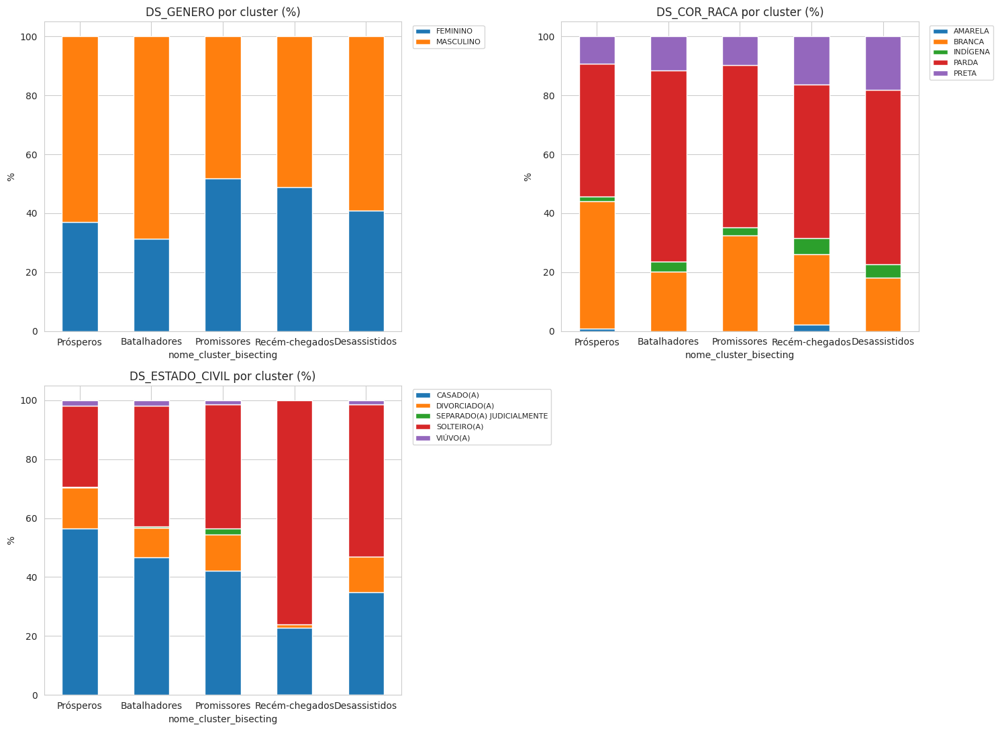

In [59]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
axes = axes.flatten()

for i, col in enumerate(colunas_perfil):
    pd.crosstab(df_cluster['nome_cluster_bisecting'], df_cluster[col], normalize='index').mul(100).plot(
        kind='bar', stacked=True, ax=axes[i]
    )
    axes[i].set_title(f'{col} por cluster (%)')
    axes[i].set_ylabel('%')
    axes[i].tick_params(axis='x', rotation=0)
    axes[i].legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


### Direção inversa: onde cada grupo demográfico está distribuído entre os clusters

Até aqui perguntamos "dentro do cluster X, qual a composição por gênero/cor-raça/estado civil?". Agora invertemos: **de todos os candidatos de um determinado grupo, em qual cluster eles estão?** Mesma tabela de contingência, só trocando o que normaliza — mesma lógica já usada na Parte 1.


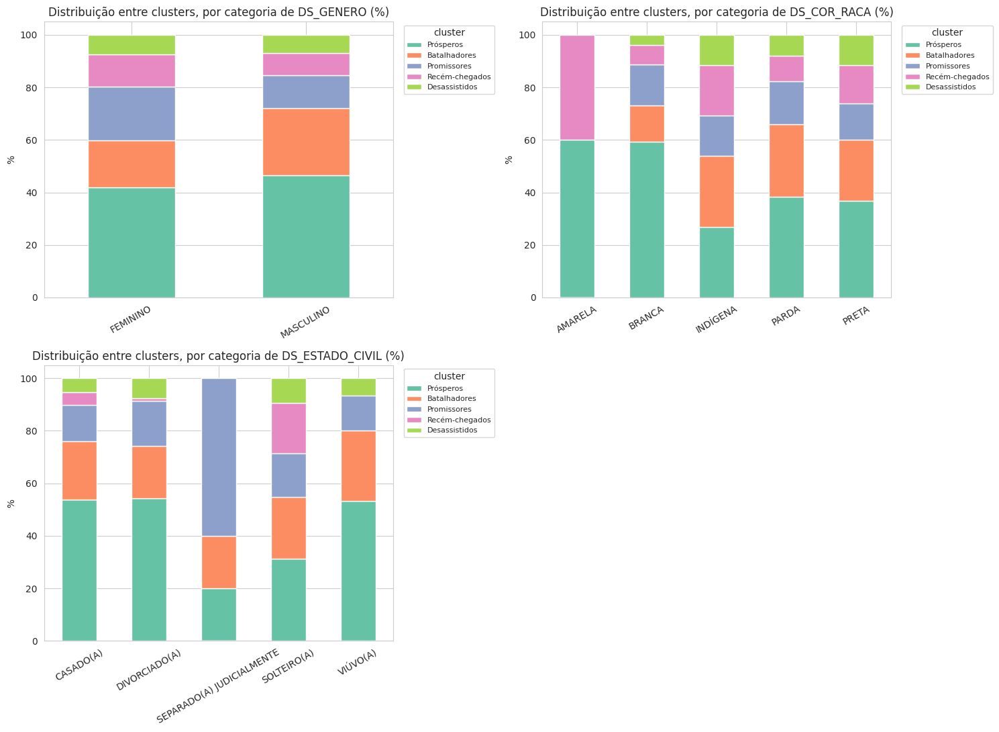

In [60]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
axes = axes.flatten()

for i, col in enumerate(colunas_perfil):
    tabela = pd.crosstab(df_cluster[col], df_cluster['nome_cluster_bisecting'], normalize='index').mul(100)
    tabela = tabela[nomes_bisecting_ordenados]  # garante a mesma ordem de colunas de cores_nome_bisecting
    tabela.plot(kind='bar', stacked=True, ax=axes[i], color=[cores_nome_bisecting[c] for c in tabela.columns])
    axes[i].set_title(f'Distribuição entre clusters, por categoria de {col} (%)')
    axes[i].set_ylabel('%')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=30)
    axes[i].legend(title='cluster', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


### 10) Partidos: quais legendas dominam cada cluster

A Parte 1 não olhou partido — mas como boa parte do que diferencia os clusters aqui é "declarou patrimônio ou não", vale ver se isso também aparece na legenda: candidaturas de partidos pequenos costumam ser mais simbólicas, com menos estrutura (e menos bens declarados) por trás.


In [61]:
for nome in nomes_bisecting_ordenados:
    sub = df_cluster[df_cluster['nome_cluster_bisecting'] == nome]
    top5 = (sub['SG_PARTIDO'].value_counts(normalize=True) * 100).round(1).head(5)
    print(f"{nome} ({len(sub)} candidatos) — partidos mais frequentes:")
    for partido, pct in top5.items():
        print(f"  {partido}: {pct:.1f}%")
    print()


Prósperos (414 candidatos) — partidos mais frequentes:
  PL: 11.4%
  REPUBLICANOS: 9.9%
  MDB: 9.4%
  PODE: 7.5%
  UNIÃO: 7.5%

Batalhadores (208 candidatos) — partidos mais frequentes:
  PODE: 9.6%
  DC: 8.7%
  PSB: 7.7%
  AVANTE: 7.2%
  PT: 6.7%

Promissores (145 candidatos) — partidos mais frequentes:
  NOVO: 15.2%
  PDT: 9.0%
  PODE: 9.0%
  SOLIDARIEDADE: 9.0%
  PSOL: 6.2%

Recém-chegados (92 candidatos) — partidos mais frequentes:
  MISSÃO: 20.7%
  NOVO: 12.0%
  DC: 7.6%
  PSOL: 7.6%
  PODE: 5.4%

Desassistidos (66 candidatos) — partidos mais frequentes:
  PSOL: 18.2%
  PDT: 16.7%
  DC: 15.2%
  NOVO: 6.1%
  SOLIDARIEDADE: 6.1%



### 11) Existe um padrão regional?

Esta seção só roda na visão **Brasil** (quando `UF = None`) — mesma lógica da Parte 1. Com 27 UFs, uma tabela crua de contingência é difícil de escanear — preferimos duas pizzas: uma olhando de dentro de cada cluster ("desse grupo, de onde vêm os candidatos?"), outra de dentro de cada UF ("nesse estado, qual a mistura de clusters?").


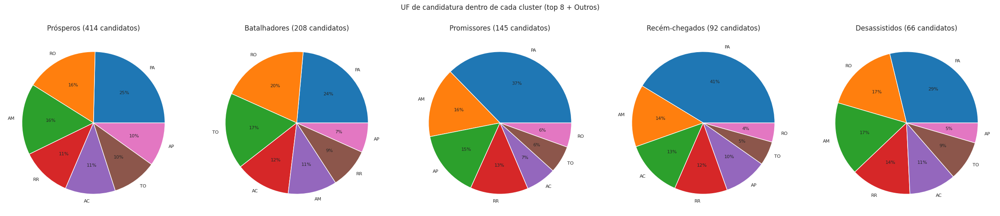

In [62]:
def contagem_top_n(serie, top_n=8, rotulo_outros='Outros'):
    """Série de contagens com só as `top_n` categorias mais frequentes; o resto vira uma
    única fatia `rotulo_outros—pra pizza não virar um mosaico de fatias minúsculas
    (relevante aqui: SG_UF tem 27 valores possíveis)."""
    contagem = serie.value_counts()
    if len(contagem) <= top_n:
        return contagem
    principais = contagem.head(top_n).copy()
    resto = contagem.iloc[top_n:].sum()
    if resto > 0:
        principais[rotulo_outros] = resto
    return principais


if mostrar_por_uf:
    fig, axes = plt.subplots(1, len(nomes_bisecting_ordenados), figsize=(5 * len(nomes_bisecting_ordenados), 5))
    for ax, nome in zip(axes, nomes_bisecting_ordenados):
        sub = df_cluster[df_cluster['nome_cluster_bisecting'] == nome]
        contagem = contagem_top_n(sub['SG_UF'], top_n=8)
        ax.pie(contagem, labels=contagem.index, autopct='%1.0f%%', textprops={'fontsize': 8})
        ax.set_title(f'{nome} ({len(sub)} candidatos)')
    plt.suptitle('UF de candidatura dentro de cada cluster (top 8 + Outros)', y=1.05)
    plt.tight_layout()
    plt.show()
else:
    print(f"UF = {UF!r} — seção não se aplica (dados já filtrados para uma única UF).")


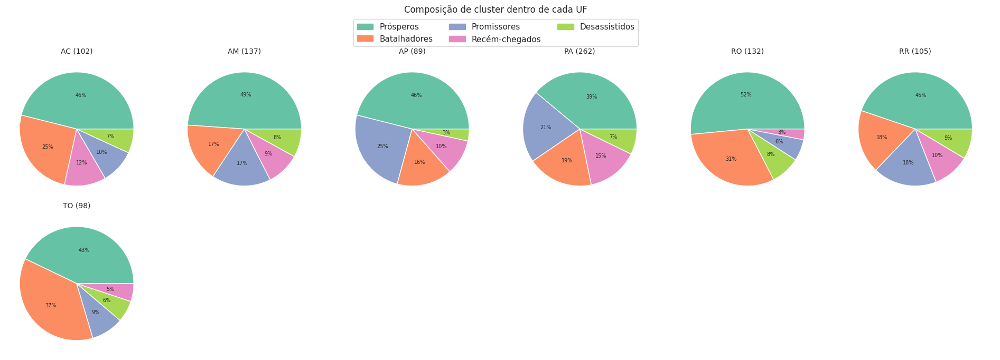

In [63]:
if mostrar_por_uf:
    ufs_ordenadas = sorted(df_cluster['SG_UF'].unique())
    ncols = 6
    nrows = -(-len(ufs_ordenadas) // ncols)

    fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 3.2 * nrows))
    axes = axes.flatten()

    for ax, uf in zip(axes, ufs_ordenadas):
        sub = df_cluster[df_cluster['SG_UF'] == uf]
        contagem = sub['nome_cluster_bisecting'].value_counts()
        cores_fatias = [cores_nome_bisecting[nome] for nome in contagem.index]
        ax.pie(contagem, labels=None, autopct=lambda p: f'{p:.0f}%' if p > 0 else '',
               colors=cores_fatias, textprops={'fontsize': 7})
        ax.set_title(f'{uf} ({len(sub)})', fontsize=10)

    for ax in axes[len(ufs_ordenadas):]:
        ax.axis('off')

    handles = [plt.Rectangle((0, 0), 1, 1, color=cores_nome_bisecting[nome]) for nome in nomes_bisecting_ordenados]
    fig.legend(handles, nomes_bisecting_ordenados, loc='upper center', bbox_to_anchor=(0.5, 1.03), ncol=3, fontsize=11)
    plt.suptitle('Composição de cluster dentro de cada UF', y=1.06)
    plt.tight_layout()
    plt.show()
else:
    print(f"UF = {UF!r} — seção não se aplica (dados já filtrados para uma única UF).")


### 12) Rascunho automático — editem à vontade


In [64]:
for cl in clusters_bisecting_ordenados:
    linha = ficha_bisecting.loc[cl]
    print(f"{NOMES_CLUSTER_BISECTING[cl]} (Cluster {cl}) — {linha['qtd']:.0f} candidatos, {linha['pct_do_total']:.0f}% do total")
    print(f"  Idade média: {linha['idade_media']:.0f} anos | Escolaridade média: {linha['anos_estudo_medio']:.0f} anos de estudo")
    print(f"  Patrimônio mediano: R$ {linha['patrimonio_mediano']:,.0f} | {linha['pct_sem_bens']:.0f}% declaram patrimônio zero")
    for col in colunas_perfil:
        print(f"  Predominância em {col}: {linha[f'{col}_predominante']} ({linha[f'{col}_pct']:.0f}%)")
    print(f"  >> Nome atribuído: {NOMES_CLUSTER_BISECTING[cl]}")
    print()


Prósperos (Cluster A) — 414 candidatos, 45% do total
  Idade média: 50 anos | Escolaridade média: 16 anos de estudo
  Patrimônio mediano: R$ 581,180 | 0% declaram patrimônio zero
  Predominância em DS_GENERO: MASCULINO (63%)
  Predominância em DS_COR_RACA: PARDA (45%)
  Predominância em DS_ESTADO_CIVIL: CASADO(A) (56%)
  >> Nome atribuído: Prósperos

Batalhadores (Cluster B) — 208 candidatos, 22% do total
  Idade média: 49 anos | Escolaridade média: 10 anos de estudo
  Patrimônio mediano: R$ 240,050 | 0% declaram patrimônio zero
  Predominância em DS_GENERO: MASCULINO (69%)
  Predominância em DS_COR_RACA: PARDA (65%)
  Predominância em DS_ESTADO_CIVIL: CASADO(A) (47%)
  >> Nome atribuído: Batalhadores

Promissores (Cluster C) — 145 candidatos, 16% do total
  Idade média: 48 anos | Escolaridade média: 16 anos de estudo
  Patrimônio mediano: R$ 0 | 98% declaram patrimônio zero
  Predominância em DS_GENERO: FEMININO (52%)
  Predominância em DS_COR_RACA: PARDA (55%)
  Predominância em DS_E

### Nomes finais dos clusters (Bisecting K-Means, k=5)

A partir da ficha técnica e das composições acima, os **cinco** clusters se leem, por perfil socioeconômico, assim (Deputados Federais da Região Norte, 925 candidatos):

- **A — Prósperos** (414; 44,8%): idade ~50, **superior completo** (~16 anos), todos com patrimônio declarado (mediana ~R$ 581 mil), masculino (63%); partidos de peso (PL, REPUBLICANOS, MDB).
- **B — Batalhadores** (208; 22,5%): idade ~49, **ensino médio** (~10 anos), com patrimônio (mediana ~R$ 240 mil), masculino (69%); PODE, DC, PSB.
- **C — Promissores** (145; 15,7%): idade ~48, **superior** (~16 anos), ~98% **sem** patrimônio, leve predominância feminina (52%); NOVO, PDT, PODE.
- **D — Recém-chegados** (92; 9,9%): o mais jovem (~33 anos), ensino médio, ~98% sem patrimônio, maioria solteira (76%); MISSÃO, NOVO, PSOL.
- **E — Desassistidos** (66; 7,1%): idade ~52, **ensino fundamental** (~8 anos), 100% sem patrimônio; PSOL, PDT, DC.

> **Ressalva:** o principal eixo que separa A/B de C/D/E é "declarou algum patrimônio" vs. "declarou zero" — muito correlacionado com pertencer a um partido estruturado; a escolaridade e a idade é que dividem cada um desses blocos nos cinco perfis.

In [65]:
# nomes já aplicados mais acima (logo depois da seção 8), reaproveitados em toda a análise
# demográfica/partidária/regional desta parte — aqui só o recap final:
df_cluster[['cluster_bisecting', 'nome_cluster_bisecting']].value_counts().sort_index()


cluster_bisecting  nome_cluster_bisecting
A                  Prósperos                 414
B                  Batalhadores              208
C                  Promissores               145
D                  Recém-chegados             92
E                  Desassistidos              66
Name: count, dtype: int64

---
## Fechamento e próximos passos

Duas famílias de algoritmo até aqui:

- **K-Means (Parte 1)**, em duas rodadas — mostrando o efeito de tratar uma variável ordinal como intervalar, e de usar mais de uma métrica pra escolher `k`.
- **Bisecting K-Means (Parte 2)** — construção incremental e visual, com uma árvore mostrando a ordem das divisões, um critério de parada baseado em quando parar de dividir clusters grandes, e os **5** clusters finais (k=5) nomeados por perfil socioeconômico: **Prósperos**, **Batalhadores**, **Promissores**, **Recém-chegados** e **Desassistidos**.

Continua em `02_clusterizacao_outros.ipynb`: **DBSCAN** e **clusterização hierárquica**, reaproveitando a mesma base e a mesma pergunta de negócio.

---

# Fase 2b — DBSCAN e Clusterização Hierárquica

Mesma base e pergunta, com dois outros algoritmos (DBSCAN e hierárquico/Ward), para comparar partições.

# Fase 2b — Clusterização (continuação): DBSCAN e Hierárquico

## Retomando a pergunta de negócio

> **Existem perfis demográfico-sociais distintos entre os candidatos, nas Eleições 2026? Combinando idade, escolaridade e patrimônio declarado, os candidatos se agrupam em segmentos claramente diferentes — e, se sim, como esses segmentos se distribuem em termos de gênero, cor/raça e estado civil?**

Este notebook continua o `02_clusterizacao.ipynb`, reaproveitando **a mesma base, as mesmas variáveis-driver e a mesma preparação (Versão 2)** — só troca o algoritmo. Lá vimos K-Means e Bisecting K-Means, dois algoritmos "baseados em centróide": vocês escolhem (ou estimam) `k` de antemão, e cada cluster é definido pela distância até um centro.

Aqui entram duas famílias bem diferentes:

- **DBSCAN** (baseado em densidade): não pede `k` — define cluster como uma região "densa" de pontos, separada por regiões "vazias". Consegue achar clusters de formato arbitrário (não só "bolhas" convexas como o K-Means) e marca explicitamente pontos isolados como **ruído**, em vez de forçá-los para dentro do cluster mais próximo.
- **Clusterização Hierárquica (HCLUST/aglomerativa)**: não escolhe um único `k` — constrói uma **árvore inteira** de agrupamentos, do nível "cada candidato é seu próprio cluster" até "todo mundo é um cluster só". Vocês cortam essa árvore (o dendrograma) na altura que quiserem, o que dá muito mais flexibilidade pra explorar diferentes granularidades sem re-treinar nada.

Mesmas variáveis-driver de antes: `IDADE`, `ANOS_ESTUDO` (anos de estudo equivalentes) e `Total_Bens_Log`. Mesmas variáveis de perfil, pra descrever os clusters depois de prontos: `DS_GENERO`, `DS_COR_RACA`, `DS_ESTADO_CIVIL`.


## Configuração

Use os **mesmos valores** que você usou na Fase 0/1/2, para carregar o arquivo certo.


In [66]:
CARGO = "DEPUTADO FEDERAL"
# Recorte deste trabalho: Deputados Federais da REGIÃO NORTE (7 UFs).
# O molde original do professor usa uma única UF (string) ou None (Brasil inteiro).
# Aqui estendemos a configuração: UF pode ser uma LISTA de siglas -> filtramos com .isin(...).
UF = ["AC", "AM", "AP", "PA", "RO", "RR", "TO"]   # None = Brasil; "SP" = uma UF; lista = região
NOME_RECORTE = "NORTE"     # rótulo usado no nome do arquivo quando UF é uma lista/região
ANO_ELEICAO = 2026

# Seções de comparação entre UFs: no molde do professor só rodavam na visão Brasil (UF = None).
# Como agora o recorte é uma região com 7 UFs, faz sentido rodá-las para comparar os estados.
mostrar_por_uf = (UF is None) or (isinstance(UF, (list, tuple, set)) and len(UF) > 1)

## Preparando a base

Repetimos aqui a preparação da **Versão 2** do `02_clusterizacao.ipynb` — outliers de patrimônio removidos por IQR, escolaridade convertida em anos de estudo equivalentes, e as 3 variáveis-driver padronizadas com `MinMaxScaler` — para que este notebook rode de forma independente e os resultados continuem comparáveis com o K-Means / Bisecting K-Means já vistos.


In [67]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

sns.set_style("whitegrid")
pd.set_option('display.max_columns', None)

SEMENTE = 42
np.random.seed(SEMENTE)  # mesmo racional de reprodutibilidade defensiva do notebook anterior

nome_uf = 'BRASIL' if UF is None else (NOME_RECORTE if isinstance(UF, (list, tuple, set)) else UF)
nome_cargo = CARGO.replace(' ', '_')
arquivo = f"dados/candidatos_{nome_cargo}_{nome_uf}_{ANO_ELEICAO}.csv"

df = pd.read_csv(arquivo)
print(f"Carregado: {arquivo}  ->  {df.shape[0]} candidatos, {df.shape[1]} colunas")
df.head()


Carregado: dados/candidatos_DEPUTADO_FEDERAL_NORTE_2026.csv  ->  925 candidatos, 59 colunas


,DT_GERACAO,HH_GERACAO,ANO_ELEICAO,CD_TIPO_ELEICAO,NM_TIPO_ELEICAO,NR_TURNO,CD_ELEICAO,DS_ELEICAO,DT_ELEICAO,TP_ABRANGENCIA,SG_UF,SG_UE,NM_UE,CD_CARGO,DS_CARGO,SQ_CANDIDATO,NR_CANDIDATO,NM_CANDIDATO,NM_URNA_CANDIDATO,NM_SOCIAL_CANDIDATO,NR_CPF_CANDIDATO,DS_EMAIL,CD_SITUACAO_CANDIDATURA,DS_SITUACAO_CANDIDATURA,TP_AGREMIACAO,NR_PARTIDO,SG_PARTIDO,NM_PARTIDO,NR_FEDERACAO,NM_FEDERACAO,SG_FEDERACAO,DS_COMPOSICAO_FEDERACAO,SQ_COLIGACAO,NM_COLIGACAO,DS_COMPOSICAO_COLIGACAO,SG_UF_NASCIMENTO,DT_NASCIMENTO,NR_TITULO_ELEITORAL_CANDIDATO,CD_GENERO,DS_GENERO,CD_GRAU_INSTRUCAO,DS_GRAU_INSTRUCAO,CD_ESTADO_CIVIL,DS_ESTADO_CIVIL,CD_COR_RACA,DS_COR_RACA,CD_OCUPACAO,DS_OCUPACAO,CD_SIT_TOT_TURNO,DS_SIT_TOT_TURNO,BENS IMÓVEIS,BENS MÓVEIS,DINHEIRO,INVESTIMENTOS RENDA FIXA,INVESTIMENTOS RENDA VARIÁVEL,OUTROS BENS,Total_Bens,Total_Bens_Log,IDADE
0,23/08/2026,19:30:42,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,AC,AC,ACRE,6,DEPUTADO FEDERAL,10002532416,1567,ADGICLEIA DOS SANTOS GUIMARÃES,DR.. KEL GUIMARÃES,#NULO,1138048224,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,15,MDB,MOVIMENTO DEMOCRÁTICO BRASILEIRO,-1,#NULO,#NULO,#NULO,10001800109,PARTIDO ISOLADO,MDB,AC,1991-07-22,5979012437,4,FEMININO,8,SUPERIOR COMPLETO,3,CASADO(A),3,PARDA,111,MÉDICO,-1,#NULO,0.00,"60,000.00",0.00,0.00,0.00,0.00,"60,000.00",11.00,35
1,23/08/2026,19:30:42,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,AC,AC,ACRE,6,DEPUTADO FEDERAL,10002532417,1511,FÁBIO DE ARAÚJO FREITAS,FÁBIO ARAÚJO,#NULO,52152901215,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,15,MDB,MOVIMENTO DEMOCRÁTICO BRASILEIRO,-1,#NULO,#NULO,#NULO,10001800109,PARTIDO ISOLADO,MDB,AC,1981-06-25,3405502488,2,MASCULINO,8,SUPERIOR COMPLETO,3,CASADO(A),3,PARDA,278,VEREADOR,-1,#NULO,0.00,"266,330.00",0.00,"50,000.00",0.00,0.00,"316,330.00",12.66,45
2,23/08/2026,19:30:42,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,AC,AC,ACRE,6,DEPUTADO FEDERAL,10002532418,1577,JOZINEY ALVES AMORIM,NEY AMORIM,#NULO,59549050297,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,15,MDB,MOVIMENTO DEMOCRÁTICO BRASILEIRO,-1,#NULO,#NULO,#NULO,10001800109,PARTIDO ISOLADO,MDB,AC,1977-01-24,2849542429,2,MASCULINO,8,SUPERIOR COMPLETO,3,CASADO(A),1,BRANCA,257,EMPRESÁRIO,-1,#NULO,"3,250,000.00",0.00,0.00,0.00,0.00,0.00,"3,250,000.00",14.99,49
3,23/08/2026,19:30:42,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,AC,AC,ACRE,6,DEPUTADO FEDERAL,10002532419,1515,ANTÔNIA LUCILEIA CRUZ RAMOS CÂMARA,ANTÔNIA LÚCIA,#NULO,50791524272,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,15,MDB,MOVIMENTO DEMOCRÁTICO BRASILEIRO,-1,#NULO,#NULO,#NULO,10001800109,PARTIDO ISOLADO,MDB,AC,1970-07-17,16497022232,4,FEMININO,8,SUPERIOR COMPLETO,9,DIVORCIADO(A),3,PARDA,277,DEPUTADO,-1,#NULO,0.00,"195,000.00",0.00,0.00,0.00,"3,920,000.00","4,115,000.00",15.23,56
4,23/08/2026,19:30:42,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,AC,AC,ACRE,6,DEPUTADO FEDERAL,10002532420,1500,MINORU MARTINS KINPARA,MINORU KINPARA,#NULO,21722099291,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,15,MDB,MOVIMENTO DEMOCRÁTICO BRASILEIRO,-1,#NULO,#NULO,#NULO,10001800109,PARTIDO ISOLADO,MDB,GO,1968-12-02,1448152437,2,MASCULINO,8,SUPERIOR COMPLETO,3,CASADO(A),3,PARDA,142,PROFESSOR DE ENSINO SUPERIOR,-1,#NULO,"300,000.00","155,000.00",0.00,0.00,0.00,"1,771,244.57","2,226,244.57",14.62,57


In [68]:
ANOS_ESTUDO_POR_GRAU = {
    'ANALFABETO': 0,
    'LÊ E ESCREVE': 1,
    'ENSINO FUNDAMENTAL INCOMPLETO': 4,
    'ENSINO FUNDAMENTAL COMPLETO': 8,
    'ENSINO MÉDIO INCOMPLETO': 9,
    'ENSINO MÉDIO COMPLETO': 11,
    'SUPERIOR INCOMPLETO': 13,
    'SUPERIOR COMPLETO': 16,
    # 'NÃO DIVULGÁVEL' fica de fora de propósito — mesma decisão da Versão 2 do notebook anterior
}

df['ANOS_ESTUDO'] = df['DS_GRAU_INSTRUCAO'].map(ANOS_ESTUDO_POR_GRAU)
print("Candidatos sem correspondência (NÃO DIVULGÁVEL ou similar):", df['ANOS_ESTUDO'].isna().sum())


Candidatos sem correspondência (NÃO DIVULGÁVEL ou similar): 0


In [69]:
colunas_driver = ['IDADE', 'ANOS_ESTUDO', 'Total_Bens_Log']

Q1, Q3 = df['Total_Bens_Log'].quantile([0.25, 0.75])
IQR = Q3 - Q1
limite_superior = Q3 + 1.5 * IQR

antes = df.shape[0]
df_cluster = df[(df['Total_Bens_Log'] <= limite_superior) & (df['ANOS_ESTUDO'].notna())].copy()
print(f"Removidos {antes - df_cluster.shape[0]} candidatos "
      f"(patrimônio extremo acima de ~R$ {np.expm1(limite_superior):,.0f}, ou escolaridade não divulgada)")
print(f"Base para clusterização: {df_cluster.shape[0]} candidatos")

scaler = MinMaxScaler()
X = scaler.fit_transform(df_cluster[colunas_driver])

# DS_SIT_TOT_TURNO fica de fora — a eleição de 2026 ainda não ocorreu, então vem toda nula na base atual.
colunas_perfil = ['DS_GENERO', 'DS_COR_RACA', 'DS_ESTADO_CIVIL']
colunas_perfil = [c for c in colunas_perfil if c in df_cluster.columns]

df_cluster[colunas_driver].describe()


# --- Nomeação coerente dos grupos por PERFIL socioeconômico (mesma lógica em todos os algoritmos) ---
def nomear_perfil(idade, estudo, bens_mediano):
    tem = bens_mediano > 0
    nivel = 'superior' if estudo >= 12.5 else ('médio' if estudo >= 9 else 'baixa')
    if tem:
        if nivel == 'superior':
            return 'Prósperos' if idade >= 45 else 'Prósperos (jovens)'
        return 'Batalhadores'
    if nivel == 'superior':
        return 'Promissores'
    if nivel == 'baixa':
        return 'Desassistidos'
    return 'Recém-chegados'

def nomear_clusters(dfc, coluna_id):
    """Mapeia cada id de cluster (letra/nº) para um nome de perfil, a partir da ficha do grupo.
    'Ruído' (DBSCAN) é preservado; perfis repetidos ganham sufixo (2), (3) para desambiguar."""
    fich = dfc.groupby(coluna_id).agg(idade=('IDADE', 'mean'), estudo=('ANOS_ESTUDO', 'mean'),
                                      bens=('Total_Bens', 'median'), qtd=('IDADE', 'count'))
    nomes, usados = {}, {}
    for cid, r in fich.sort_values('qtd', ascending=False).iterrows():
        if cid == 'Ruído':
            nomes[cid] = 'Ruído'; continue
        base = nomear_perfil(r['idade'], r['estudo'], r['bens'])
        usados[base] = usados.get(base, 0) + 1
        nomes[cid] = base if usados[base] == 1 else f'{base} ({usados[base]})'
    return nomes

Removidos 0 candidatos (patrimônio extremo acima de ~R$ 537,326,053,302,416, ou escolaridade não divulgada)
Base para clusterização: 925 candidatos


### Baseline: K-Means (k=4), para comparação

Não estamos re-escolhendo `k` aqui — isso já foi feito no `02_clusterizacao.ipynb` (Versão 2), cruzando cotovelo, silhouette, Davies-Bouldin e Calinski-Harabasz. Rodamos o K-Means de novo, rapidamente, só para ter uma referência própria neste notebook e comparar DBSCAN e Hierárquico contra ela mais adiante.


In [70]:
k_final = 5  # mesmo k escolhido no 02_clusterizacao.ipynb (Versão 2) — mantém as comparações justas

kmeans = KMeans(n_clusters=k_final, random_state=SEMENTE, n_init=10)
df_cluster['cluster_kmeans'] = kmeans.fit_predict(X)
df_cluster['cluster_kmeans'] = df_cluster['cluster_kmeans'].map(lambda x: chr(65 + x))
df_cluster['cluster_kmeans'] = df_cluster['cluster_kmeans'].map(nomear_clusters(df_cluster, 'cluster_kmeans'))

sil_kmeans = silhouette_score(X, df_cluster['cluster_kmeans'])
print(f"K-Means (k={k_final}) — silhouette: {sil_kmeans:.3f}")
df_cluster['cluster_kmeans'].value_counts().sort_index()


K-Means (k=5) — silhouette: 0.365


cluster_kmeans
Batalhadores                    173
Prósperos (jovens)    246
Promissores                     144
Prósperos                       204
Recém-chegados                  158
Name: count, dtype: int64

### Radar: a mesma ferramenta do notebook anterior

Trazemos de volta a função `plot_radar` usada no `02_clusterizacao.ipynb`, para manter a mesma linguagem visual comparando os clusters nas 3 variáveis-driver (na escala padronizada 0–1, o que torna os eixos comparáveis entre si).

DBSCAN e o método hierárquico, ao contrário do K-Means, **não calculam um centróide** como parte do algoritmo — DBSCAN define clusters por conectividade de densidade, e a hierarquia por sucessivas junções. Para reaproveitar o radar mesmo assim, usamos a **média das variáveis-driver dentro de cada cluster** (na escala padronizada) como um "centróide de fato" — só para fins de visualização. No DBSCAN, o ruído fica de fora: não é um cluster, então não tem um perfil médio que faça sentido comparar.


In [71]:
from math import pi

def plot_radar(ax, centros, labels_eixos, labels_series, cores, titulo):
    n_eixos = len(labels_eixos)
    angulos = [n / float(n_eixos) * 2 * pi for n in range(n_eixos)]
    angulos += angulos[:1]

    ax.set_theta_offset(pi / 2)
    ax.set_theta_direction(-1)
    ax.set_xticks(angulos[:-1])
    ax.set_xticklabels(labels_eixos)
    ax.set_ylim(0, 1)

    for i, linha in enumerate(centros):
        valores = list(linha) + [linha[0]]
        cor = cores[labels_series[i]]
        ax.plot(angulos, valores, linewidth=2, label=labels_series[i], color=cor)
        ax.fill(angulos, valores, alpha=0.15, color=cor)

    ax.set_title(titulo, y=1.12)


def radar_clusters(centroides_norm, labels_clusters, cores, titulo_base):
    """Desenha o radar 'todos juntos' e, em seguida, 'um por cluster' — mesmo par de gráficos do notebook anterior."""
    k = len(labels_clusters)

    fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
    plot_radar(ax, centroides_norm, colunas_driver, labels_clusters, cores, f'{titulo_base} — todos os clusters juntos')
    ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1))
    plt.show()

    ncols = min(k, 3)
    nrows = -(-k // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 5.5 * nrows), subplot_kw=dict(polar=True))
    axes = axes.flatten() if k > 1 else [axes]

    for i, cl in enumerate(labels_clusters):
        plot_radar(axes[i], [centroides_norm[i]], colunas_driver, [cl], cores, f'{titulo_base} — {cl}')

    for j in range(len(labels_clusters), len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()


---
# Parte 1 — DBSCAN

**A ideia:** DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) não parte de um número de clusters. Ele varre os pontos e classifica cada um em três papéis, usando dois parâmetros:

- **`eps`**: o raio de uma "vizinhança" ao redor de cada ponto.
- **`min_samples`**: quantos pontos (incluindo o próprio) precisam estar dentro dessa vizinhança para ela ser considerada "densa".

A partir daí:
- **Ponto núcleo (core point):** tem pelo menos `min_samples` vizinhos dentro do raio `eps`.
- **Ponto de borda (border point):** não é núcleo, mas está na vizinhança de algum ponto núcleo — entra no cluster desse vizinho.
- **Ruído (noise):** não é núcleo nem está perto de nenhum — fica de fora de qualquer cluster, com rótulo `-1`.

Clusters se formam encadeando pontos núcleo conectados entre si (e seus vizinhos de borda). Duas diferenças importantes em relação ao K-Means/Bisecting K-Means:

1. **Não é preciso escolher `k`** — o número de clusters é uma *consequência* de `eps` e `min_samples`, não um parâmetro de entrada.
2. **Outliers são marcados, não forçados para dentro de um cluster.** No K-Means todo ponto pertence a algum cluster, mesmo que fique longe do centróide; no DBSCAN um candidato isolado vira ruído explicitamente — potencialmente mais fiel à realidade, já que podem sobrar outliers "menores" mesmo depois do corte por IQR feito na preparação.

Como o DBSCAN também é baseado em distância (Euclidiana, por padrão), usamos a mesma base padronizada (`X`, `MinMaxScaler`) da Versão 2 do notebook anterior.


### 1.1) Escolhendo eps: gráfico k-distância

Não existe fórmula fechada para `eps`. A heurística padrão (do artigo original do DBSCAN, Ester et al. 1996) é: para cada ponto, calcular a distância até seu `min_samples`-ésimo vizinho mais próximo, ordenar essas distâncias em ordem crescente, e procurar o "cotovelo" — o ponto em que a curva sobe abruptamente. Antes do cotovelo, os pontos estão em regiões densas (distância pequena e estável); depois dele, começam a aparecer pontos cada vez mais isolados.

Para `min_samples`, uma regra prática comum é usar pelo menos `dimensões + 1` (aqui, 3 variáveis-driver → mínimo 4); usamos `2 × dimensões` como ponto de partida.


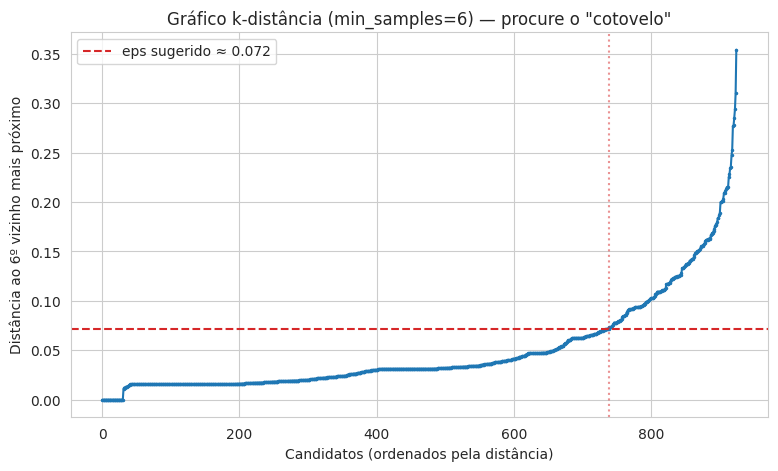

eps sugerido pela heurística do cotovelo: 0.072


In [72]:
min_samples_teste = 2 * len(colunas_driver)  # heurística comum: min_samples >= dimensões + 1; usamos 2x as dimensões

vizinhos = NearestNeighbors(n_neighbors=min_samples_teste).fit(X)
distancias, _ = vizinhos.kneighbors(X)
k_distancias = np.sort(distancias[:, -1])  # distância de cada ponto ao seu min_samples-ésimo vizinho, ordenada crescente

# Sugestão automática do "cotovelo": o ponto mais distante da reta que liga o primeiro e o
# último ponto da curva (heurística geométrica simplificada, tipo "kneedle"). Sempre confira
# visualmente no gráfico antes de aceitar — é só um ponto de partida, não a resposta final.
n = len(k_distancias)
p1 = np.array([0, k_distancias[0]])
p2 = np.array([n - 1, k_distancias[-1]])
reta_norm = (p2 - p1) / np.linalg.norm(p2 - p1)
pontos = np.column_stack([np.arange(n), k_distancias]) - p1
projecao = np.outer(pontos @ reta_norm, reta_norm)
distancia_perp = np.linalg.norm(pontos - projecao, axis=1)
indice_cotovelo = int(np.argmax(distancia_perp))
eps_sugerido = k_distancias[indice_cotovelo]

plt.figure(figsize=(9, 5))
plt.plot(k_distancias, marker='.', markersize=3)
plt.axhline(eps_sugerido, color='tab:red', linestyle='--', label=f'eps sugerido ≈ {eps_sugerido:.3f}')
plt.axvline(indice_cotovelo, color='tab:red', linestyle=':', alpha=0.5)
plt.xlabel('Candidatos (ordenados pela distância)')
plt.ylabel(f'Distância ao {min_samples_teste}º vizinho mais próximo')
plt.title(f'Gráfico k-distância (min_samples={min_samples_teste}) — procure o "cotovelo"')
plt.legend()
plt.grid(True)
plt.show()

print(f"eps sugerido pela heurística do cotovelo: {eps_sugerido:.3f}")


### 1.2) Rodando o DBSCAN

Com `eps` e `min_samples` definidos, rodamos o DBSCAN e conferimos: quantos clusters ele encontrou, e que fração da base virou ruído. Se quase tudo virar ruído, `eps` está pequeno demais (ou `min_samples` grande demais); se tudo virar um cluster só, `eps` está grande demais.


In [73]:
eps_dbscan = round(eps_sugerido, 2)  # ajuste conforme o gráfico acima, se quiser
min_samples_dbscan = min_samples_teste

dbscan = DBSCAN(eps=eps_dbscan, min_samples=min_samples_dbscan)
labels_dbscan_num = dbscan.fit_predict(X)

n_clusters_dbscan = len(set(labels_dbscan_num)) - (1 if -1 in labels_dbscan_num else 0)
n_ruido = int((labels_dbscan_num == -1).sum())

# Rótulos por ordem de tamanho (A = maior cluster, ...); ruído fica com rótulo próprio, sempre por último
tamanhos = pd.Series(labels_dbscan_num[labels_dbscan_num != -1]).value_counts()
mapa_letras = {cid: chr(65 + i) for i, cid in enumerate(tamanhos.index)}
df_cluster['cluster_dbscan'] = [mapa_letras.get(c, 'Ruído') for c in labels_dbscan_num]
# nomes por perfil (coerente com os demais notebooks); 'Ruído' preservado, perfis repetidos ganham sufixo
df_cluster['cluster_dbscan'] = df_cluster['cluster_dbscan'].map(nomear_clusters(df_cluster, 'cluster_dbscan'))

ordem_dbscan = [c for c in df_cluster['cluster_dbscan'].value_counts().index if c != 'Ruído']
if 'Ruído' in set(df_cluster['cluster_dbscan']):
    ordem_dbscan = ordem_dbscan + ['Ruído']
nomes_dbscan_reais = [c for c in ordem_dbscan if c != 'Ruído']
cores_dbscan = dict(zip(nomes_dbscan_reais, sns.color_palette('husl', n_colors=len(nomes_dbscan_reais))))
cores_dbscan['Ruído'] = (0.6, 0.6, 0.6)

print(f"eps={eps_dbscan}, min_samples={min_samples_dbscan}")
print(f"Clusters encontrados: {n_clusters_dbscan}")
print(f"Pontos de ruído: {n_ruido} ({n_ruido / len(labels_dbscan_num):.1%})")

mask_nao_ruido = df_cluster['cluster_dbscan'] != 'Ruído'
if df_cluster.loc[mask_nao_ruido, 'cluster_dbscan'].nunique() >= 2:
    sil_dbscan = silhouette_score(X[mask_nao_ruido.values], df_cluster.loc[mask_nao_ruido, 'cluster_dbscan'])
    print(f"Silhouette (só pontos não-ruído): {sil_dbscan:.3f}")
else:
    sil_dbscan = float('nan')
    print("Menos de 2 clusters não-ruído — silhouette não se aplica. Ajuste eps/min_samples.")

df_cluster['cluster_dbscan'].value_counts().loc[ordem_dbscan]


eps=0.07, min_samples=6
Clusters encontrados: 10
Pontos de ruído: 144 (15.6%)


Silhouette (só pontos não-ruído): 0.207


cluster_dbscan
Prósperos                       396
Promissores                     128
Batalhadores                     87
Recém-chegados                   80
Promissores (2)                  35
Prósperos (jovens)     16
Prósperos (2)                    14
Desassistidos                     9
Desassistidos (2)                 9
Desassistidos (3)                 7
Ruído                           144
Name: count, dtype: int64

### 1.3) Radar: perfil das variáveis-driver por cluster

O "centróide" de cada cluster aqui é a média das variáveis-driver padronizadas dentro dele (ver explicação acima) — o ruído fica de fora, já que não é um cluster.


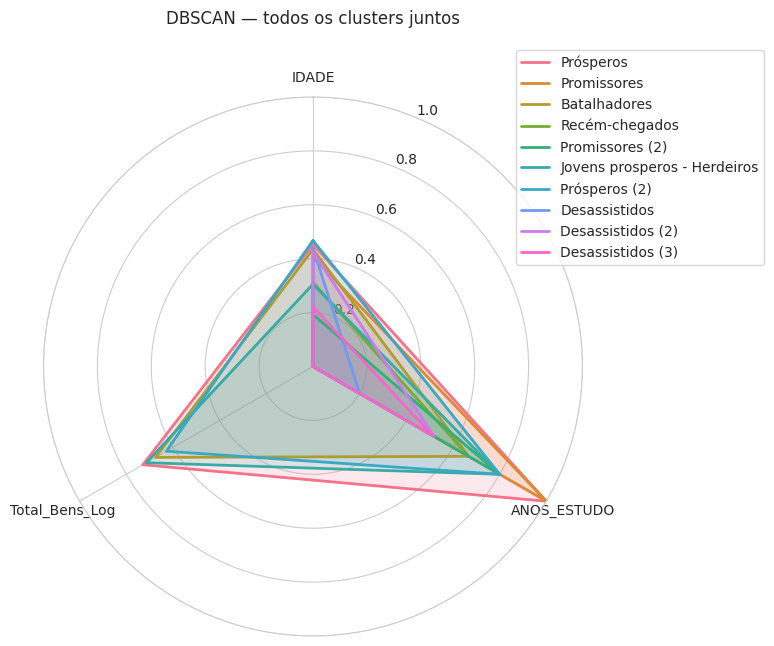

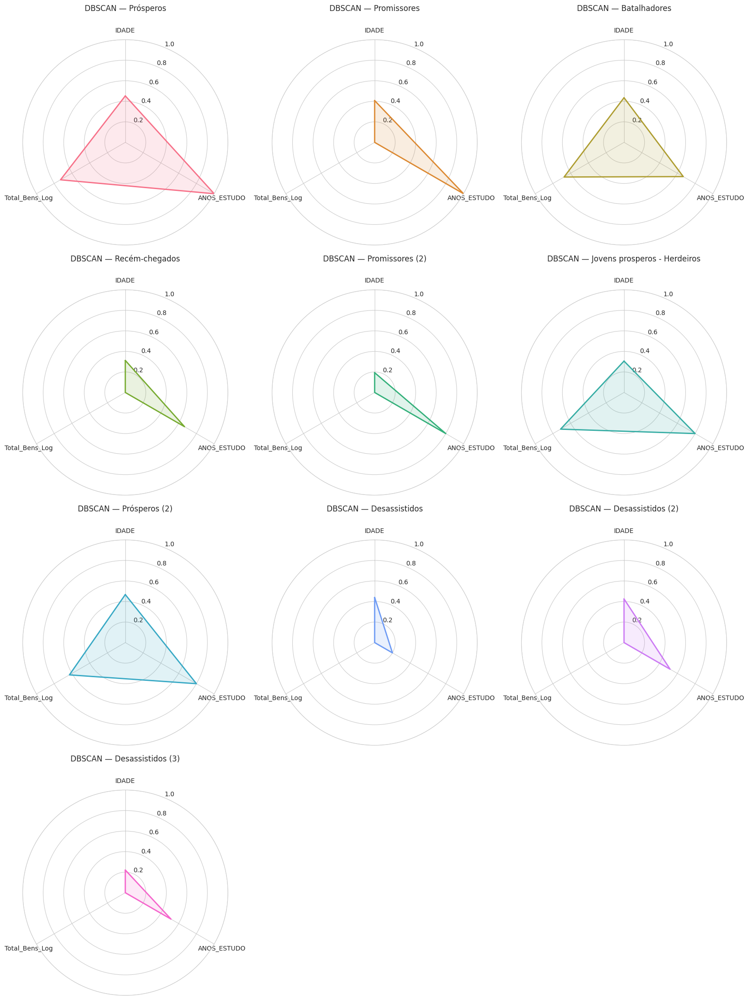

In [74]:
clusters_dbscan_reais = [c for c in ordem_dbscan if c != 'Ruído']
centroides_dbscan_norm = np.array([
    X[df_cluster['cluster_dbscan'].values == cl].mean(axis=0) for cl in clusters_dbscan_reais
])

radar_clusters(centroides_dbscan_norm, clusters_dbscan_reais, cores_dbscan, 'DBSCAN')


### 1.4) Visualizando os clusters (e o ruído)

Mesmos dois planos de fundo usados no K-Means (`IDADE`/`Total_Bens_Log` e `ANOS_ESTUDO`/`Total_Bens_Log`), agora com o ruído destacado como `x` cinza — repare que ele tende a se concentrar nas bordas da nuvem de pontos, não no meio.


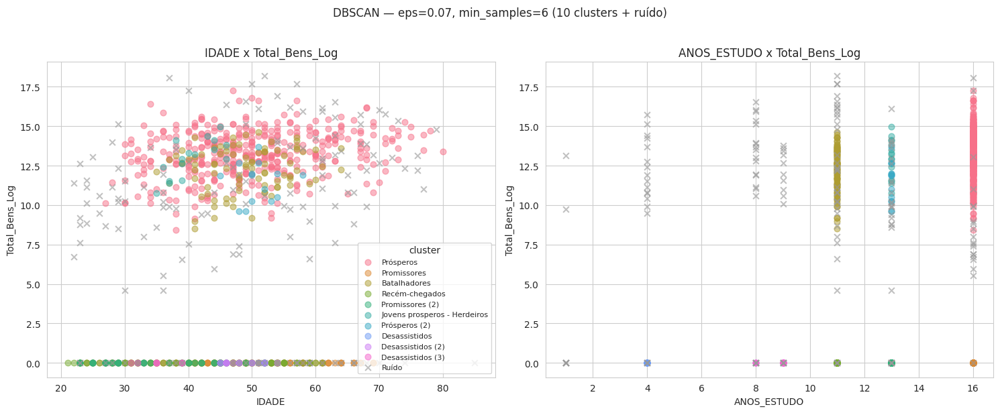

In [75]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, (x_col, y_col) in zip(axes, [('IDADE', 'Total_Bens_Log'), ('ANOS_ESTUDO', 'Total_Bens_Log')]):
    for cl in ordem_dbscan:
        subset = df_cluster[df_cluster['cluster_dbscan'] == cl]
        marker = 'x' if cl == 'Ruído' else 'o'
        alpha = 0.6 if cl == 'Ruído' else 0.5
        ax.scatter(subset[x_col], subset[y_col], label=cl, color=cores_dbscan[cl], marker=marker, alpha=alpha, s=40)
    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)
    ax.set_title(f'{x_col} x {y_col}')

axes[0].legend(title='cluster', fontsize=8)
plt.suptitle(f'DBSCAN — eps={eps_dbscan}, min_samples={min_samples_dbscan} ({n_clusters_dbscan} clusters + ruído)', y=1.02)
plt.tight_layout()
plt.show()


### 1.5) Sensibilidade a eps e min_samples

DBSCAN é conhecido por ser sensível à escolha dos parâmetros — pequenas mudanças em `eps` podem juntar dois clusters em um só, ou espalhar ruído por toda a base. Em vez de confiar num único par de valores, testamos uma grade de combinações e olhamos como o número de clusters e o percentual de ruído reagem.


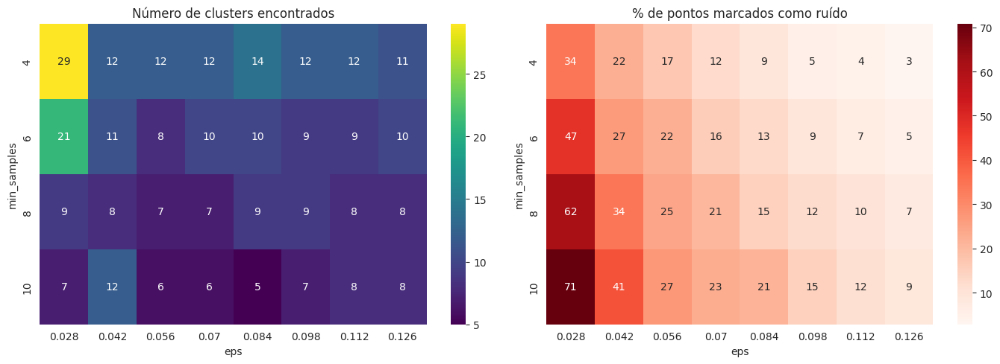

In [76]:
faixa_eps = np.round(np.linspace(max(0.02, eps_dbscan * 0.4), eps_dbscan * 1.8, 8), 3)
faixa_min_samples = [4, 6, 8, 10]

resultados_grid = []
for eps_teste in faixa_eps:
    for ms_teste in faixa_min_samples:
        labels_teste = DBSCAN(eps=eps_teste, min_samples=ms_teste).fit_predict(X)
        n_cl = len(set(labels_teste)) - (1 if -1 in labels_teste else 0)
        pct_ruido = (labels_teste == -1).mean() * 100
        resultados_grid.append({'eps': eps_teste, 'min_samples': ms_teste, 'n_clusters': n_cl, 'pct_ruido': pct_ruido})

grid = pd.DataFrame(resultados_grid)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(grid.pivot(index='min_samples', columns='eps', values='n_clusters'),
            annot=True, fmt='.0f', cmap='viridis', ax=axes[0])
axes[0].set_title('Número de clusters encontrados')

sns.heatmap(grid.pivot(index='min_samples', columns='eps', values='pct_ruido'),
            annot=True, fmt='.0f', cmap='Reds', ax=axes[1])
axes[1].set_title('% de pontos marcados como ruído')

plt.tight_layout()
plt.show()


> Se a coluna/linha escolhida (`eps_dbscan`, `min_samples_dbscan`) estiver numa região "instável" do mapa — onde vizinhos próximos do grid mudam bastante o número de clusters ou o % de ruído — vale a pena reconsiderar a escolha. Regiões "estáveis" (várias combinações vizinhas dando resultado parecido) são um sinal melhor de que o resultado reflete estrutura real dos dados, não um acidente de parâmetro.

### 1.6) Perfil demográfico-social dos clusters do DBSCAN

Mesma leitura da Parte 1 do notebook anterior: como gênero, cor/raça e estado civil se distribuem dentro de cada cluster de densidade — e, dessa vez, também dentro do grupo de ruído (candidatos que não se encaixaram em nenhuma região densa).


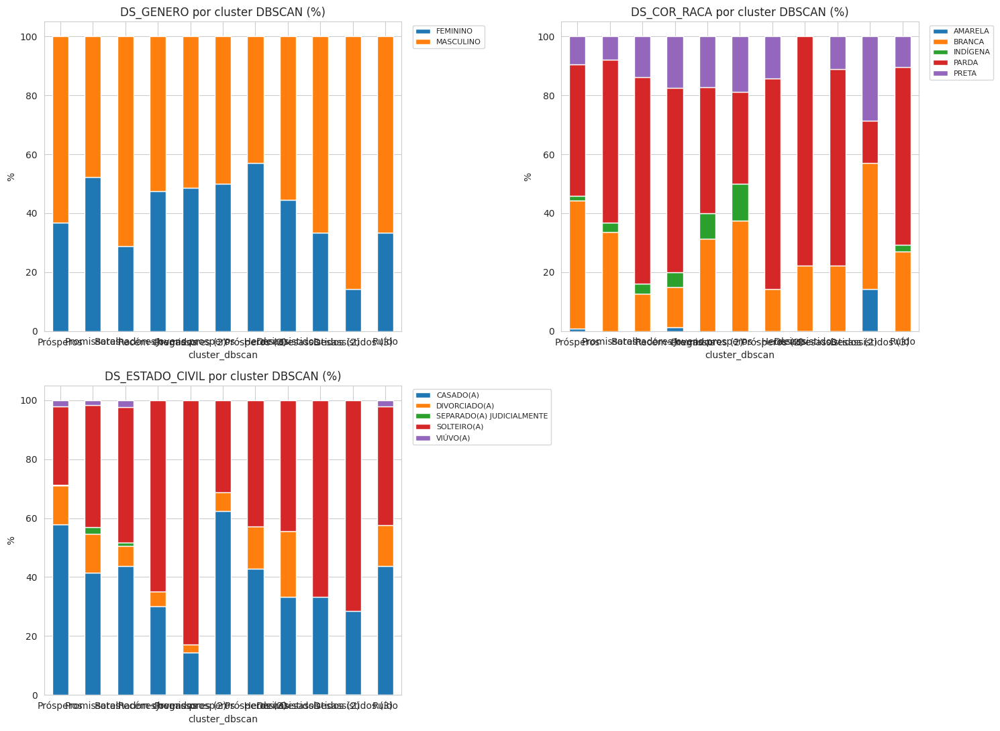

,qtd_candidatos,idade_media,anos_estudo_medio,patrimonio_mediano
cluster_dbscan,,,,
Prósperos,396,50.00,16.00,"601,490.80"
Promissores,128,47.00,16.00,0.00
Batalhadores,87,48.80,11.00,"262,000.00"
Recém-chegados,80,41.00,11.00,0.00
Promissores (2),35,33.30,13.00,0.00
Prósperos (jovens),16,40.60,13.00,"493,050.00"
Prósperos (2),14,50.90,13.00,"146,500.00"
Desassistidos,9,49.10,4.00,0.00
Desassistidos (2),9,48.20,8.80,0.00


In [77]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
axes = axes.flatten()

for i, col in enumerate(colunas_perfil):
    tabela = pd.crosstab(df_cluster['cluster_dbscan'], df_cluster[col], normalize='index').mul(100)
    tabela = tabela.loc[ordem_dbscan]
    tabela.plot(kind='bar', stacked=True, ax=axes[i])
    axes[i].set_title(f'{col} por cluster DBSCAN (%)')
    axes[i].set_ylabel('%')
    axes[i].tick_params(axis='x', rotation=0)
    axes[i].legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

resumo_dbscan = df_cluster.groupby('cluster_dbscan').agg(
    qtd_candidatos=('SQ_CANDIDATO', 'count'),
    idade_media=('IDADE', 'mean'),
    anos_estudo_medio=('ANOS_ESTUDO', 'mean'),
    patrimonio_mediano=('Total_Bens', 'median'),
).round(1)
resumo_dbscan.loc[ordem_dbscan]


### 1.7) Comparando com o K-Means

Duas leituras: a métrica de qualidade (silhouette, calculada só sobre os pontos não-ruído do DBSCAN, já que ruído por definição não pertence a nenhum cluster) e o tamanho dos grupos. Repare que a comparação de tamanhos já não é "clusters do mesmo total" — o DBSCAN deixou uma fatia de fora como ruído.


Silhouette — K-Means (k=5):                     0.365
Silhouette — DBSCAN (só não-ruído, 10 clusters):    0.207


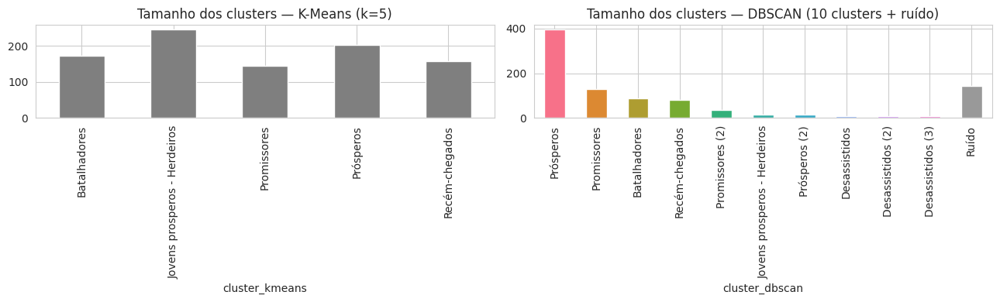

cluster_dbscan,Batalhadores,Desassistidos,Desassistidos (2),Desassistidos (3),Prósperos (jovens),Promissores,Promissores (2),Prósperos,Prósperos (2),Recém-chegados,Ruído
cluster_kmeans,,,,,,,,,,,
Batalhadores,87,0,0,0,0,0,0,0,12,0,74
Prósperos (jovens),0,0,0,0,16,0,0,203,1,0,26
Promissores,0,0,0,0,0,128,6,0,0,0,10
Prósperos,0,0,0,0,0,0,0,193,1,0,10
Recém-chegados,0,9,9,7,0,0,29,0,0,80,24


In [78]:
print(f"Silhouette — K-Means (k={k_final}):                     {sil_kmeans:.3f}")
print(f"Silhouette — DBSCAN (só não-ruído, {n_clusters_dbscan} clusters):    {sil_dbscan:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df_cluster['cluster_kmeans'].value_counts().sort_index().plot(kind='bar', ax=axes[0], color='tab:gray')
axes[0].set_title(f'Tamanho dos clusters — K-Means (k={k_final})')

df_cluster['cluster_dbscan'].value_counts().loc[ordem_dbscan].plot(
    kind='bar', ax=axes[1], color=[cores_dbscan[c] for c in ordem_dbscan]
)
axes[1].set_title(f'Tamanho dos clusters — DBSCAN ({n_clusters_dbscan} clusters + ruído)')

plt.tight_layout()
plt.show()

pd.crosstab(df_cluster['cluster_kmeans'], df_cluster['cluster_dbscan'])


---
# Parte 2 — Clusterização Hierárquica (HCLUST)

**A ideia:** em vez de decidir `k` antes de rodar o algoritmo (K-Means) ou deixar `k` emergir de `eps`/`min_samples` (DBSCAN), a clusterização hierárquica aglomerativa constrói **a árvore inteira de agrupamentos possíveis**, de uma vez:

1. Começa com cada candidato como seu próprio cluster (`n` clusters).
2. A cada passo, junta os **dois clusters mais próximos** em um só.
3. Repete até sobrar um único cluster com todo mundo.

O resultado é o **dendrograma** — uma árvore em que a altura de cada junção mostra a distância entre os dois clusters unidos. Vocês escolhem `k` **depois** de ver a árvore inteira, cortando-a horizontalmente na altura que fizer mais sentido — sem precisar re-treinar nada para testar outro `k` (diferente do K-Means, em que cada `k` é um treino novo).

A peça que falta especificar é **como medir a distância entre dois clusters** (não só entre dois pontos) — é o que os diferentes critérios de *linkage* fazem.


### 2.1) Comparando critérios de linkage

- **`single`** (ligação simples): distância entre os dois pontos **mais próximos** dos dois clusters. Tende a formar clusters "em cadeia", alongados — sensível a pontos que servem de ponte entre grupos.
- **`complete`** (ligação completa): distância entre os dois pontos **mais distantes**. Tende a formar clusters compactos e de tamanho parecido, mas pode quebrar grupos legítimos que tenham alguns pontos afastados.
- **`average`** (ligação média): média de todas as distâncias par a par entre os dois clusters — um meio-termo entre `single` e `complete`.
- **`ward`**: minimiza o aumento de variância **dentro** dos clusters a cada junção — é o critério mais próximo, conceitualmente, do que o K-Means otimiza (WCSS), o que o torna o mais fácil de comparar com os resultados da Parte 1 do notebook anterior.

Note como `single` tende a produzir uma árvore "desbalanceada", com uma cadeia longa de junções tardias (efeito conhecido como *chaining*) — um sintoma visual de que esse critério não é uma boa escolha para esta base.


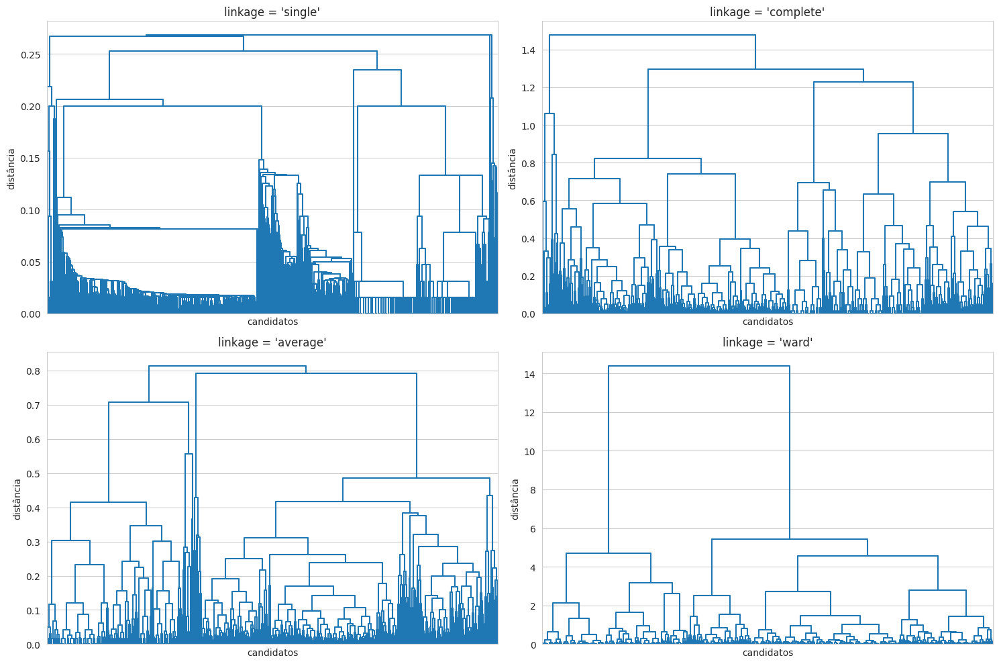

In [79]:
metodos_linkage = ['single', 'complete', 'average', 'ward']

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

linkages = {}
for ax, metodo in zip(axes, metodos_linkage):
    Z = linkage(X, method=metodo)
    linkages[metodo] = Z
    dendrogram(Z, no_labels=True, ax=ax, color_threshold=0)
    ax.set_title(f"linkage = '{metodo}'")
    ax.set_xlabel('candidatos')
    ax.set_ylabel('distância')

plt.tight_layout()
plt.show()


### 2.2) Cortando a árvore: escolhendo k

Seguimos com `ward`, pelo motivo explicado acima. A linha tracejada mostra onde cortamos o dendrograma para chegar a `k_hclust` clusters — mude `k_hclust` e rode a célula de novo para ver outras granularidades sem re-treinar nada; essa é a vantagem prática da hierarquia sobre o K-Means.


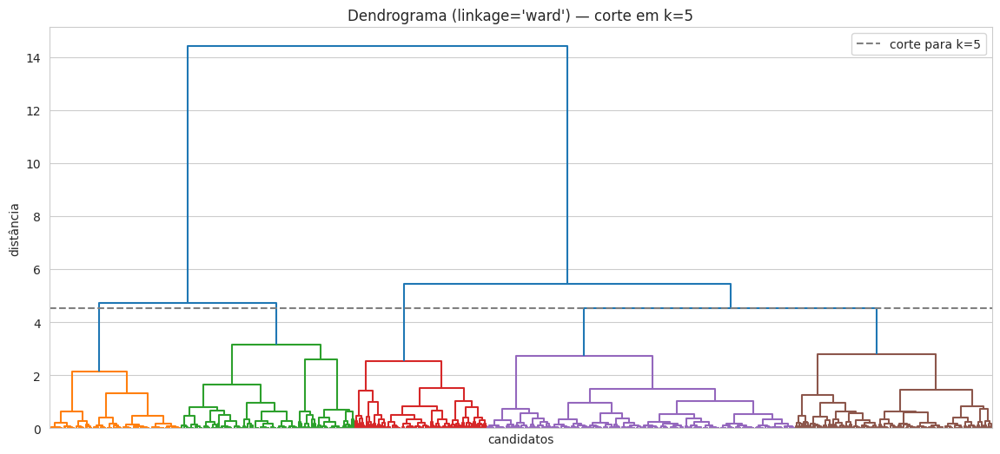

Hierárquico (ward, k=5) — silhouette: 0.345


cluster_hclust
Batalhadores                    129
Prósperos (jovens)    193
Promissores                     129
Prósperos                       303
Recém-chegados                  171
Name: count, dtype: int64

In [80]:
metodo_escolhido = 'ward'  # minimiza variância dentro do cluster — mesmo critério que o K-Means otimiza, o que facilita comparar os dois
Z_ward = linkages[metodo_escolhido]

k_hclust = 5  # alinhado ao K-Means/Bisecting (k=5)
limiar_corte = Z_ward[-(k_hclust - 1), 2]  # altura de junção logo abaixo da qual restam exatamente k_hclust clusters

plt.figure(figsize=(14, 6))
dendrogram(Z_ward, no_labels=True, color_threshold=limiar_corte)
plt.axhline(limiar_corte, color='gray', linestyle='--', label=f'corte para k={k_hclust}')
plt.title(f"Dendrograma (linkage='{metodo_escolhido}') — corte em k={k_hclust}")
plt.xlabel('candidatos')
plt.ylabel('distância')
plt.legend()
plt.show()

labels_hclust_num = fcluster(Z_ward, t=k_hclust, criterion='maxclust')

tamanhos_h = pd.Series(labels_hclust_num).value_counts()
mapa_letras_h = {cid: chr(65 + i) for i, cid in enumerate(tamanhos_h.index)}
df_cluster['cluster_hclust'] = [mapa_letras_h[c] for c in labels_hclust_num]
# nomes por perfil (coerente com os demais)
df_cluster['cluster_hclust'] = df_cluster['cluster_hclust'].map(nomear_clusters(df_cluster, 'cluster_hclust'))

clusters_hclust_ordenados = list(df_cluster['cluster_hclust'].value_counts().index)
cores_hclust = dict(zip(clusters_hclust_ordenados, sns.color_palette('Set2', n_colors=len(clusters_hclust_ordenados))))

sil_hclust = silhouette_score(X, df_cluster['cluster_hclust'])
print(f"Hierárquico ({metodo_escolhido}, k={k_hclust}) — silhouette: {sil_hclust:.3f}")
df_cluster['cluster_hclust'].value_counts().sort_index()


### 2.3) Radar: perfil das variáveis-driver por cluster

Mesma lógica da Parte 1: os "centróides" abaixo são a média de cada cluster nas variáveis-driver padronizadas — o método hierárquico também não calcula centróides como parte do algoritmo, mas reconstruímos um para fins de visualização, do mesmo jeito que fizemos para o DBSCAN.


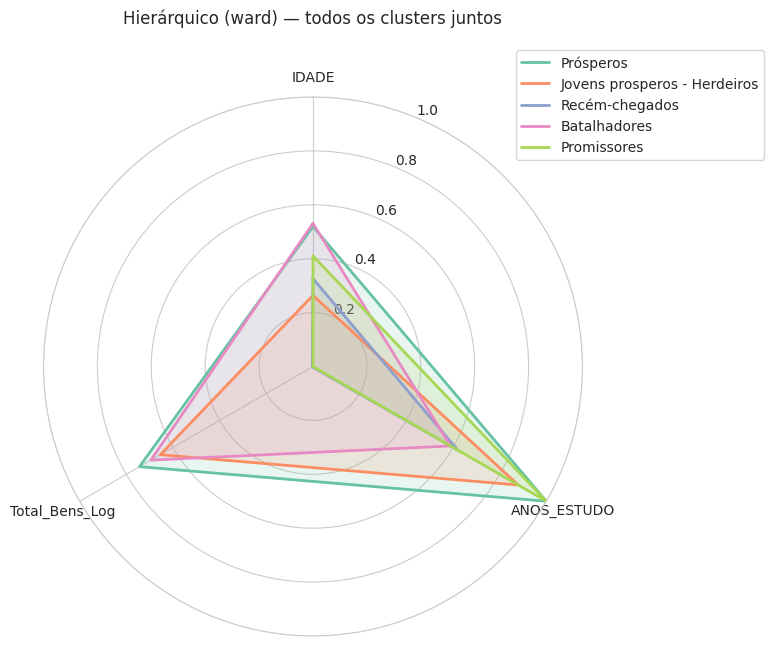

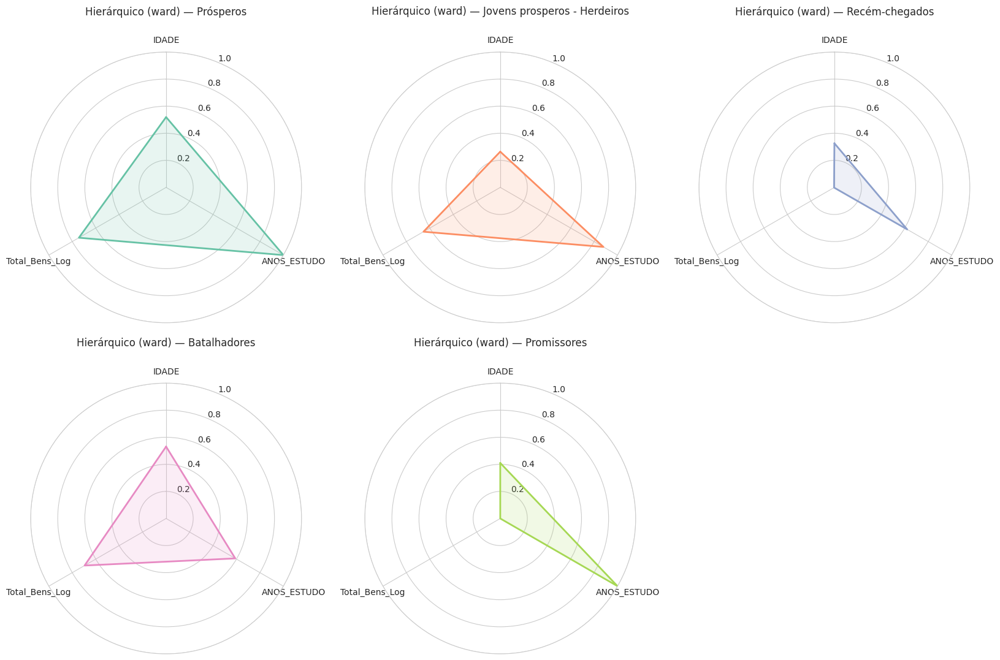

In [81]:
centroides_hclust_norm = np.array([
    X[df_cluster['cluster_hclust'].values == cl].mean(axis=0) for cl in clusters_hclust_ordenados
])

radar_clusters(centroides_hclust_norm, clusters_hclust_ordenados, cores_hclust, f'Hierárquico ({metodo_escolhido})')


### 2.4) Perfil demográfico-social dos clusters hierárquicos


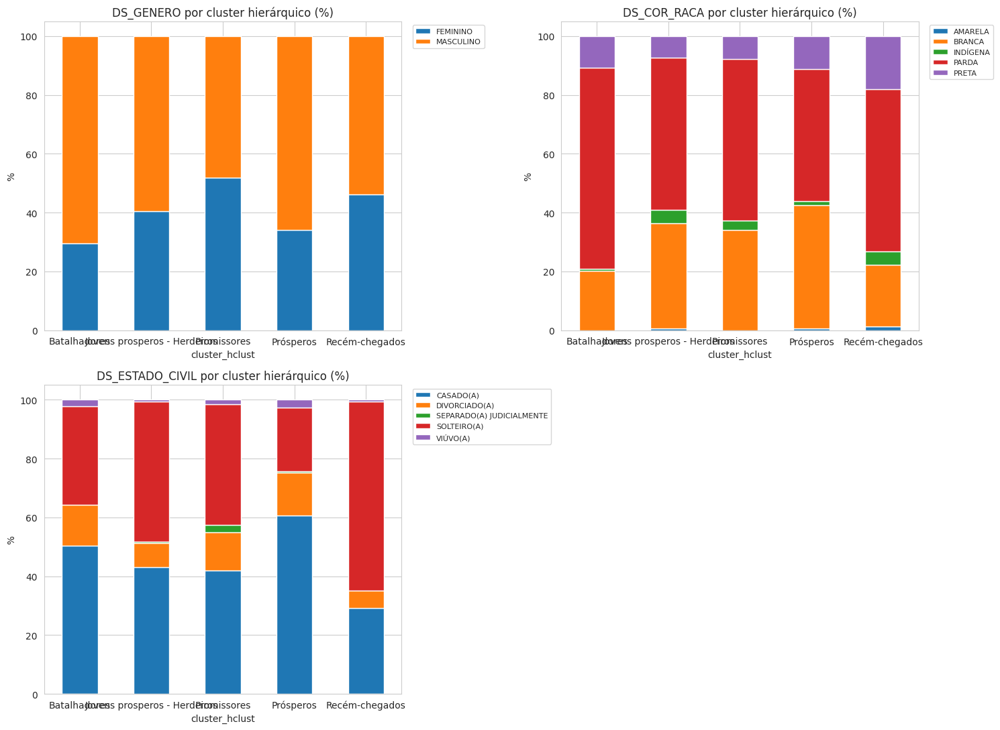

,qtd_candidatos,idade_media,anos_estudo_medio,patrimonio_mediano
cluster_hclust,,,,
Batalhadores,129,55.00,9.80,"262,000.00"
Prósperos (jovens),193,37.90,14.20,"205,530.80"
Promissores,129,47.20,16.00,0.00
Prósperos,303,54.20,16.00,"819,203.50"
Recém-chegados,171,41.80,10.30,0.00


In [82]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
axes = axes.flatten()

for i, col in enumerate(colunas_perfil):
    pd.crosstab(df_cluster['cluster_hclust'], df_cluster[col], normalize='index').mul(100).plot(
        kind='bar', stacked=True, ax=axes[i]
    )
    axes[i].set_title(f'{col} por cluster hierárquico (%)')
    axes[i].set_ylabel('%')
    axes[i].tick_params(axis='x', rotation=0)
    axes[i].legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

resumo_hclust = df_cluster.groupby('cluster_hclust').agg(
    qtd_candidatos=('SQ_CANDIDATO', 'count'),
    idade_media=('IDADE', 'mean'),
    anos_estudo_medio=('ANOS_ESTUDO', 'mean'),
    patrimonio_mediano=('Total_Bens', 'median'),
).round(1)
resumo_hclust


### 2.5) Comparando os três algoritmos

As tabelas de contingência abaixo cruzam os rótulos de cada par de algoritmos: se a maior parte dos candidatos de um cluster do K-Means cair concentrada em um único cluster do Hierárquico (em vez de espalhada), é sinal de que os dois algoritmos, apesar de construídos de formas bem diferentes, estão enxergando a mesma estrutura nos dados.


In [83]:
comparacao = pd.DataFrame({
    'algoritmo': ['K-Means', 'DBSCAN', f'Hierárquico ({metodo_escolhido})'],
    'k_ou_clusters': [k_final, n_clusters_dbscan, k_hclust],
    'silhouette': [sil_kmeans, sil_dbscan, sil_hclust],
    'trata_ruido_separado': [False, True, False],
}).round(3)
display(comparacao)

print("K-Means x Hierárquico:")
display(pd.crosstab(df_cluster['cluster_kmeans'], df_cluster['cluster_hclust']))

print("DBSCAN x Hierárquico:")
display(pd.crosstab(df_cluster['cluster_dbscan'], df_cluster['cluster_hclust']))


,algoritmo,k_ou_clusters,silhouette,trata_ruido_separado
0,K-Means,5,0.36,False
1,DBSCAN,10,0.21,True
2,Hierárquico (ward),5,0.34,False


K-Means x Hierárquico:


cluster_hclust,Batalhadores,Prósperos (jovens),Promissores,Prósperos,Recém-chegados
cluster_kmeans,,,,,
Batalhadores,121,52,0,0,0
Prósperos (jovens),3,137,0,106,0
Promissores,0,2,129,0,13
Prósperos,5,2,0,197,0
Recém-chegados,0,0,0,0,158


DBSCAN x Hierárquico:


cluster_hclust,Batalhadores,Prósperos (jovens),Promissores,Prósperos,Recém-chegados
cluster_dbscan,,,,,
Batalhadores,47,40,0,0,0
Desassistidos,0,0,0,0,9
Desassistidos (2),0,0,0,0,9
Desassistidos (3),0,0,0,0,7
Prósperos (jovens),1,15,0,0,0
Promissores,0,0,128,0,0
Promissores (2),0,0,0,0,35
Prósperos,0,97,0,299,0
Prósperos (2),13,1,0,0,0


---
## Fechamento: quatro algoritmos, quatro jeitos de ver os mesmos candidatos

Entre este notebook e o `02_clusterizacao.ipynb`, rodamos quatro algoritmos de clusterização na mesma pergunta de negócio e nas mesmas variáveis-driver:

| Algoritmo | Como decide `k` | Trata outliers | Forma dos clusters | Custo computacional |
|---|---|---|---|---|
| **K-Means** | escolhido antes (cotovelo/silhouette/DB/CH) | força todo ponto para o cluster mais próximo | esférica/convexa (assume) | baixo, escala bem |
| **Bisecting K-Means** | construído incrementalmente, 1→k | idem K-Means | idem K-Means | baixo, escala bem |
| **DBSCAN** | emerge de `eps`/`min_samples` | marca como ruído, separado | arbitrária (não-convexa) | médio; sensível a `eps`/`min_samples` |
| **Hierárquico (ward)** | escolhido depois, cortando o dendrograma | idem K-Means (todo ponto entra em algum cluster) | depende do linkage | alto — O(n²) ou pior; não escala para bases muito maiores |

Nenhum dos quatro é "o certo" — a escolha depende da pergunta: se vocês já sabem quantos perfis esperam encontrar e querem algo rápido e escalável, K-Means/Bisecting K-Means bastam. Se suspeitam que existem outliers genuínos que não deveriam ser forçados em nenhum grupo, DBSCAN é mais honesto. Se querem explorar várias granularidades sem re-treinar, ou entender a ordem em que os grupos se formam, a hierarquia dá essa visão que nenhum dos outros três oferece.

**Exercício sugerido:** repliquem aqui o mesmo kit de nomeação de clusters da Parte 1 do notebook anterior (ficha técnica + heatmap de desvio + rascunho automático), agora para `cluster_dbscan` e `cluster_hclust`.

Próxima etapa do pipeline: `03_regras_associacao.ipynb` (Apriori).


---

# Desafio — Gastos de Campanha e Variáveis por Quartil

Extensão da Fase 2: inclui o **gasto de campanha** (prestação de contas do TSE) e discretiza as variáveis contínuas em **quartis** para a Fase 3.

# Desafio — Gastos de Campanha e Variáveis por Quartil

**Recorte:** Deputados Federais da **Região Norte** (AC, AM, AP, PA, RO, RR, TO) — Eleições 2026.

Este notebook estende as Fases 2 (clusterização) e 3 (regras de associação) com as duas tarefas do `desafio_gastos_campanha.md`:

1. **Parte 1** — trazer o *gasto de campanha* (quanto cada campanha já contratou) como uma 4ª variável-driver e ver se ela muda os clusters.
2. **Parte 2** — discretizar cada variável numérica em faixas por quartil (`_Faixa`) para que o Apriori possa usá-las como itens.

Ele parte do mesmo dataset preparado na Fase 0 (`dados/candidatos_DEPUTADO_FEDERAL_NORTE_2026.csv`) e do zip de prestação de contas em `dados/`.

## Configuração

Mesmos valores das Fases 0–3.

In [84]:
CARGO = "DEPUTADO FEDERAL"
UF = ["AC", "AM", "AP", "PA", "RO", "RR", "TO"]   # Região Norte
NOME_RECORTE = "NORTE"
ANO_ELEICAO = 2026
mostrar_por_uf = (UF is None) or (isinstance(UF, (list, tuple, set)) and len(UF) > 1)

In [85]:
import warnings
warnings.filterwarnings("ignore")

import os, zipfile, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from math import pi

from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from mlxtend.frequent_patterns import apriori, association_rules

sns.set_style("whitegrid")
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
SEMENTE = 42
np.random.seed(SEMENTE)

nome_uf = 'BRASIL' if UF is None else (NOME_RECORTE if isinstance(UF, (list, tuple, set)) else UF)
nome_cargo = CARGO.replace(' ', '_')
arquivo = f"dados/candidatos_{nome_cargo}_{nome_uf}_{ANO_ELEICAO}.csv"
df = pd.read_csv(arquivo)
print(f"Carregado: {arquivo}  ->  {df.shape[0]} candidatos")

# escolaridade em anos (mesma escala das Fases 2/3)
ANOS_ESTUDO_POR_GRAU = {
    'ANALFABETO': 0, 'LÊ E ESCREVE': 1,
    'ENSINO FUNDAMENTAL INCOMPLETO': 4, 'ENSINO FUNDAMENTAL COMPLETO': 8,
    'ENSINO MÉDIO INCOMPLETO': 9, 'ENSINO MÉDIO COMPLETO': 11,
    'SUPERIOR INCOMPLETO': 13, 'SUPERIOR COMPLETO': 16,
}
df['ANOS_ESTUDO'] = df['DS_GRAU_INSTRUCAO'].map(ANOS_ESTUDO_POR_GRAU)

# mesma base da Fase 2/3: remove patrimônio extremo (IQR) e escolaridade não divulgada
Q1, Q3 = df['Total_Bens_Log'].quantile([0.25, 0.75]); IQR = Q3 - Q1
limite_superior = Q3 + 1.5 * IQR
df_cluster = df[(df['Total_Bens_Log'] <= limite_superior) & (df['ANOS_ESTUDO'].notna())].copy()
print(f"Base para o desafio: {df_cluster.shape[0]} candidatos")

Carregado: dados/candidatos_DEPUTADO_FEDERAL_NORTE_2026.csv  ->  925 candidatos
Base para o desafio: 925 candidatos


> **Nota deste recorte:** como ~32% dos candidatos declararam patrimônio **zero**, o `Q1` de `Total_Bens_Log` é 0 e o IQR fica muito largo — o corte de outlier por IQR (herdado da Fase 2) acaba **não removendo ninguém** aqui. Mantemos a mesma regra do molde por coerência metodológica, apenas registrando que, neste dataset, ela não descarta candidatos.

---
# Parte 1 — Gasto de campanha como 4ª variável

## De onde vem o dado

Conjunto **"Prestação de Contas Eleitorais – 2026"** do TSE (sistema IDC — *Informações Durante a Campanha*): o candidato declara periodicamente, ao longo da campanha, o que já contratou/gastou. O zip foi baixado manualmente (o CDN do TSE bloqueia downloads automatizados) e está em `dados/prestacao_de_contas_eleitorais_candidatos_2026.zip`.

**Contratadas x pagas — qual usar?** O zip traz `despesas_contratadas_*` (compromissos assumidos) e `despesas_pagas_*` (o que já saiu do caixa). Inspecionando as colunas:

- `despesas_contratadas_*` tem a coluna **`SQ_CANDIDATO`** — a mesma chave usada na Fase 0 para juntar bens e candidatos.
- `despesas_pagas_*` **não** traz `SQ_CANDIDATO` (só `SQ_PRESTADOR_CONTAS`/`SQ_DESPESA`), então não dá para juntar direto por candidato sem uma tabela-ponte.

Por isso usamos **despesas contratadas** como medida de "gasto até agora": é o compromisso financeiro que a campanha já assumiu, e é a que se junta diretamente à nossa base por `SQ_CANDIDATO`.

In [86]:
ZIP_CONTAS = f"dados/prestacao_de_contas_eleitorais_candidatos_{ANO_ELEICAO}.zip"
ufs_recorte = UF if isinstance(UF, (list, tuple)) else ([UF] if UF else [])

def valor_brasileiro(serie):
    """'2.000,00' -> 2000.00 ; '432,26' -> 432.26 (milhar='.', decimal=',')."""
    return (serie.astype(str)
                 .str.replace('.', '', regex=False)
                 .str.replace(',', '.', regex=False)
                 .replace({'nan': None}).astype(float))

quadros = []
with zipfile.ZipFile(ZIP_CONTAS) as z:
    for uf in ufs_recorte:
        nome = f"despesas_contratadas_candidatos_{ANO_ELEICAO}_{uf}.csv"
        with z.open(nome) as f:
            d = pd.read_csv(io.TextIOWrapper(f, encoding='latin-1'), sep=';',
                            usecols=['SQ_CANDIDATO', 'SG_UF', 'DS_CARGO', 'VR_DESPESA_CONTRATADA'])
        quadros.append(d)
desp = pd.concat(quadros, ignore_index=True)
desp['VR_DESPESA_CONTRATADA'] = valor_brasileiro(desp['VR_DESPESA_CONTRATADA'])
print(f"{len(desp):,} linhas de despesa contratada nas 7 UFs (todos os cargos)")

# uma despesa por linha -> soma por candidato (mesma lógica do Total_Bens)
gasto = (desp.groupby('SQ_CANDIDATO')['VR_DESPESA_CONTRATADA'].sum()
             .rename('Total_Gasto_Campanha'))
print(f"{len(gasto):,} candidatos (de todos os cargos) com alguma despesa registrada")

98,192 linhas de despesa contratada nas 7 UFs (todos os cargos)
2,777 candidatos (de todos os cargos) com alguma despesa registrada


In [87]:
# junta na base; candidato SEM registro de despesa = gasto ZERO (não "desconhecido"):
# a declaração é obrigatória, então ausência significa que ainda não contratou nada.
df_cluster = df_cluster.merge(gasto, on='SQ_CANDIDATO', how='left')
n_sem = df_cluster['Total_Gasto_Campanha'].isna().sum()
df_cluster['Total_Gasto_Campanha'] = df_cluster['Total_Gasto_Campanha'].fillna(0)   # NaN -> 0 (ver nota)
df_cluster['Total_Gasto_Campanha_Log'] = np.log1p(df_cluster['Total_Gasto_Campanha'])

print(f"Sem nenhum registro de despesa (tratados como zero): {n_sem}")
print(f"Gastaram algo (>0): {(df_cluster['Total_Gasto_Campanha'] > 0).sum()} de {len(df_cluster)}")
display(df_cluster[['Total_Gasto_Campanha', 'Total_Gasto_Campanha_Log']].describe().round(2))

Sem nenhum registro de despesa (tratados como zero): 38
Gastaram algo (>0): 657 de 925


,Total_Gasto_Campanha,Total_Gasto_Campanha_Log
count,925.00,925.00
mean,"254,398.92",8.31
std,"423,503.10",5.55
min,0.00,0.00
25%,0.00,0.00
50%,"66,985.29",11.11
75%,"304,705.80",12.63
max,"2,994,312.34",14.91


Aplicamos `log1p` pela mesma razão do patrimônio: gasto de campanha é muito assimétrico (a maioria gasta pouco, poucos gastam muito), e o `log1p` (que trata o zero naturalmente, `log1p(0)=0`) comprime a cauda.

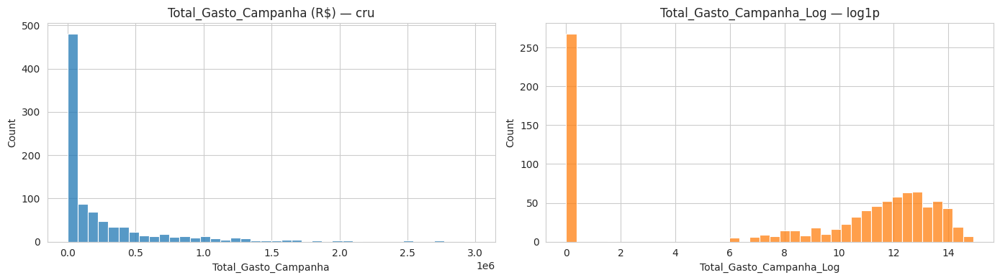

In [88]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df_cluster['Total_Gasto_Campanha'], bins=40, ax=axes[0])
axes[0].set_title('Total_Gasto_Campanha (R$) — cru')
sns.histplot(df_cluster['Total_Gasto_Campanha_Log'], bins=40, ax=axes[1], color='tab:orange')
axes[1].set_title('Total_Gasto_Campanha_Log — log1p')
plt.tight_layout(); plt.show()

## O gasto acompanha o patrimônio? E acompanha os clusters da Fase 2?

Primeiro, a correlação direta entre patrimônio (log) e gasto (log). Depois, reconstruímos os **cinco clusters nomeados do Bisecting K-Means (k=5)** da Fase 2 e olhamos o gasto de cada um — para responder: *quem gasta mais são os grupos economicamente estabelecidos, ou gasto é outra dimensão?*

In [89]:
corr = df_cluster['Total_Bens_Log'].corr(df_cluster['Total_Gasto_Campanha_Log'])
print(f"Correlação (Pearson) Total_Bens_Log x Total_Gasto_Campanha_Log: {corr:.3f}")

# --- reconstrói o Bisecting K-Means k=5 nomeado da Fase 2 (mesma SEMENTE/critério/nomes) ---
colunas_driver3 = ['IDADE', 'ANOS_ESTUDO', 'Total_Bens_Log']
X3 = MinMaxScaler().fit_transform(df_cluster[colunas_driver3])

def _inercia(idx, X):
    if len(idx) < 2: return 0.0
    p = X[idx]; c = p.mean(axis=0)
    return float(((p - c) ** 2).sum(axis=1).mean())

def bisecting_k(X, k, rs=SEMENTE):
    clusters = {0: np.arange(X.shape[0])}; nid = 1
    for _ in range(1, k):
        cid = max(clusters, key=lambda c: _inercia(clusters[c], X)); ip = clusters[cid]
        if len(ip) < 2: break
        lab = KMeans(2, random_state=rs, n_init=10).fit_predict(X[ip])
        a, b = nid, nid + 1; nid += 2
        del clusters[cid]; clusters[a] = ip[lab == 0]; clusters[b] = ip[lab == 1]
    ids = sorted(clusters, key=lambda c: len(clusters[c]), reverse=True)
    rot = np.empty(X.shape[0], dtype=object)
    for letra, cid in zip([chr(65 + i) for i in range(len(ids))], ids):
        rot[clusters[cid]] = letra
    return rot

df_cluster['cluster_bisecting'] = bisecting_k(X3, 5)
NOMES = {'A': 'Prósperos', 'B': 'Batalhadores', 'C': 'Promissores', 'D': 'Recém-chegados', 'E': 'Desassistidos'}
df_cluster['cluster'] = df_cluster['cluster_bisecting'].map(NOMES)
_ordem_nomes = [NOMES[l] for l in sorted(NOMES)]  # A..E
df_cluster['cluster'] = pd.Categorical(df_cluster['cluster'], categories=_ordem_nomes, ordered=True)

resumo = df_cluster.groupby('cluster').agg(
    qtd=('SQ_CANDIDATO', 'count'),
    gasto_mediano=('Total_Gasto_Campanha', 'median'),
    gasto_medio=('Total_Gasto_Campanha', 'mean'),
    pct_gastou=('Total_Gasto_Campanha', lambda s: (s > 0).mean() * 100),
    patrimonio_mediano=('Total_Bens', 'median'),
).round(1)
display(resumo)

Correlação (Pearson) Total_Bens_Log x Total_Gasto_Campanha_Log: 0.364


,qtd,gasto_mediano,gasto_medio,pct_gastou,patrimonio_mediano
cluster,,,,,
Prósperos,414,"192,740.00","392,478.30",85.30,"581,180.20"
Batalhadores,208,"74,394.90","215,537.10",67.30,"240,050.00"
Promissores,145,"8,335.00","120,011.90",56.60,0.00
Recém-chegados,92,"1,294.30","58,767.10",54.30,0.00
Desassistidos,66,0.00,"78,681.50",48.50,0.00


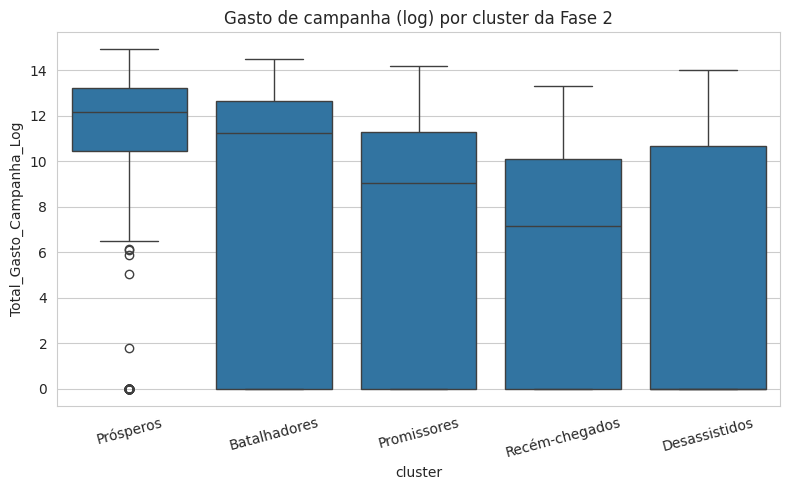

In [90]:
plt.figure(figsize=(8, 5))
ordem = list(NOMES.values())
sns.boxplot(data=df_cluster, x='cluster', y='Total_Gasto_Campanha_Log', order=ordem)
plt.title('Gasto de campanha (log) por cluster da Fase 2')
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

## Rodando o K-Means com a 4ª variável e comparando

Comparamos o K-Means (k=5, para casar com os cinco grupos nomeados) **sem** e **com** `Total_Gasto_Campanha_Log`: a silhouette de cada um e uma tabela cruzando os rótulos (quantos candidatos trocam de grupo quando o gasto entra). Em seguida, o radar mostra o **perfil dos cinco clusters nomeados** nas quatro variáveis-driver — agora incluindo o gasto de campanha.

In [91]:
colunas_driver4 = ['IDADE', 'ANOS_ESTUDO', 'Total_Bens_Log', 'Total_Gasto_Campanha_Log']
X4 = MinMaxScaler().fit_transform(df_cluster[colunas_driver4])

lab3 = KMeans(5, random_state=SEMENTE, n_init=10).fit_predict(X3)
km4 = KMeans(5, random_state=SEMENTE, n_init=10).fit(X4)
lab4 = km4.labels_

print(f"Silhouette K-Means k=5, 3 variáveis (idade, estudo, bens):            {silhouette_score(X3, lab3):.3f}")
print(f"Silhouette K-Means k=5, 4 variáveis (+ gasto de campanha):            {silhouette_score(X4, lab4):.3f}")

tab = pd.crosstab(pd.Series(lab3, name='3 variáveis'), pd.Series(lab4, name='4 variáveis'))
print("\nComo os candidatos se redistribuem (rótulos numéricos, sem nome):")
display(tab)

Silhouette K-Means k=5, 3 variáveis (idade, estudo, bens):            0.365
Silhouette K-Means k=5, 4 variáveis (+ gasto de campanha):            0.419

Como os candidatos se redistribuem (rótulos numéricos, sem nome):


4 variáveis,0,1,2,3,4
3 variáveis,,,,,
0,0,76,82,0,0
1,166,0,0,35,3
2,0,62,82,0,0
3,0,0,0,57,116
4,184,0,0,40,22


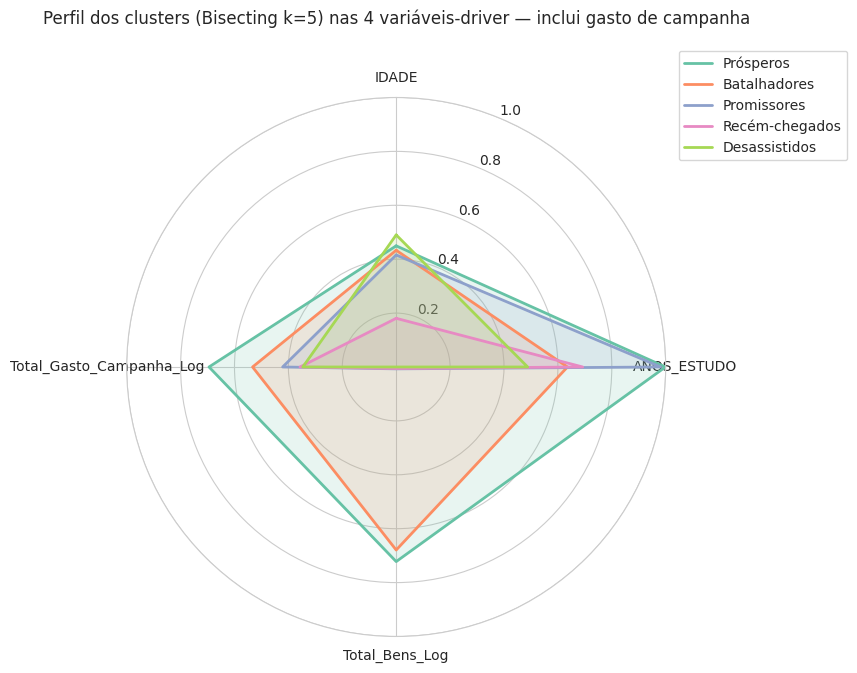

In [92]:
# Radar: perfil dos clusters NOMEADOS (Bisecting k=5) nas 4 variáveis-driver, incluindo o gasto (escala 0-1)
centros = np.array([X4[df_cluster['cluster'].values == nome].mean(axis=0) for nome in NOMES.values()])
labels_series = list(NOMES.values())
cores = dict(zip(labels_series, sns.color_palette('Set2', n_colors=len(labels_series))))
ang = [n / float(len(colunas_driver4)) * 2 * pi for n in range(len(colunas_driver4))]; ang += ang[:1]
fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
ax.set_theta_offset(pi / 2); ax.set_theta_direction(-1)
ax.set_xticks(ang[:-1]); ax.set_xticklabels(colunas_driver4); ax.set_ylim(0, 1)
for i, nome in enumerate(labels_series):
    v = list(centros[i]) + [centros[i][0]]
    ax.plot(ang, v, linewidth=2, label=nome, color=cores[nome])
    ax.fill(ang, v, alpha=0.15, color=cores[nome])
ax.set_title('Perfil dos clusters (Bisecting k=5) nas 4 variáveis-driver — inclui gasto de campanha', y=1.12)
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1)); plt.show()

### Resposta da Parte 1

- **Gasto de campanha ≠ patrimônio pessoal.** A correlação entre `Total_Bens_Log` e `Total_Gasto_Campanha_Log` é de apenas **~0,36** — positiva, mas fraca. Ter patrimônio ajuda, mas não determina quanto a campanha investe.
- **Os perfis *estabelecidos* (com patrimônio) gastam mais**, sim (maior gasto mediano e maior % que gastou algo), mas **não são os únicos**: há candidatos dos três perfis *sem* patrimônio declarado (escolarizados, jovens e de baixa escolaridade) que mesmo assim contrataram despesas relevantes. Gasto capta uma dimensão de **mobilização/estrutura de campanha** que o patrimônio (foto estática antes da eleição) não enxerga.
- **Impacto nos clusters:** ao incluir o gasto como 4ª variável, a silhouette e a redistribuição (tabela acima) mostram que os grupos se **reorganizam parcialmente** — o eixo "quanto a campanha está investindo" não é redundante com os outros três.

---
# Parte 2 — Faixas por quartil para o Apriori

O Apriori (Fase 3) só enxerga **itens categóricos**. Por isso `IDADE`, `ANOS_ESTUDO`, `Total_Bens_Log` (e agora `Total_Gasto_Campanha_Log`) ficavam de fora da cesta. Aqui criamos, para cada variável numérica-driver, uma versão categórica em 4 faixas (`Q1`..`Q4`) por quartil — assim elas viram itens de verdade (ex.: `IDADE_Faixa=Q1`).

In [93]:
driver_num = ['IDADE', 'ANOS_ESTUDO', 'Total_Bens_Log', 'Total_Gasto_Campanha_Log']

def qcut_quartis(s):
    """Quartis (Q1..Q4). Se houver muitos empates (ex.: zeros), duplicates=drop funde
    faixas — então geramos os rótulos com o MESMO número de faixas que sobrou, evitando o
    erro "Bin labels must be one fewer than the number of bin edges"."""
    bins = pd.qcut(s, q=4, duplicates='drop')          # sem rótulo: só pra contar as faixas
    k = bins.cat.categories.size
    rotulos = [f'Q{i+1}' for i in range(k)]
    return pd.qcut(s, q=4, labels=rotulos, duplicates='drop')

for col in driver_num:
    faixa = f'{col}_Faixa'
    df_cluster[faixa] = qcut_quartis(df_cluster[col])
    n_faixas = df_cluster[faixa].cat.categories.size
    print(f"{col:26s} -> {n_faixas} faixa(s): {list(df_cluster[faixa].cat.categories)}")
    if n_faixas < 4:
        print(f"   [atencao] menos de 4 faixas: muitos valores repetidos (ex.: zeros).")

IDADE                      -> 4 faixa(s): ['Q1', 'Q2', 'Q3', 'Q4']
ANOS_ESTUDO                -> 2 faixa(s): ['Q1', 'Q2']
   [atencao] menos de 4 faixas: muitos valores repetidos (ex.: zeros).
Total_Bens_Log             -> 3 faixa(s): ['Q1', 'Q2', 'Q3']
   [atencao] menos de 4 faixas: muitos valores repetidos (ex.: zeros).
Total_Gasto_Campanha_Log   -> 3 faixa(s): ['Q1', 'Q2', 'Q3']
   [atencao] menos de 4 faixas: muitos valores repetidos (ex.: zeros).


**Cuidado documentado:** `Total_Bens_Log` e `Total_Gasto_Campanha_Log` têm muitos empates em **zero** (candidatos sem bens / sem gasto declarado). O `pd.qcut` com `duplicates='drop'` funde quartis vazios, então essas variáveis saem com **menos de 4 faixas** — o que é esperado e informativo (o "quartil de baixo" é, na prática, "declarou zero"). As faixas efetivas de cada variável estão impressas acima.

## Uma regra de associação nova, usando uma faixa

Montamos a cesta do Apriori acrescentando as colunas `_Faixa` (além de partido, gênero, cluster etc.) e procuramos ao menos uma regra que **só é possível agora** — envolvendo uma faixa de idade, escolaridade, patrimônio ou gasto.

In [94]:
colunas_apriori = ['SG_PARTIDO', 'DS_GENERO', 'DS_COR_RACA', 'cluster',
                   'IDADE_Faixa', 'ANOS_ESTUDO_Faixa', 'Total_Bens_Log_Faixa',
                   'Total_Gasto_Campanha_Log_Faixa']
if mostrar_por_uf:
    colunas_apriori.append('SG_UF')

cesta_base = df_cluster[['SQ_CANDIDATO'] + colunas_apriori].copy()
for c in colunas_apriori:
    cesta_base[c] = cesta_base[c].astype(str)
cesta = pd.get_dummies(cesta_base.set_index('SQ_CANDIDATO'), columns=colunas_apriori, prefix_sep='=')
print(f"{cesta.shape[0]} cestas x {cesta.shape[1]} itens")

itens = apriori(cesta, min_support=0.03, use_colnames=True)
regras = association_rules(itens, metric='lift', min_threshold=1)
regras['qtd'] = (regras['support'] * len(cesta)).round().astype(int)

def fmt(d):
    d = d.copy()
    d['antecedents'] = d['antecedents'].apply(lambda x: ', '.join(sorted(map(str, x))))
    d['consequents'] = d['consequents'].apply(lambda x: ', '.join(sorted(map(str, x))))
    return d[['antecedents', 'consequents', 'qtd', 'support', 'confidence', 'lift']]

# regras que envolvem ALGUMA faixa (a novidade desta parte)
tem_faixa = regras.apply(lambda r: any('_Faixa=' in str(i) for i in (r['antecedents'] | r['consequents'])), axis=1)
novas = regras[tem_faixa & (regras['antecedents'].apply(len) <= 2) & (regras['consequents'].apply(len) == 1)]
display(fmt(novas.sort_values('lift', ascending=False).head(12)))

925 cestas x 59 itens


,antecedents,consequents,qtd,support,confidence,lift
2472,"ANOS_ESTUDO_Faixa=Q1, IDADE_Faixa=Q1",cluster=Recém-chegados,52,0.06,0.63,6.30
2134,"ANOS_ESTUDO_Faixa=Q1, IDADE_Faixa=Q3",cluster=Desassistidos,29,0.03,0.44,6.16
426,"IDADE_Faixa=Q1, Total_Gasto_Campanha_Log_Faixa=Q1",SG_PARTIDO=MISSÃO,29,0.03,0.20,5.17
2146,"ANOS_ESTUDO_Faixa=Q1, Total_Bens_Log_Faixa=Q1",cluster=Desassistidos,66,0.07,0.35,4.97
2479,"IDADE_Faixa=Q1, Total_Bens_Log_Faixa=Q1",cluster=Recém-chegados,79,0.09,0.47,4.73
2140,"IDADE_Faixa=Q3, Total_Bens_Log_Faixa=Q1",cluster=Desassistidos,29,0.03,0.32,4.52
2485,"IDADE_Faixa=Q1, Total_Gasto_Campanha_Log_Faixa=Q1",cluster=Recém-chegados,64,0.07,0.44,4.47
2086,"ANOS_ESTUDO_Faixa=Q1, Total_Bens_Log_Faixa=Q3",cluster=Batalhadores,44,0.05,1.00,4.45
2080,"ANOS_ESTUDO_Faixa=Q1, Total_Bens_Log_Faixa=Q2",cluster=Batalhadores,59,0.06,1.00,4.45
2152,"ANOS_ESTUDO_Faixa=Q1, Total_Gasto_Campanha_Log_Faixa=Q1",cluster=Desassistidos,53,0.06,0.30,4.17


In [95]:
# destaque: o que caracteriza o quartil mais alto de gasto de campanha (Q_alto)?
faixas_gasto = list(df_cluster['Total_Gasto_Campanha_Log_Faixa'].cat.categories)
q_alto = faixas_gasto[-1]
alvo = f'Total_Gasto_Campanha_Log_Faixa={q_alto}'
sel = regras[regras['consequents'].apply(lambda x: len(x) == 1 and next(iter(x)) == alvo)
             & regras['antecedents'].apply(lambda x: len(x) <= 2)]
print(f"Regras que preveem o maior quartil de gasto de campanha ({alvo}):")
display(fmt(sel.sort_values('lift', ascending=False).head(8)))

Regras que preveem o maior quartil de gasto de campanha (Total_Gasto_Campanha_Log_Faixa=Q3):


,antecedents,consequents,qtd,support,confidence,lift
86,SG_PARTIDO=UNIÃO,Total_Gasto_Campanha_Log_Faixa=Q3,35,0.04,0.71,2.86
523,"ANOS_ESTUDO_Faixa=Q2, SG_PARTIDO=REPUBLICANOS",Total_Gasto_Campanha_Log_Faixa=Q3,31,0.03,0.63,2.53
78,SG_PARTIDO=REPUBLICANOS,Total_Gasto_Campanha_Log_Faixa=Q3,39,0.04,0.63,2.52
2646,"IDADE_Faixa=Q2, Total_Bens_Log_Faixa=Q3",Total_Gasto_Campanha_Log_Faixa=Q3,33,0.04,0.51,2.03
1648,"DS_COR_RACA=BRANCA, Total_Bens_Log_Faixa=Q3",Total_Gasto_Campanha_Log_Faixa=Q3,57,0.06,0.49,1.95
873,"DS_GENERO=FEMININO, Total_Bens_Log_Faixa=Q3",Total_Gasto_Campanha_Log_Faixa=Q3,31,0.03,0.48,1.94
2005,"DS_COR_RACA=PARDA, Total_Bens_Log_Faixa=Q3",Total_Gasto_Campanha_Log_Faixa=Q3,47,0.05,0.48,1.92
2449,"Total_Bens_Log_Faixa=Q3, cluster=Prósperos",Total_Gasto_Campanha_Log_Faixa=Q3,85,0.09,0.48,1.91


### Resposta da Parte 2

Com as faixas por quartil passamos a poder escrever regras como *"`IDADE_Faixa=Q1` + `SG_PARTIDO=X` → `cluster=Recém-chegados`"* ou *"`cluster=Prósperos` → `Total_Gasto_Campanha_Log_Faixa=Q_alto`"* — cruzamentos entre uma variável **numérica discretizada** e as categóricas que **antes eram impossíveis**, porque o Apriori não aceitava número contínuo. As tabelas acima trazem, entre as regras de maior lift, exemplos que usam pelo menos uma coluna `_Faixa`.

> Observação: como `Total_Bens_Log_Faixa` e `Total_Gasto_Campanha_Log_Faixa` têm menos de 4 faixas (empates em zero), o "quartil mais alto" delas concentra quem de fato declarou valores — é isso que as regras capturam.

---
## Fechamento

- **Parte 1:** trouxemos `Total_Gasto_Campanha` (despesas **contratadas**, agregadas por `SQ_CANDIDATO`) e `Total_Gasto_Campanha_Log`. Gasto de campanha correlaciona-se **fracamente** (~0,36) com patrimônio: é uma dimensão própria. Incluído como 4ª variável, reorganiza parcialmente os clusters.
- **Parte 2:** criamos as colunas `_Faixa` (quartis) de todas as variáveis-driver e mostramos regras de associação novas que só existem graças à discretização — documentando o efeito dos empates em zero, que reduzem o número de faixas de patrimônio e gasto.

As novas colunas ficam em `df_cluster`; se quiser versioná-las, salve `df_cluster.to_csv('dados/candidatos_%s_%s_%d_desafio.csv' % (nome_cargo, nome_uf, ANO_ELEICAO), index=False)`.

---

# Fase 2 (estendida) — Clusterização com 4 Variáveis

Reexecuta o Bisecting K-Means incluindo o **gasto de campanha** como 4ª variável-driver e compara com a solução de 3 variáveis (silhueta, perfis, reorganização dos clusters).

# Fase 2 (versão estendida) — Clusterização com **4 variáveis**
## Incluindo o **gasto de campanha realizado** como variável-driver

Recorte: **Deputados Federais da Região Norte** (AC, AM, AP, PA, RO, RR, TO).

Esta é uma extensão do `02_clusterizacao.ipynb`. A pergunta do desafio: **incluir o quanto cada candidato já gastou na própria campanha (uma 4ª variável, além de idade, escolaridade e patrimônio) muda os clusters?** Comparamos a solução de **3 variáveis** (oficial) com a de **4 variáveis**.

> Colab: se faltar alguma biblioteca, rode `!pip install -q "mlxtend==0.23.1"` no topo. Todo o resto (numpy, pandas, scikit-learn, matplotlib) já vem pronto.

## Configuração

In [96]:
CARGO = "DEPUTADO FEDERAL"                      # mesmo valor das Fases 0/1/2/3
UF = ["AC", "AM", "AP", "PA", "RO", "RR", "TO"]  # Região Norte
NOME_RECORTE = "NORTE"
ANO_ELEICAO = 2026
SEMENTE = 42                                     # reprodutibilidade (igual às outras fases)

## Preparação da base — idade, escolaridade e patrimônio

In [97]:
import warnings; warnings.filterwarnings("ignore")
import io, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

np.random.seed(SEMENTE)
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold'})

arquivo = f"dados/candidatos_{CARGO.replace(' ', '_')}_{NOME_RECORTE}_{ANO_ELEICAO}.csv"
df = pd.read_csv(arquivo)

# escolaridade -> anos de estudo (mesma conversao da Versao 2 da Fase 2)
ANOS_ESTUDO_POR_GRAU = {
    'ANALFABETO': 0, 'LÊ E ESCREVE': 1,
    'ENSINO FUNDAMENTAL INCOMPLETO': 4, 'ENSINO FUNDAMENTAL COMPLETO': 8,
    'ENSINO MÉDIO INCOMPLETO': 9, 'ENSINO MÉDIO COMPLETO': 11,
    'SUPERIOR INCOMPLETO': 13, 'SUPERIOR COMPLETO': 16,
}
df['ANOS_ESTUDO'] = df['DS_GRAU_INSTRUCAO'].map(ANOS_ESTUDO_POR_GRAU)

df_cluster = df[df['ANOS_ESTUDO'].notna()].copy().reset_index(drop=True)
print(f"Base: {len(df_cluster)} candidatos")
df_cluster[['NM_URNA_CANDIDATO', 'IDADE', 'ANOS_ESTUDO', 'Total_Bens', 'Total_Bens_Log']].head()

Base: 925 candidatos


,NM_URNA_CANDIDATO,IDADE,ANOS_ESTUDO,Total_Bens,Total_Bens_Log
0,DR.. KEL GUIMARÃES,35,16,"60,000.00",11.00
1,FÁBIO ARAÚJO,45,16,"316,330.00",12.66
2,NEY AMORIM,49,16,"3,250,000.00",14.99
3,ANTÔNIA LÚCIA,56,16,"4,115,000.00",15.23
4,MINORU KINPARA,57,16,"2,226,244.57",14.62


## A 4ª variável: gasto de campanha (prestação de contas do TSE)

O TSE publica, **durante a campanha** (sistema IDC — Informações Durante a Campanha), quanto cada candidato já **contratou** de despesas. É uma variável financeira diferente do patrimônio: não é "quanto a pessoa tem", é "quanto a campanha dela está investindo agora".

Somamos as despesas por `SQ_CANDIDATO`. Candidato **sem registro** de despesa = **gasto zero** (a declaração é obrigatória; ausência significa que ainda não contratou nada). Aplicamos `log1p`, pela mesma razão do patrimônio (distribuição muito assimétrica).

In [98]:
ZIP_CONTAS = f"dados/prestacao_de_contas_eleitorais_candidatos_{ANO_ELEICAO}.zip"
ufs_recorte = UF if isinstance(UF, (list, tuple)) else [UF]

def valor_brasileiro(serie):
    """'2.000,00' -> 2000.00  (milhar='.', decimal=',')."""
    return (serie.astype(str).str.replace('.', '', regex=False)
                 .str.replace(',', '.', regex=False)
                 .replace({'nan': None}).astype(float))

quadros = []
with zipfile.ZipFile(ZIP_CONTAS) as z:
    for uf in ufs_recorte:
        nome = f"despesas_contratadas_candidatos_{ANO_ELEICAO}_{uf}.csv"
        with z.open(nome) as f:
            d = pd.read_csv(io.TextIOWrapper(f, encoding='latin-1'), sep=';',
                            usecols=['SQ_CANDIDATO', 'VR_DESPESA_CONTRATADA'])
        quadros.append(d)
desp = pd.concat(quadros, ignore_index=True)
desp['VR_DESPESA_CONTRATADA'] = valor_brasileiro(desp['VR_DESPESA_CONTRATADA'])

gasto = desp.groupby('SQ_CANDIDATO')['VR_DESPESA_CONTRATADA'].sum().rename('Total_Gasto_Campanha')
df_cluster = df_cluster.merge(gasto, on='SQ_CANDIDATO', how='left')
df_cluster['Total_Gasto_Campanha'] = df_cluster['Total_Gasto_Campanha'].fillna(0)          # NaN -> 0
df_cluster['Total_Gasto_Campanha_Log'] = np.log1p(df_cluster['Total_Gasto_Campanha'])

n_gastou = (df_cluster['Total_Gasto_Campanha'] > 0).sum()
print(f"Gastaram algo (>0): {n_gastou} de {len(df_cluster)}  ({n_gastou/len(df_cluster)*100:.0f}%)")
print(f"Gasto mediano de quem gastou: R$ {df_cluster.loc[df_cluster['Total_Gasto_Campanha']>0,'Total_Gasto_Campanha'].median():,.0f}")
corr = df_cluster['Total_Bens_Log'].corr(df_cluster['Total_Gasto_Campanha_Log'])
print(f"Correlação patrimônio x gasto de campanha (log): {corr:.3f}  (baixa -> dimensão nova)")

Gastaram algo (>0): 657 de 925  (71%)
Gasto mediano de quem gastou: R$ 181,072
Correlação patrimônio x gasto de campanha (log): 0.364  (baixa -> dimensão nova)


## Bisecting K-Means — 3 variáveis vs 4 variáveis

Mesma implementação manual da Fase 2 (critério de **inércia média**), com a mesma semente. Só muda o conjunto de variáveis.

In [99]:
colunas_3 = ['IDADE', 'ANOS_ESTUDO', 'Total_Bens_Log']
colunas_4 = ['IDADE', 'ANOS_ESTUDO', 'Total_Bens_Log', 'Total_Gasto_Campanha_Log']

X3 = MinMaxScaler().fit_transform(df_cluster[colunas_3])
X4 = MinMaxScaler().fit_transform(df_cluster[colunas_4])

def inercia(X, indices):
    if len(indices) < 2: return 0.0
    pontos = X[indices]; centro = pontos.mean(axis=0)
    return float(((pontos - centro) ** 2).sum(axis=1).mean())

def bisecting_kmeans(X, k, random_state=SEMENTE):
    clusters = {0: np.arange(X.shape[0])}; proximo = 1
    for _ in range(1, k):
        alvo = max(clusters, key=lambda c: inercia(X, clusters[c]))
        pai = clusters[alvo]
        if len(pai) < 2: break
        lab = KMeans(2, random_state=random_state, n_init=10).fit_predict(X[pai])
        a, b = proximo, proximo + 1; proximo += 2
        del clusters[alvo]; clusters[a] = pai[lab == 0]; clusters[b] = pai[lab == 1]
    return clusters

def rotular(X, k):
    cl = bisecting_kmeans(X, k)
    ids = sorted(cl, key=lambda c: len(cl[c]), reverse=True)   # A = maior cluster
    rot = np.empty(X.shape[0], dtype=object)
    for letra, cid in zip([chr(65+i) for i in range(len(ids))], ids):
        rot[cl[cid]] = letra
    return rot
print("Funções prontas.")

Funções prontas.


### Quantos clusters? Silhueta com 3 e com 4 variáveis

 k  silhueta_3var  silhueta_4var
 2           0.56           0.43
 3           0.44           0.47
 4           0.41           0.51
 5           0.36           0.42
 6           0.37           0.37
 7           0.38           0.36
 8           0.39           0.34


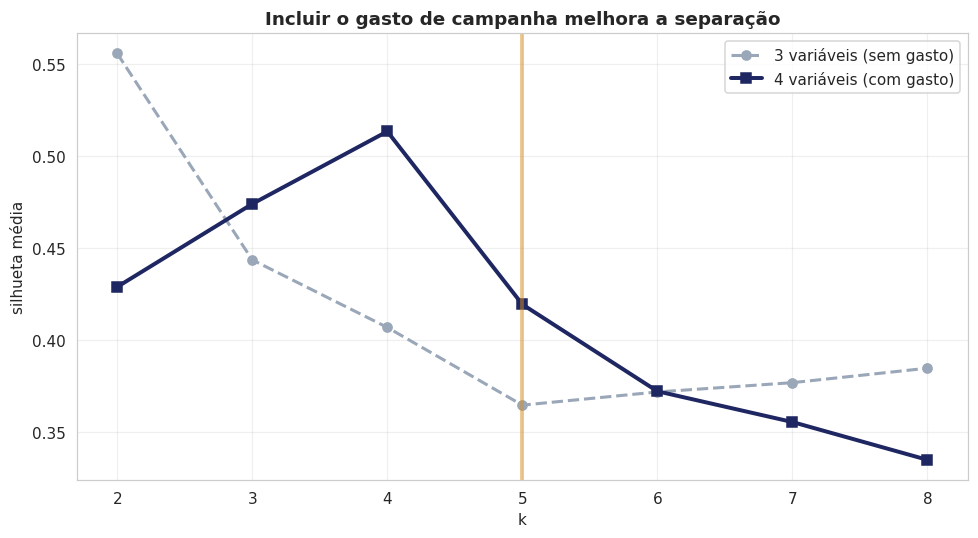

In [100]:
ks = range(2, 9)
sil3, sil4 = [], []
for k in ks:
    sil3.append(silhouette_score(X3, KMeans(k, random_state=SEMENTE, n_init=10).fit_predict(X3)))
    sil4.append(silhouette_score(X4, KMeans(k, random_state=SEMENTE, n_init=10).fit_predict(X4)))

comp = pd.DataFrame({'k': list(ks), 'silhueta_3var': np.round(sil3,3), 'silhueta_4var': np.round(sil4,3)})
print(comp.to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(list(ks), sil3, 'o--', color='#9aa7b8', lw=2, label='3 variáveis (sem gasto)')
ax.plot(list(ks), sil4, 's-', color='#1E2761', lw=2.6, label='4 variáveis (com gasto)')
ax.axvline(5, color='#D98E1E', lw=2.5, alpha=.5)
ax.set_xlabel('k'); ax.set_ylabel('silhueta média'); ax.set_xticks(list(ks))
ax.set_title('Incluir o gasto de campanha melhora a separação')
ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.show()

A silhueta com 4 variáveis fica **acima** da de 3 variáveis em k = 3, 4 e 5, com **pico em k = 4**. Mantemos **k = 5** (o mesmo do projeto) para comparar diretamente as duas soluções.

In [101]:
k_final = 5
# Rótulos aproximados aos perfis oficiais; os qualificadores preservam diferenças da solução com gasto.
NOMES_4VAR = {'A': 'Prósperos', 'B': 'Desassistidos (sem gasto)', 'C': 'Batalhadores (sem gasto)',
              'D': 'Recém-chegados (investem)', 'E': 'Promissores'}
ORDEM = list(NOMES_4VAR.values())

df_cluster['cluster_3var'] = pd.Series(rotular(X3, k_final)).map(
    {'A':'Prósperos','B':'Batalhadores','C':'Promissores','D':'Recém-chegados','E':'Desassistidos'})
df_cluster['cluster_4var'] = pd.Series(rotular(X4, k_final)).map(NOMES_4VAR)
df_cluster['cluster_4var'] = pd.Categorical(df_cluster['cluster_4var'], categories=ORDEM, ordered=True)

print("Tamanho dos clusters (4 variáveis):")
print(df_cluster['cluster_4var'].value_counts().reindex(ORDEM))

Tamanho dos clusters (4 variáveis):
cluster_4var
Prósperos      495
Desassistidos (sem gasto)      138
Batalhadores (sem gasto)     133
Recém-chegados (investem)     80
Promissores     79
Name: count, dtype: int64


### Perfil dos 5 clusters (4 variáveis)

Os nomes seguem o vocabulário do resultado oficial quando há aproximação, e os qualificadores descrevem o efeito do gasto. **'Desassistidos (sem gasto)' é apenas um rótulo aproximado:** este grupo tem escolaridade média de cerca de 12,7 anos, portanto não equivale ao cluster oficial de baixa escolaridade.

In [102]:
perfil = (df_cluster.groupby('cluster_4var')
    .agg(n=('IDADE','size'), idade_media=('IDADE','mean'),
         anos_estudo=('ANOS_ESTUDO','mean'),
         patrimonio_mediano=('Total_Bens','median'),
         gasto_mediano=('Total_Gasto_Campanha','median'),
         gasto_medio=('Total_Gasto_Campanha','mean'))
    .reindex(ORDEM).round(1))
perfil

,n,idade_media,anos_estudo,patrimonio_mediano,gasto_mediano,gasto_medio
cluster_4var,,,,,,
Prósperos,495,49.40,14.50,"538,074.50","240,695.00","427,417.00"
Desassistidos (sem gasto),138,45.20,12.70,0.00,0.00,0.00
Batalhadores (sem gasto),133,49.10,13.10,"185,000.00",0.00,1.90
Recém-chegados (investem),80,39.40,10.00,0.00,"25,307.50","122,801.80"
Promissores,79,47.30,15.70,0.00,"68,416.50","176,242.90"


In [103]:
CORES = {'Prósperos':'#1f6f54','Desassistidos (sem gasto)':'#c0504d','Batalhadores (sem gasto)':'#2b7bba',
         'Recém-chegados (investem)':'#7a5aa6','Promissores':'#e8a33d'}
fig, axes = plt.subplots(1, 4, figsize=(15, 4.2))
metricas = [('idade_media','Idade média'), ('anos_estudo','Escolaridade (anos)'),
            ('patrimonio_mediano','Patrimônio mediano (R$)'), ('gasto_mediano','Gasto campanha mediano (R$)')]
for ax, (col, tit) in zip(axes, metricas):
    vals = perfil[col].values
    ax.barh(range(5), vals, color=[CORES[n] for n in ORDEM], edgecolor='white')
    ax.set_yticks(range(5)); ax.set_yticklabels(ORDEM if ax is axes[0] else ['']*5)
    ax.invert_yaxis(); ax.set_title(tit, fontsize=11); ax.spines[['top','right']].set_visible(False)
fig.suptitle('Perfis com 4 variáveis — o gasto de campanha entra como eixo', fontweight='bold')
plt.tight_layout(); plt.show()

### O gasto é uma dimensão nova (não repete o patrimônio)

Se gasto e patrimônio fossem a mesma coisa, os pontos formariam uma diagonal. Em vez disso há candidatos com **patrimônio e gasto zero** (Batalhadores sem gasto) e candidatos **sem patrimônio que investem** (Recém-chegados que investem/Promissores). O grupo **Desassistidos (sem gasto)** também não equivale ao perfil oficial: sua escolaridade média é de aproximadamente 12,7 anos.

In [104]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
for n in ORDEM:
    sub = df_cluster[df_cluster['cluster_4var'] == n]
    ax.scatter(sub['Total_Bens_Log'], sub['Total_Gasto_Campanha_Log'],
               s=18, color=CORES[n], alpha=.6, label=n, edgecolors='none')
ax.set_xlabel('Patrimônio (log)'); ax.set_ylabel('Gasto de campanha (log)')
ax.set_title(f'Gasto × patrimônio — dimensões diferentes (r = {corr:.2f})')
ax.legend(markerscale=1.6); ax.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.show()

### Comparação: os clusters mudam?

Tabela cruzada entre a solução de **3 variáveis** (linhas) e a de **4 variáveis** (colunas). Se o gasto não trouxesse nada, cada linha cairia inteira numa única coluna. Não é o que acontece — os grupos se **reorganizam** ao longo do novo eixo.

In [105]:
ct = pd.crosstab(df_cluster['cluster_3var'], df_cluster['cluster_4var'])
print(ct)

mudou = (df_cluster['cluster_3var'].astype(str).values !=
         df_cluster['cluster_4var'].astype(str).values).sum()
print(f"\nCandidatos cujo rótulo NÃO é idêntico entre as duas soluções: {mudou} de {len(df_cluster)}")
print("(nomes diferem de propósito: os perfis mudaram ao incluir o gasto)")

cluster_4var    Prósperos  Desassistidos (sem gasto)  Batalhadores (sem gasto)  Recém-chegados (investem)  Promissores
cluster_3var                                                              
Batalhadores          139          0          69            0            0
Desassistidos           0         34           0           32            0
Promissores             4         62           1            1           77
Prósperos             351          0          63            0            0
Recém-chegados          1         42           0           47            2

Candidatos cujo rótulo NÃO é idêntico entre as duas soluções: 497 de 925
(nomes diferem de propósito: os perfis mudaram ao incluir o gasto)


## Conclusão

- **Incluir o gasto de campanha muda os clusters** e **melhora a silhueta** (em k=5: de ~0,37 para ~0,42; pico em k=4 ≈ 0,51).
- O gasto é uma **dimensão independente** do patrimônio (correlação ≈ 0,36).
- Os grupos passam a se separar por **"gasta na campanha × não gasta"**:
  - **Prósperos** — patrimônio alto **e** campanha robusta;
  - **Batalhadores (sem gasto)** — têm patrimônio, mas gasto de campanha **zero**;
  - **Desassistidos (sem gasto)** — sem patrimônio e sem gasto, mas com escolaridade média (não equivale ao cluster oficial);
  - **Recém-chegados (investem)** — mais jovens, sem patrimônio, e que **investem** na campanha;
  - **Promissores** — alta escolaridade, sem patrimônio, gasto moderado.
- Resposta ao desafio: **quem gasta mais não é simplesmente o mesmo grupo dos mais ricos** — o gasto revela quem realmente investe na disputa, independentemente do que já acumulou.

---

# Fase 3 — Regras de Associação (Apriori)

Regras nas duas direções (cluster → características e características → cluster), com grafos, discutindo se confirmam os nomes dos clusters.

# Fase 3 — Regras de Associação: Candidatos 2026 (TSE)

## Pergunta de negócio

> **Que combinações de características dos candidatos aparecem juntas com mais frequência do que se fossem independentes? Em particular: quais atributos (partido, gênero, escolaridade, cor/raça, UF de nascimento) estão associados a cada perfil identificado na Fase 2 — e, assim que a eleição ocorrer, a ser eleito?**

Até aqui, a clusterização (Fase 2) agrupou candidatos por **distância** em variáveis numéricas (idade, escolaridade, patrimônio). Regras de associação fazem uma pergunta diferente: em vez de "quem está perto de quem", **quais combinações de atributos categóricos aparecem juntas com mais frequência do que o acaso explicaria**? A técnica clássica pra isso é o **Apriori**, que originalmente resolve o problema da "cesta de compras" (que produtos são comprados juntos) — aqui, cada candidato é uma cesta, e cada valor de cada variável categórica (partido, gênero, escolaridade...) é um item dessa cesta.


## Configuração

Use os **mesmos valores** que você usou nas Fases 0/1/2, para carregar o arquivo certo.


In [106]:
CARGO = "DEPUTADO FEDERAL"
# Recorte deste trabalho: Deputados Federais da REGIÃO NORTE (7 UFs).
# O molde original do professor usa uma única UF (string) ou None (Brasil inteiro).
# Aqui estendemos a configuração: UF pode ser uma LISTA de siglas -> filtramos com .isin(...).
UF = ["AC", "AM", "AP", "PA", "RO", "RR", "TO"]   # None = Brasil; "SP" = uma UF; lista = região
NOME_RECORTE = "NORTE"     # rótulo usado no nome do arquivo quando UF é uma lista/região
ANO_ELEICAO = 2026

# Seções de comparação entre UFs: no molde do professor só rodavam na visão Brasil (UF = None).
# Como agora o recorte é uma região com 7 UFs, faz sentido rodá-las para comparar os estados.
mostrar_por_uf = (UF is None) or (isinstance(UF, (list, tuple, set)) and len(UF) > 1)

## Preparando a base — reconstituindo os clusters nomeados da Fase 2

Apriori precisa de **itens categóricos**, não de distância — mas queremos incluir o cluster da Fase 2 como mais um item da cesta. Na Fase 2 (`02_clusterizacao.ipynb`), o **Bisecting K-Means com k=5** foi o resultado final escolhido, e os cinco clusters foram batizados por perfil socioeconômico (Deputados Federais da Região Norte, 925 candidatos):

- **Prósperos** — 45%, com patrimônio e superior completo.
- **Batalhadores** — 22%, com patrimônio e ensino médio.
- **Promissores** — 16%, superior, sem patrimônio declarado.
- **Recém-chegados** — 10%, o mais jovem, sem patrimônio.
- **Desassistidos** — 7%, ensino fundamental, sem patrimônio.

Recalculamos aqui a mesma partição (mesma `SEMENTE`, mesmo critério, mesmos nomes) — mesma lógica de auto-suficiência do `02_clusterizacao_outros.ipynb`.

In [107]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from mlxtend.frequent_patterns import apriori, association_rules
from pyvis.network import Network
from IPython.display import IFrame

sns.set_style("whitegrid")
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)  # não truncar antecedents/consequents nas tabelas

SEMENTE = 42
np.random.seed(SEMENTE)  # mesmo racional de reprodutibilidade defensiva dos notebooks anteriores

nome_uf = 'BRASIL' if UF is None else (NOME_RECORTE if isinstance(UF, (list, tuple, set)) else UF)
nome_cargo = CARGO.replace(' ', '_')
arquivo = f"dados/candidatos_{nome_cargo}_{nome_uf}_{ANO_ELEICAO}.csv"

df = pd.read_csv(arquivo)
print(f"Carregado: {arquivo}  ->  {df.shape[0]} candidatos, {df.shape[1]} colunas")
df.head()


Carregado: dados/candidatos_DEPUTADO_FEDERAL_NORTE_2026.csv  ->  925 candidatos, 59 colunas


,DT_GERACAO,HH_GERACAO,ANO_ELEICAO,CD_TIPO_ELEICAO,NM_TIPO_ELEICAO,NR_TURNO,CD_ELEICAO,DS_ELEICAO,DT_ELEICAO,TP_ABRANGENCIA,SG_UF,SG_UE,NM_UE,CD_CARGO,DS_CARGO,SQ_CANDIDATO,NR_CANDIDATO,NM_CANDIDATO,NM_URNA_CANDIDATO,NM_SOCIAL_CANDIDATO,NR_CPF_CANDIDATO,DS_EMAIL,CD_SITUACAO_CANDIDATURA,DS_SITUACAO_CANDIDATURA,TP_AGREMIACAO,NR_PARTIDO,SG_PARTIDO,NM_PARTIDO,NR_FEDERACAO,NM_FEDERACAO,SG_FEDERACAO,DS_COMPOSICAO_FEDERACAO,SQ_COLIGACAO,NM_COLIGACAO,DS_COMPOSICAO_COLIGACAO,SG_UF_NASCIMENTO,DT_NASCIMENTO,NR_TITULO_ELEITORAL_CANDIDATO,CD_GENERO,DS_GENERO,CD_GRAU_INSTRUCAO,DS_GRAU_INSTRUCAO,CD_ESTADO_CIVIL,DS_ESTADO_CIVIL,CD_COR_RACA,DS_COR_RACA,CD_OCUPACAO,DS_OCUPACAO,CD_SIT_TOT_TURNO,DS_SIT_TOT_TURNO,BENS IMÓVEIS,BENS MÓVEIS,DINHEIRO,INVESTIMENTOS RENDA FIXA,INVESTIMENTOS RENDA VARIÁVEL,OUTROS BENS,Total_Bens,Total_Bens_Log,IDADE
0,23/08/2026,19:30:42,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,AC,AC,ACRE,6,DEPUTADO FEDERAL,10002532416,1567,ADGICLEIA DOS SANTOS GUIMARÃES,DR.. KEL GUIMARÃES,#NULO,1138048224,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,15,MDB,MOVIMENTO DEMOCRÁTICO BRASILEIRO,-1,#NULO,#NULO,#NULO,10001800109,PARTIDO ISOLADO,MDB,AC,1991-07-22,5979012437,4,FEMININO,8,SUPERIOR COMPLETO,3,CASADO(A),3,PARDA,111,MÉDICO,-1,#NULO,0.00,"60,000.00",0.00,0.00,0.00,0.00,"60,000.00",11.00,35
1,23/08/2026,19:30:42,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,AC,AC,ACRE,6,DEPUTADO FEDERAL,10002532417,1511,FÁBIO DE ARAÚJO FREITAS,FÁBIO ARAÚJO,#NULO,52152901215,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,15,MDB,MOVIMENTO DEMOCRÁTICO BRASILEIRO,-1,#NULO,#NULO,#NULO,10001800109,PARTIDO ISOLADO,MDB,AC,1981-06-25,3405502488,2,MASCULINO,8,SUPERIOR COMPLETO,3,CASADO(A),3,PARDA,278,VEREADOR,-1,#NULO,0.00,"266,330.00",0.00,"50,000.00",0.00,0.00,"316,330.00",12.66,45
2,23/08/2026,19:30:42,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,AC,AC,ACRE,6,DEPUTADO FEDERAL,10002532418,1577,JOZINEY ALVES AMORIM,NEY AMORIM,#NULO,59549050297,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,15,MDB,MOVIMENTO DEMOCRÁTICO BRASILEIRO,-1,#NULO,#NULO,#NULO,10001800109,PARTIDO ISOLADO,MDB,AC,1977-01-24,2849542429,2,MASCULINO,8,SUPERIOR COMPLETO,3,CASADO(A),1,BRANCA,257,EMPRESÁRIO,-1,#NULO,"3,250,000.00",0.00,0.00,0.00,0.00,0.00,"3,250,000.00",14.99,49
3,23/08/2026,19:30:42,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,AC,AC,ACRE,6,DEPUTADO FEDERAL,10002532419,1515,ANTÔNIA LUCILEIA CRUZ RAMOS CÂMARA,ANTÔNIA LÚCIA,#NULO,50791524272,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,15,MDB,MOVIMENTO DEMOCRÁTICO BRASILEIRO,-1,#NULO,#NULO,#NULO,10001800109,PARTIDO ISOLADO,MDB,AC,1970-07-17,16497022232,4,FEMININO,8,SUPERIOR COMPLETO,9,DIVORCIADO(A),3,PARDA,277,DEPUTADO,-1,#NULO,0.00,"195,000.00",0.00,0.00,0.00,"3,920,000.00","4,115,000.00",15.23,56
4,23/08/2026,19:30:42,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,AC,AC,ACRE,6,DEPUTADO FEDERAL,10002532420,1500,MINORU MARTINS KINPARA,MINORU KINPARA,#NULO,21722099291,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,15,MDB,MOVIMENTO DEMOCRÁTICO BRASILEIRO,-1,#NULO,#NULO,#NULO,10001800109,PARTIDO ISOLADO,MDB,GO,1968-12-02,1448152437,2,MASCULINO,8,SUPERIOR COMPLETO,3,CASADO(A),3,PARDA,142,PROFESSOR DE ENSINO SUPERIOR,-1,#NULO,"300,000.00","155,000.00",0.00,0.00,0.00,"1,771,244.57","2,226,244.57",14.62,57


In [108]:
ANOS_ESTUDO_POR_GRAU = {
    'ANALFABETO': 0,
    'LÊ E ESCREVE': 1,
    'ENSINO FUNDAMENTAL INCOMPLETO': 4,
    'ENSINO FUNDAMENTAL COMPLETO': 8,
    'ENSINO MÉDIO INCOMPLETO': 9,
    'ENSINO MÉDIO COMPLETO': 11,
    'SUPERIOR INCOMPLETO': 13,
    'SUPERIOR COMPLETO': 16,
    # 'NÃO DIVULGÁVEL' fica de fora de propósito — mesma decisão da Versão 2 do notebook de clusterização
}

df['ANOS_ESTUDO'] = df['DS_GRAU_INSTRUCAO'].map(ANOS_ESTUDO_POR_GRAU)


In [109]:
colunas_driver = ['IDADE', 'ANOS_ESTUDO', 'Total_Bens_Log']

Q1, Q3 = df['Total_Bens_Log'].quantile([0.25, 0.75])
IQR = Q3 - Q1
limite_superior = Q3 + 1.5 * IQR

df_cluster = df[(df['Total_Bens_Log'] <= limite_superior) & (df['ANOS_ESTUDO'].notna())].copy()
print(f"Base para clusterização/regras: {df_cluster.shape[0]} candidatos "
      f"(descartados {df.shape[0] - df_cluster.shape[0]} por patrimônio extremo ou escolaridade não divulgada)")

scaler = MinMaxScaler()
X = scaler.fit_transform(df_cluster[colunas_driver])


Base para clusterização/regras: 925 candidatos (descartados 0 por patrimônio extremo ou escolaridade não divulgada)


In [110]:
def inercia(indices):
    if len(indices) < 2:
        return 0.0
    pontos = X[indices]
    centro = pontos.mean(axis=0)
    return float(((pontos - centro) ** 2).sum(axis=1).mean())


def bisecting_kmeans_ate_k(X, k_max, random_state=SEMENTE):
    """Mesma lógica do 02_clusterizacao.ipynb (Parte 2, critério de inércia média) — mas só
    devolve a partição final em k_max clusters, sem guardar o histórico de divisões (essa
    exploração já foi feita e documentada lá)."""
    clusters = {0: np.arange(X.shape[0])}
    proximo_id = 1
    for _ in range(1, k_max):
        id_escolhido = max(clusters, key=lambda cid: inercia(clusters[cid]))
        indices_pai = clusters[id_escolhido]
        if len(indices_pai) < 2:
            break
        km2 = KMeans(n_clusters=2, random_state=random_state, n_init=10)
        labels2 = km2.fit_predict(X[indices_pai])
        id_a, id_b = proximo_id, proximo_id + 1
        proximo_id += 2
        del clusters[id_escolhido]
        clusters[id_a] = indices_pai[labels2 == 0]
        clusters[id_b] = indices_pai[labels2 == 1]
    return clusters


k_bisecting = 5  # mesmo k escolhido no 02_clusterizacao.ipynb (Parte 2)

clusters_finais = bisecting_kmeans_ate_k(X, k_bisecting)
ids_por_tamanho = sorted(clusters_finais, key=lambda cid: len(clusters_finais[cid]), reverse=True)

rotulos = np.empty(X.shape[0], dtype=object)
for letra, cid in zip([chr(65 + i) for i in range(len(ids_por_tamanho))], ids_por_tamanho):
    rotulos[clusters_finais[cid]] = letra
df_cluster['cluster_bisecting'] = rotulos

# mesmos nomes definidos no 02_clusterizacao.ipynb, a partir da mesma ficha técnica
NOMES_CLUSTER_BISECTING = {
    'A': 'Prósperos',
    'B': 'Batalhadores',
    'C': 'Promissores',
    'D': 'Recém-chegados',
    'E': 'Desassistidos',
}
df_cluster['cluster'] = df_cluster['cluster_bisecting'].map(NOMES_CLUSTER_BISECTING)
_ordem_nomes = [NOMES_CLUSTER_BISECTING[l] for l in sorted(NOMES_CLUSTER_BISECTING)]  # A..E
df_cluster['cluster'] = pd.Categorical(df_cluster['cluster'], categories=_ordem_nomes, ordered=True)

df_cluster['cluster'].value_counts()


cluster
Prósperos         414
Batalhadores      208
Promissores       145
Recém-chegados     92
Desassistidos      66
Name: count, dtype: int64

## Montando a "cesta" de itens

Apriori não trabalha com números contínuos como o K-Means — ele precisa de **itens binários** (presente/ausente), do mesmo jeito que "pão" e "leite" são itens numa cesta de supermercado. Cada linha vira uma "cesta" (um candidato), e cada valor de cada variável categórica vira um "item" via one-hot encoding (`SG_PARTIDO=PT`, `DS_GENERO=FEMININO`, `cluster=Prósperos`, ...).

Variáveis escolhidas:
- `SG_PARTIDO`, `DS_GENERO`, `DS_GRAU_INSTRUCAO`, `DS_ESTADO_CIVIL`, `DS_COR_RACA`, `SG_UF_NASCIMENTO` — perfil do candidato.
- `cluster` — o nome do cluster da Fase 2 (Bisecting K-Means, k=5), recalculado acima. Incluir o cluster como item deixa a pergunta "o que caracteriza cada cluster?" (já respondida via ficha técnica na Fase 2) ser respondida de novo do ponto de vista de regras — e permite achar combinações de 2+ variáveis que sozinhas não bastariam.
- `SG_UF` — só entra na visão Brasil (`UF=None`); com uma UF fixa ela teria um único valor e não discriminaria nada.
- `DS_SIT_TOT_TURNO` (eleito ou não) — só entra depois que a eleição de fato ocorrer (a coluna hoje vem toda com o mesmo valor, `#NULO`). A seção que usa isso fica pronta, mas roda condicionalmente lá na frente.

`DS_OCUPACAO` fica de fora por ora: são 49 categorias diferentes pra só ~200 candidatos — a maioria das ocupações teria 1 ou 2 candidatos, suporte baixo demais pra dizer qualquer coisa. Fica como exercício: agrupem em categorias maiores (ex.: "política", "direito", "saúde", "educação", "empresário"...) e testem.


In [111]:
colunas_apriori = ['SG_PARTIDO', 'DS_GENERO', 'DS_GRAU_INSTRUCAO', 'DS_ESTADO_CIVIL',
                   'DS_COR_RACA', 'SG_UF_NASCIMENTO', 'cluster']

if mostrar_por_uf:
    colunas_apriori.append('SG_UF')

# a eleição de 2026 ainda não ocorreu -> DS_SIT_TOT_TURNO vem toda com o mesmo valor por enquanto
usar_resultado_eleicao = df_cluster['DS_SIT_TOT_TURNO'].nunique() > 1
if usar_resultado_eleicao:
    colunas_apriori.append('DS_SIT_TOT_TURNO')

cesta_base = df_cluster[['SQ_CANDIDATO'] + colunas_apriori].copy()
cesta = pd.get_dummies(cesta_base, columns=colunas_apriori, prefix_sep='=')
cesta = cesta.set_index('SQ_CANDIDATO')

print(f"{cesta.shape[0]} candidatos (cestas) x {cesta.shape[1]} itens possíveis (um por valor de cada variável)")
cesta_base.head()


925 candidatos (cestas) x 87 itens possíveis (um por valor de cada variável)


,SQ_CANDIDATO,SG_PARTIDO,DS_GENERO,DS_GRAU_INSTRUCAO,DS_ESTADO_CIVIL,DS_COR_RACA,SG_UF_NASCIMENTO,cluster,SG_UF
0,10002532416,MDB,FEMININO,SUPERIOR COMPLETO,CASADO(A),PARDA,AC,Prósperos,AC
1,10002532417,MDB,MASCULINO,SUPERIOR COMPLETO,CASADO(A),PARDA,AC,Prósperos,AC
2,10002532418,MDB,MASCULINO,SUPERIOR COMPLETO,CASADO(A),BRANCA,AC,Prósperos,AC
3,10002532419,MDB,FEMININO,SUPERIOR COMPLETO,DIVORCIADO(A),PARDA,AC,Prósperos,AC
4,10002532420,MDB,MASCULINO,SUPERIOR COMPLETO,CASADO(A),PARDA,GO,Prósperos,AC


## Itens frequentes: o que aparece sozinho, com que frequência

O Apriori funciona em duas etapas. Primeiro, encontra **itemsets frequentes** — combinações de 1, 2, 3... itens que aparecem juntas em pelo menos `min_suporte` das cestas. Só depois, na segunda etapa, ele vira **regras** (`A → B`). Começamos pelos itemsets de um item só — a frequência "crua" de cada valor, antes de cruzar qualquer coisa.


In [112]:
min_suporte = 0.02  # ~4 candidatos; ajuste se quiser regras mais raras (menor) ou mais comuns (maior)

itens_frequentes = apriori(cesta, min_support=min_suporte, use_colnames=True)
print(f"{len(itens_frequentes)} itemsets frequentes (min_suporte={min_suporte})")

individuais = itens_frequentes[itens_frequentes['itemsets'].apply(lambda x: len(x) == 1)].copy()
individuais['item'] = individuais['itemsets'].apply(lambda x: next(iter(x)))
individuais['qtd_candidatos'] = (individuais['support'] * len(cesta)).round().astype(int)
individuais.sort_values('support', ascending=False)[['item', 'support', 'qtd_candidatos']].head(15)


1295 itemsets frequentes (min_suporte=0.02)


,item,support,qtd_candidatos
19,DS_GENERO=MASCULINO,0.61,560
24,DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO,0.59,544
31,DS_COR_RACA=PARDA,0.53,489
26,DS_ESTADO_CIVIL=CASADO(A),0.47,436
44,cluster=Prósperos,0.45,414
18,DS_GENERO=FEMININO,0.39,365
28,DS_ESTADO_CIVIL=SOLTEIRO(A),0.39,364
29,DS_COR_RACA=BRANCA,0.33,302
52,SG_UF=PA,0.28,262
38,SG_UF_NASCIMENTO=PA,0.28,259


### Suporte, confiança e lift — o que cada métrica mede

Regras de associação têm o formato **"se A, então B"** (A = antecedente, B = consequente), e três números resumem o quão forte é essa relação:

- **Suporte** — fração de candidatos em que A e B aparecem juntos: `suporte(A→B) = P(A e B)`. Mede o quão comum é a combinação; suporte baixo (poucos candidatos) é terreno fértil pra coincidência.
- **Confiança** — entre os candidatos que têm A, qual fração também tem B: `confiança(A→B) = P(B | A) = suporte(A e B) / suporte(A)`. É a "taxa de acerto" da regra.
- **Lift** — o quanto a confiança da regra é maior (ou menor) do que se A e B fossem independentes: `lift(A→B) = confiança(A→B) / suporte(B)`. `lift = 1` → A e B são independentes (a regra não diz nada); `lift > 1` → aparecem juntos mais do que o esperado ao acaso; `lift < 1` → aparecem juntos menos do que o esperado.

**Um cuidado importante nesta base:** ela tem só ~200 candidatos espalhados por 27 partidos e 27 estados — em média, uns 7 candidatos por partido ou por UF. Com grupos tão pequenos, bastam 3 ou 4 coincidências pra um lift parecer altíssimo, sem que isso signifique relação real nenhuma. Por isso toda tabela de regras abaixo vem com uma coluna `qtd_candidatos` — sempre olhem ela antes de confiar num lift alto.


In [113]:
regras = association_rules(itens_frequentes, metric='lift', min_threshold=1)
regras['qtd_candidatos'] = (regras['support'] * len(cesta)).round().astype(int)
regras = regras.sort_values('confidence', ascending=False)


def formatar_regras(df_regras):
    """Troca antecedents/consequents (frozenset) por texto legível, só pra exibição —
    os dados originais (usados pra filtrar/ordenar) continuam intactos."""
    df_fmt = df_regras.copy()
    df_fmt['antecedents'] = df_fmt['antecedents'].apply(lambda x: ', '.join(sorted(str(i) for i in x)))
    df_fmt['consequents'] = df_fmt['consequents'].apply(lambda x: ', '.join(sorted(str(i) for i in x)))
    return df_fmt


print(f"{len(regras)} regras (lift >= 1)")
formatar_regras(regras[['antecedents', 'consequents', 'qtd_candidatos', 'support', 'confidence', 'lift']].head(10))


8514 regras (lift >= 1)


,antecedents,consequents,qtd_candidatos,support,confidence,lift
8344,"DS_COR_RACA=PARDA, DS_GENERO=MASCULINO, SG_UF=PA, SG_UF_NASCIMENTO=PA, cluster=Prósperos",DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO,27,0.03,1.00,1.70
2613,"DS_GENERO=MASCULINO, SG_PARTIDO=PL, cluster=Prósperos",DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO,33,0.04,1.00,1.70
2573,"DS_COR_RACA=BRANCA, SG_PARTIDO=MDB, cluster=Prósperos",DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO,20,0.02,1.00,1.70
8398,"DS_COR_RACA=BRANCA, DS_ESTADO_CIVIL=CASADO(A), SG_UF=PA, SG_UF_NASCIMENTO=PA, cluster=Prósperos",DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO,22,0.02,1.00,1.70
8285,"DS_COR_RACA=BRANCA, DS_GENERO=MASCULINO, SG_UF=PA, SG_UF_NASCIMENTO=PA, cluster=Prósperos",DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO,26,0.03,1.00,1.70
2587,"DS_GENERO=MASCULINO, SG_PARTIDO=PDT, cluster=Prósperos",DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO,19,0.02,1.00,1.70
8457,"DS_COR_RACA=PARDA, DS_ESTADO_CIVIL=CASADO(A), SG_UF=PA, SG_UF_NASCIMENTO=PA, cluster=Prósperos",DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO,26,0.03,1.00,1.70
2670,"DS_ESTADO_CIVIL=CASADO(A), SG_PARTIDO=PL, cluster=Prósperos",DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO,32,0.03,1.00,1.70
2486,"SG_UF_NASCIMENTO=AC, cluster=Batalhadores",SG_UF=AC,22,0.02,1.00,9.07
2708,"DS_GENERO=MASCULINO, SG_PARTIDO=REPUBLICANOS, cluster=Prósperos",DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO,28,0.03,1.00,1.70


### Cuidado: suporte pequeno infla o lift

Vamos ver isso na prática: as regras de maior lift da base inteira, sem nenhum filtro de suporte, comparadas às regras de maior lift **exigindo pelo menos 10 candidatos** por trás delas.


In [114]:
regras_1_consequente = regras[regras['consequents'].apply(lambda x: len(x) == 1)].copy()
colunas_exibir = ['antecedents', 'consequents', 'qtd_candidatos', 'confidence', 'lift']

print("--- Maior lift, sem filtro de suporte ---")
display(formatar_regras(regras_1_consequente.sort_values('lift', ascending=False)[colunas_exibir].head(5)))

print("--- Maior lift, exigindo qtd_candidatos >= 10 ---")
display(formatar_regras(regras_1_consequente[regras_1_consequente['qtd_candidatos'] >= 10]
        .sort_values('lift', ascending=False)[colunas_exibir].head(5)))


--- Maior lift, sem filtro de suporte ---


,antecedents,consequents,qtd_candidatos,confidence,lift
5413,"DS_COR_RACA=PARDA, DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO, SG_UF=AP",SG_UF_NASCIMENTO=AP,27,0.75,12.61
7850,"DS_COR_RACA=PARDA, DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO, SG_UF=AP, cluster=Prósperos",SG_UF_NASCIMENTO=AP,19,0.73,12.29
4979,"DS_ESTADO_CIVIL=CASADO(A), DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO, SG_UF=AP",SG_UF_NASCIMENTO=AP,25,0.71,12.01
5925,"DS_COR_RACA=PARDA, SG_UF=AP, cluster=Prósperos",SG_UF_NASCIMENTO=AP,19,0.70,11.84
2396,"DS_COR_RACA=PARDA, SG_UF=AP",SG_UF_NASCIMENTO=AP,35,0.70,11.77


--- Maior lift, exigindo qtd_candidatos >= 10 ---


,antecedents,consequents,qtd_candidatos,confidence,lift
5413,"DS_COR_RACA=PARDA, DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO, SG_UF=AP",SG_UF_NASCIMENTO=AP,27,0.75,12.61
7850,"DS_COR_RACA=PARDA, DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO, SG_UF=AP, cluster=Prósperos",SG_UF_NASCIMENTO=AP,19,0.73,12.29
4979,"DS_ESTADO_CIVIL=CASADO(A), DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO, SG_UF=AP",SG_UF_NASCIMENTO=AP,25,0.71,12.01
5925,"DS_COR_RACA=PARDA, SG_UF=AP, cluster=Prósperos",SG_UF_NASCIMENTO=AP,19,0.70,11.84
2396,"DS_COR_RACA=PARDA, SG_UF=AP",SG_UF_NASCIMENTO=AP,35,0.70,11.77


No primeiro grupo, é comum ver pares como `SG_UF=ES → SG_UF_NASCIMENTO=ES` com lift acima de 30: candidatos a governador costumam concorrer no estado onde nasceram, então UF e UF de nascimento são quase a mesma informação — com só 4 ou 5 candidatos capixabas na base, a coincidência vira um lift enorme sem dizer nada de novo. No segundo grupo, com um piso de candidatos por trás da regra, sobram combinações genuinamente mais interessantes (ex.: escolaridade + gênero prevendo cluster). Essa é a leitura que vamos seguir usando daqui pra frente.

### Filtrando pra regras que valem a pena olhar


In [115]:
suporte_pratico = 0.03    # ~6 candidatos
confianca_pratica = 0.5

regras_simples = regras[
    regras['antecedents'].apply(lambda x: len(x) <= 2) & regras['consequents'].apply(lambda x: len(x) == 1)
]
regras_confiaveis = regras_simples[
    (regras_simples['support'] >= suporte_pratico) & (regras_simples['confidence'] >= confianca_pratica)
]

print(f"{len(regras_confiaveis)} regras com suporte >= {suporte_pratico} e confiança >= {confianca_pratica}")
formatar_regras(regras_confiaveis.sort_values('confidence', ascending=False)[colunas_exibir].head(15))


465 regras com suporte >= 0.03 e confiança >= 0.5


,antecedents,consequents,qtd_candidatos,confidence,lift
428,"SG_PARTIDO=MDB, cluster=Prósperos",DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO,39,1.00,1.70
672,"SG_PARTIDO=REPUBLICANOS, cluster=Prósperos",DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO,41,1.00,1.70
728,"SG_PARTIDO=UNIÃO, cluster=Prósperos",DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO,31,1.00,1.70
2120,"DS_ESTADO_CIVIL=CASADO(A), SG_UF_NASCIMENTO=AP",SG_UF=AP,30,1.00,10.39
351,SG_UF_NASCIMENTO=AP,SG_UF=AP,55,1.00,10.39
1848,"DS_COR_RACA=PRETA, cluster=Prósperos",DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO,38,1.00,1.70
1853,"SG_UF_NASCIMENTO=AC, cluster=Prósperos",DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO,37,1.00,1.70
2398,"DS_COR_RACA=PARDA, SG_UF_NASCIMENTO=AP",SG_UF=AP,35,1.00,10.39
627,"SG_PARTIDO=PSD, cluster=Prósperos",DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO,29,1.00,1.70
1954,"SG_UF=RR, cluster=Prósperos",DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO,47,1.00,1.70


## O que prediz o cluster de um candidato?

Filtramos as regras cujo **consequente é um único item de cluster** — "se o candidato tem tais características, ele cai no cluster X". É a mesma pergunta da Fase 2, agora pelo ângulo de combinações de atributos categóricos.

Um cuidado extra: os cinco clusters são **desbalanceados** (de ~45% no maior a ~7% no menor). Ordenar só por confiança encheria a tabela de regras "→ cluster majoritário" (fáceis de acertar, lift baixo). Por isso pegamos as regras de **maior lift dentro de cada cluster**, separadamente — assim os cinco aparecem e dá pra comparar a força relativa de cada um.

In [116]:
def regras_para_consequente(regras_completas, prefixo, n_por_valor=6, min_suporte=min_suporte, max_antecedentes=2):
    """
    Entre as regras cujo único item consequente comece com `prefixo` (ex.: 'cluster='),
    devolve as `n_por_valor` de MAIOR LIFT pra CADA valor distinto do consequente — sem piso
    de confiança fixo, porque um valor raro (poucos candidatos) não sustenta regras de
    confiança alta mesmo quando o lift é forte; ordenar só por confiança deixaria os valores
    mais comuns dominando a tabela inteira (ver célula anterior).
    """
    candidatas = regras_completas[
        regras_completas['consequents'].apply(lambda x: len(x) == 1 and next(iter(x)).startswith(prefixo))
        & regras_completas['antecedents'].apply(lambda x: len(x) <= max_antecedentes)
        & (regras_completas['support'] >= min_suporte)
    ].copy()
    candidatas['alvo'] = candidatas['consequents'].apply(lambda x: next(iter(x)))
    resultado = (candidatas.sort_values('lift', ascending=False)
                            .groupby('alvo', group_keys=False)
                            .head(n_por_valor)
                            .sort_values(['alvo', 'lift'], ascending=[True, False]))
    return resultado.drop(columns='alvo')


regras_cluster = regras_para_consequente(regras, 'cluster=')
print(f"{len(regras_cluster)} regras (até 6 por cluster, ordenadas por lift dentro de cada um)")
formatar_regras(regras_cluster[colunas_exibir])


30 regras (até 6 por cluster, ordenadas por lift dentro de cada um)


,antecedents,consequents,qtd_candidatos,confidence,lift
1626,"DS_GRAU_INSTRUCAO=ENSINO MÉDIO COMPLETO, SG_UF=TO",cluster=Batalhadores,23,0.88,3.93
1620,"DS_GRAU_INSTRUCAO=ENSINO MÉDIO COMPLETO, SG_UF=RO",cluster=Batalhadores,19,0.73,3.25
1508,"DS_ESTADO_CIVIL=CASADO(A), DS_GRAU_INSTRUCAO=ENSINO MÉDIO COMPLETO",cluster=Batalhadores,58,0.69,3.07
1982,"DS_ESTADO_CIVIL=CASADO(A), DS_GRAU_INSTRUCAO=SUPERIOR INCOMPLETO",cluster=Batalhadores,22,0.67,2.96
1092,"DS_GENERO=MASCULINO, DS_GRAU_INSTRUCAO=ENSINO MÉDIO COMPLETO",cluster=Batalhadores,82,0.65,2.87
1452,"DS_GENERO=MASCULINO, SG_UF_NASCIMENTO=TO",cluster=Batalhadores,19,0.63,2.82
1102,"DS_GENERO=MASCULINO, DS_GRAU_INSTRUCAO=ENSINO MÉDIO COMPLETO",cluster=Desassistidos,21,0.17,2.32
202,DS_GRAU_INSTRUCAO=ENSINO MÉDIO COMPLETO,cluster=Desassistidos,33,0.16,2.29
2236,"DS_COR_RACA=PARDA, DS_ESTADO_CIVIL=SOLTEIRO(A)",cluster=Desassistidos,19,0.10,1.43
285,DS_ESTADO_CIVIL=SOLTEIRO(A),cluster=Desassistidos,34,0.09,1.31


### Visualizando como grafo

Uma tabela com dezenas de regras é difícil de escanear — um grafo interativo ajuda a ver de relance quais itens aparecem mais como "explicação" (antecedentes) e quais aparecem mais como "resultado" (consequentes). Cada item vira um nó (`SG_PARTIDO=PCO`, `cluster=D`, ...); cada regra vira uma seta do antecedente pro consequente, com espessura proporcional à confiança. Os nós que começam com `cluster=` ficam destacados em vermelho e maiores, pra serem fáceis de achar no meio dos outros itens. Passe o mouse sobre uma seta pra ver confiança, lift e quantos candidatos sustentam aquela regra — e arraste os nós se a rede ficar embaralhada.


In [117]:
def grafo_regras_html(regras_plot, arquivo_html, titulo, prefixo_destaque='cluster='):
    """
    Desenha as regras como uma rede interativa (pyvis) e grava em `arquivo_html`. Cada REGRA
    vira um nó de antecedente e um nó de consequente (quando o antecedente tem mais de um
    item, eles aparecem juntos no mesmo nó, separados por "+") ligados por UMA única aresta
    — nunca uma aresta por item isolado, pra não sugerir que um item sozinho sustenta a
    confiança/lift de uma regra que na verdade depende da combinação inteira (era isso que
    causava setas duplicadas entre o mesmo par de nós). Nós que contêm algum item começando
    com `prefixo_destaque` (por padrão, os clusters da Fase 2) ficam destacados em vermelho e
    maiores. Espessura da aresta = confiança da regra; passe o mouse pra ver confiança, lift
    e quantos candidatos a sustentam. Os controles de física (embaixo do grafo) deixam
    ajustar a repulsão/gravidade entre os nós ao vivo.

    Retorna um IFrame carregando o arquivo — se aparecer em branco/preto aqui embaixo (alguns
    ambientes bloqueiam o JavaScript de saídas de célula em notebooks "não confiáveis"), abra
    `arquivo_html` direto no navegador; o grafo é o mesmo.
    """
    print(titulo)
    net = Network(height='600px', width='100%', bgcolor='#222222', font_color='white',
                  notebook=True, directed=True, cdn_resources='in_line')

    nos_adicionados = set()
    for _, row in regras_plot.iterrows():
        antecedente = ' + '.join(sorted(str(item) for item in row['antecedents']))
        consequente = ' + '.join(sorted(str(item) for item in row['consequents']))

        for label, itemset in [(antecedente, row['antecedents']), (consequente, row['consequents'])]:
            if label in nos_adicionados:
                continue
            destaque = any(str(item).startswith(prefixo_destaque) for item in itemset)
            net.add_node(
                label, label, title=label,
                color='#e41a1c' if destaque else '#1f78b4',
                size=30 if destaque else 12,
                font={'size': 22 if destaque else 14},
            )
            nos_adicionados.add(label)

        titulo_aresta = (f"Confiança: {row['confidence']:.2f} | Lift: {row['lift']:.2f} | "
                          f"{row['qtd_candidatos']} candidatos")
        net.add_edge(antecedente, consequente, value=row['confidence'], title=titulo_aresta)

    net.show_buttons(filter_=['physics'])
    # gravação à prova de Windows: força UTF-8 (o save_graph padrão usa a codificação do
    # sistema — cp1252 no Windows — e quebra com os acentos dos nomes de cluster)
    with open(arquivo_html, "w", encoding="utf-8") as _f:
        _f.write(net.generate_html())
    print(f"Grafo salvo em: {arquivo_html} — se não aparecer abaixo, abra esse arquivo no navegador.")
    return IFrame(arquivo_html, width='100%', height=750)


# passamos regras_cluster inteiro (já é balanceado: até 6 regras por cluster), para que
# TODOS os 5 clusters apareçam no grafo — head(20) cortava o último (Recém-chegados)
grafo_regras_html(regras_cluster, 'grafo_regras_cluster.html', 'O que prediz o cluster de um candidato?')


O que prediz o cluster de um candidato?
Grafo salvo em: grafo_regras_cluster.html — se não aparecer abaixo, abra esse arquivo no navegador.


## O que caracteriza quem já é de um cluster?

A seção anterior fixou o **consequente** (`cluster=X`) e perguntou o que o prediz. Agora invertemos: fixamos o **antecedente** — "dado que o candidato é do cluster X, ..." — e olhamos pra que outros itens aparecem como consequente com lift alto. É uma pergunta diferente, não a mesma coisa ao contrário: uma regra `A → B` de lift alto não garante que `B → A` também tenha lift alto (confiança e suporte de cada lado são diferentes), então vale olhar as duas direções separadamente.


In [118]:
def regras_para_antecedente(regras_completas, item_fixo, n=8, min_suporte=min_suporte, max_consequentes=1):
    """
    Entre as regras cujo antecedente é EXATAMENTE {item_fixo} (um único item), devolve as
    `n` de maior lift. Direção oposta de `regras_para_consequente`: lá fixamos o "efeito"
    (o consequente) e procurávamos o que o prediz; aqui fixamos a "causa" (o antecedente) e
    olhamos o que ela prediz.
    """
    candidatas = regras_completas[
        regras_completas['antecedents'].apply(lambda x: len(x) == 1 and next(iter(x)) == item_fixo)
        & regras_completas['consequents'].apply(lambda x: len(x) <= max_consequentes)
        & (regras_completas['support'] >= min_suporte)
    ]
    return candidatas.sort_values('lift', ascending=False).head(n)


regras_por_cluster_fixo = {
    nome: regras_para_antecedente(regras, nome)
    for nome in ['cluster=' + n for n in NOMES_CLUSTER_BISECTING.values()]
}

for item_fixo, subset in regras_por_cluster_fixo.items():
    print(f"--- {item_fixo} ({len(subset)} regras) ---")
    display(formatar_regras(subset[colunas_exibir]))


--- cluster=Prósperos (8 regras) ---


,antecedents,consequents,qtd_candidatos,confidence,lift
222,cluster=Prósperos,DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO,412,1.00,1.69
22,cluster=Prósperos,SG_PARTIDO=MDB,39,0.09,1.56
107,cluster=Prósperos,SG_PARTIDO=REPUBLICANOS,41,0.10,1.48
60,cluster=Prósperos,SG_PARTIDO=PL,47,0.11,1.46
87,cluster=Prósperos,SG_PARTIDO=PSD,29,0.07,1.44
121,cluster=Prósperos,SG_PARTIDO=UNIÃO,31,0.07,1.41
296,cluster=Prósperos,DS_COR_RACA=BRANCA,179,0.43,1.32
260,cluster=Prósperos,DS_ESTADO_CIVIL=DIVORCIADO(A),57,0.14,1.21


--- cluster=Batalhadores (8 regras) ---


,antecedents,consequents,qtd_candidatos,confidence,lift
199,cluster=Batalhadores,DS_GRAU_INSTRUCAO=ENSINO MÉDIO COMPLETO,117,0.56,2.58
237,cluster=Batalhadores,DS_GRAU_INSTRUCAO=SUPERIOR INCOMPLETO,48,0.23,2.32
366,cluster=Batalhadores,SG_UF_NASCIMENTO=TO,22,0.11,2.00
384,cluster=Batalhadores,SG_UF=TO,36,0.17,1.63
382,cluster=Batalhadores,SG_UF=RO,41,0.20,1.38
360,cluster=Batalhadores,SG_UF_NASCIMENTO=RO,22,0.11,1.38
70,cluster=Batalhadores,SG_PARTIDO=PODE,20,0.10,1.25
316,cluster=Batalhadores,DS_COR_RACA=PARDA,135,0.65,1.23


--- cluster=Promissores (8 regras) ---


,antecedents,consequents,qtd_candidatos,confidence,lift
41,cluster=Promissores,SG_PARTIDO=NOVO,22,0.15,2.38
388,cluster=Promissores,SG_UF=AP,22,0.15,1.58
224,cluster=Promissores,DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO,132,0.91,1.55
390,cluster=Promissores,SG_UF=PA,54,0.37,1.31
145,cluster=Promissores,DS_GENERO=FEMININO,75,0.52,1.31
353,cluster=Promissores,SG_UF_NASCIMENTO=PA,53,0.37,1.31
393,cluster=Promissores,SG_UF=RR,19,0.13,1.15
386,cluster=Promissores,SG_UF=AM,23,0.16,1.07


--- cluster=Recém-chegados (7 regras) ---


,antecedents,consequents,qtd_candidatos,confidence,lift
30,cluster=Recém-chegados,SG_PARTIDO=MISSÃO,19,0.21,5.31
239,cluster=Recém-chegados,DS_GRAU_INSTRUCAO=SUPERIOR INCOMPLETO,30,0.33,3.28
201,cluster=Recém-chegados,DS_GRAU_INSTRUCAO=ENSINO MÉDIO COMPLETO,51,0.55,2.54
282,cluster=Recém-chegados,DS_ESTADO_CIVIL=SOLTEIRO(A),70,0.76,1.93
354,cluster=Recém-chegados,SG_UF_NASCIMENTO=PA,39,0.42,1.51
394,cluster=Recém-chegados,SG_UF=PA,38,0.41,1.46
147,cluster=Recém-chegados,DS_GENERO=FEMININO,45,0.49,1.24


--- cluster=Desassistidos (5 regras) ---


,antecedents,consequents,qtd_candidatos,confidence,lift
203,cluster=Desassistidos,DS_GRAU_INSTRUCAO=ENSINO MÉDIO COMPLETO,33,0.50,2.29
284,cluster=Desassistidos,DS_ESTADO_CIVIL=SOLTEIRO(A),34,0.52,1.31
320,cluster=Desassistidos,DS_COR_RACA=PARDA,39,0.59,1.12
149,cluster=Desassistidos,DS_GENERO=FEMININO,27,0.41,1.04
396,cluster=Desassistidos,SG_UF=PA,19,0.29,1.02


### Visualizando como grafo (antecedente fixo)

Mesmo grafo interativo de antes, só que agora as três "causas" (os clusters) são o ponto de partida fixo, e os itens que aparecem como consequência é que variam.


In [119]:
regras_antecedente_fixo = pd.concat(regras_por_cluster_fixo.values())
grafo_regras_html(regras_antecedente_fixo, 'grafo_regras_antecedente_fixo.html', 'O que caracteriza quem já é de um cluster?')


O que caracteriza quem já é de um cluster?


Grafo salvo em: grafo_regras_antecedente_fixo.html — se não aparecer abaixo, abra esse arquivo no navegador.


## E quando a eleição já tiver ocorrido?

Esta seção só roda depois que a Fase 0 for rodada de novo com o resultado oficial (`DS_SIT_TOT_TURNO` deixa de vir toda com o mesmo valor `#NULO`) — por enquanto, ela se anuncia e não faz nada. Repare que não precisamos escrever nenhum código novo: como `DS_SIT_TOT_TURNO` já entrou na cesta lá na preparação (quando aplicável), a mesma `regras_para_consequente` e o mesmo `grafo_regras_html` servem pra essa pergunta também.


In [120]:
if usar_resultado_eleicao:
    regras_eleicao = regras_para_consequente(regras, 'DS_SIT_TOT_TURNO=')
    print(f"{len(regras_eleicao)} regras apontando para o resultado da eleição")
    display(formatar_regras(regras_eleicao[colunas_exibir].head(15)))
    grafo_regras_html(regras_eleicao.head(20), 'grafo_regras_eleicao.html', 'O que prediz ser eleito?', prefixo_destaque='DS_SIT_TOT_TURNO=')
else:
    print("DS_SIT_TOT_TURNO ainda não tem informação real (a eleição de 2026 não ocorreu) — "
          "essa seção fica pronta pra usar assim que a Fase 0 for rodada de novo com o resultado oficial. "
          "Por enquanto, pulamos.")


DS_SIT_TOT_TURNO ainda não tem informação real (a eleição de 2026 não ocorreu) — essa seção fica pronta pra usar assim que a Fase 0 for rodada de novo com o resultado oficial. Por enquanto, pulamos.


---
## Fechamento e próximos passos

Resumindo o roteiro: transformamos cada candidato numa "cesta" de atributos categóricos (partido, gênero, escolaridade, cor/raça, UF de nascimento, e o cluster da Fase 2), minerar itemsets frequentes com o Apriori, geramos regras `A → B` com suporte/confiança/lift, e aprendemos — na prática, não só na teoria — que suporte baixo infla lift artificialmente numa base pequena como esta.

**Exercícios sugeridos:**
- Agrupar `DS_OCUPACAO` em categorias maiores e incluir na cesta.
- Variar `min_suporte` (célula da seção "Itens frequentes") e ver como o número de regras muda.
- Replicar para `SENADOR` ou `DEPUTADO FEDERAL`, na sua UF — só muda a célula de configuração, do mesmo jeito que nas fases anteriores.
- Depois que a eleição ocorrer: rodar a Fase 0 de novo, e conferir se a seção "E quando a eleição já tiver ocorrido?" acima encontra regras fortes ligadas a `DS_SIT_TOT_TURNO=ELEITO`.

Próxima etapa do pipeline: `04_deteccao_anomalias.ipynb`.


---

# Fase 4 — Detecção de Anomalias (Isolation Forest)

Isolation Forest **global** e **por cluster**, com escolha do nível de contaminação e os principais casos atípicos em duas perspectivas.

# Fase 4 — Detecção de Anomalias: Candidatos 2026 (TSE)

## Pergunta de negócio

> **Existem candidatos com um perfil claramente atípico — seja em relação a toda a base, seja em relação ao grupo (cluster) a que pertencem?**

Isso é, na verdade, **duas perguntas diferentes**:

1. **Anomalia global** — esse candidato foge do padrão de todos os 925 candidatos a deputado federal da Região Norte, não importa o cluster?
2. **Anomalia local (dentro do cluster)** — esse candidato foge do padrão do **seu próprio grupo**? Um candidato pode ser perfeitamente comum na base inteira e ainda assim se destacar dentro do cluster **Recém-chegados** (ex.: o mais velho do grupo) — ou o contrário: parecer estranho olhando a base toda, mas ser exatamente o que se espera dentro do seu cluster.

Usamos os clusters nomeados na Fase 2 (`02_clusterizacao.ipynb`, Bisecting K-Means, k=5: **Prósperos**, **Batalhadores**, **Promissores**, **Recém-chegados**, **Desassistidos**) e o algoritmo **Isolation Forest** — diferente de tudo que vimos até aqui: K-Means/Bisecting/hierárquico procuram *grupos*; DBSCAN também procura densidade; o Isolation Forest procura diretamente **quem é fácil de isolar do resto**.


## Configuração

Use os **mesmos valores** que você usou nas Fases 0/1/2/3.


In [121]:
CARGO = "DEPUTADO FEDERAL"   # mesmo valor usado nas Fases 0/1/2/3
UF = ["AC", "AM", "AP", "PA", "RO", "RR", "TO"]   # Região Norte (mesmo recorte das Fases 0/1/2/3)
NOME_RECORTE = "NORTE"       # rótulo do recorte, usado no nome do arquivo salvo pela Fase 0
ANO_ELEICAO = 2026

## Preparando a base — reconstituindo os clusters nomeados da Fase 2

Mesma lógica de auto-suficiência já usada em `02_clusterizacao_outros.ipynb` e `03_regras_associacao.ipynb`: recalculamos aqui, rapidamente, o **Bisecting K-Means (k=5)** da Fase 2 e aplicamos os mesmos nomes — pra este notebook rodar sozinho, sem depender de nenhum arquivo intermediário salvo pelos outros.


In [122]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
import plotly.graph_objects as go

sns.set_style("whitegrid")
pd.set_option('display.max_columns', None)

SEMENTE = 42
np.random.seed(SEMENTE)  # mesmo racional de reprodutibilidade defensiva dos notebooks anteriores

nome_recorte = NOME_RECORTE if UF is not None else 'BRASIL'
nome_cargo = CARGO.replace(' ', '_')
arquivo = f"dados/candidatos_{nome_cargo}_{nome_recorte}_{ANO_ELEICAO}.csv"

df = pd.read_csv(arquivo)
print(f"Carregado: {arquivo}  ->  {df.shape[0]} candidatos, {df.shape[1]} colunas")
df.head()


Carregado: dados/candidatos_DEPUTADO_FEDERAL_NORTE_2026.csv  ->  925 candidatos, 59 colunas


,DT_GERACAO,HH_GERACAO,ANO_ELEICAO,CD_TIPO_ELEICAO,NM_TIPO_ELEICAO,NR_TURNO,CD_ELEICAO,DS_ELEICAO,DT_ELEICAO,TP_ABRANGENCIA,SG_UF,SG_UE,NM_UE,CD_CARGO,DS_CARGO,SQ_CANDIDATO,NR_CANDIDATO,NM_CANDIDATO,NM_URNA_CANDIDATO,NM_SOCIAL_CANDIDATO,NR_CPF_CANDIDATO,DS_EMAIL,CD_SITUACAO_CANDIDATURA,DS_SITUACAO_CANDIDATURA,TP_AGREMIACAO,NR_PARTIDO,SG_PARTIDO,NM_PARTIDO,NR_FEDERACAO,NM_FEDERACAO,SG_FEDERACAO,DS_COMPOSICAO_FEDERACAO,SQ_COLIGACAO,NM_COLIGACAO,DS_COMPOSICAO_COLIGACAO,SG_UF_NASCIMENTO,DT_NASCIMENTO,NR_TITULO_ELEITORAL_CANDIDATO,CD_GENERO,DS_GENERO,CD_GRAU_INSTRUCAO,DS_GRAU_INSTRUCAO,CD_ESTADO_CIVIL,DS_ESTADO_CIVIL,CD_COR_RACA,DS_COR_RACA,CD_OCUPACAO,DS_OCUPACAO,CD_SIT_TOT_TURNO,DS_SIT_TOT_TURNO,BENS IMÓVEIS,BENS MÓVEIS,DINHEIRO,INVESTIMENTOS RENDA FIXA,INVESTIMENTOS RENDA VARIÁVEL,OUTROS BENS,Total_Bens,Total_Bens_Log,IDADE
0,23/08/2026,19:30:42,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,AC,AC,ACRE,6,DEPUTADO FEDERAL,10002532416,1567,ADGICLEIA DOS SANTOS GUIMARÃES,DR.. KEL GUIMARÃES,#NULO,1138048224,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,15,MDB,MOVIMENTO DEMOCRÁTICO BRASILEIRO,-1,#NULO,#NULO,#NULO,10001800109,PARTIDO ISOLADO,MDB,AC,1991-07-22,5979012437,4,FEMININO,8,SUPERIOR COMPLETO,3,CASADO(A),3,PARDA,111,MÉDICO,-1,#NULO,0.00,"60,000.00",0.00,0.00,0.00,0.00,"60,000.00",11.00,35
1,23/08/2026,19:30:42,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,AC,AC,ACRE,6,DEPUTADO FEDERAL,10002532417,1511,FÁBIO DE ARAÚJO FREITAS,FÁBIO ARAÚJO,#NULO,52152901215,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,15,MDB,MOVIMENTO DEMOCRÁTICO BRASILEIRO,-1,#NULO,#NULO,#NULO,10001800109,PARTIDO ISOLADO,MDB,AC,1981-06-25,3405502488,2,MASCULINO,8,SUPERIOR COMPLETO,3,CASADO(A),3,PARDA,278,VEREADOR,-1,#NULO,0.00,"266,330.00",0.00,"50,000.00",0.00,0.00,"316,330.00",12.66,45
2,23/08/2026,19:30:42,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,AC,AC,ACRE,6,DEPUTADO FEDERAL,10002532418,1577,JOZINEY ALVES AMORIM,NEY AMORIM,#NULO,59549050297,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,15,MDB,MOVIMENTO DEMOCRÁTICO BRASILEIRO,-1,#NULO,#NULO,#NULO,10001800109,PARTIDO ISOLADO,MDB,AC,1977-01-24,2849542429,2,MASCULINO,8,SUPERIOR COMPLETO,3,CASADO(A),1,BRANCA,257,EMPRESÁRIO,-1,#NULO,"3,250,000.00",0.00,0.00,0.00,0.00,0.00,"3,250,000.00",14.99,49
3,23/08/2026,19:30:42,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,AC,AC,ACRE,6,DEPUTADO FEDERAL,10002532419,1515,ANTÔNIA LUCILEIA CRUZ RAMOS CÂMARA,ANTÔNIA LÚCIA,#NULO,50791524272,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,15,MDB,MOVIMENTO DEMOCRÁTICO BRASILEIRO,-1,#NULO,#NULO,#NULO,10001800109,PARTIDO ISOLADO,MDB,AC,1970-07-17,16497022232,4,FEMININO,8,SUPERIOR COMPLETO,9,DIVORCIADO(A),3,PARDA,277,DEPUTADO,-1,#NULO,0.00,"195,000.00",0.00,0.00,0.00,"3,920,000.00","4,115,000.00",15.23,56
4,23/08/2026,19:30:42,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,AC,AC,ACRE,6,DEPUTADO FEDERAL,10002532420,1500,MINORU MARTINS KINPARA,MINORU KINPARA,#NULO,21722099291,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,15,MDB,MOVIMENTO DEMOCRÁTICO BRASILEIRO,-1,#NULO,#NULO,#NULO,10001800109,PARTIDO ISOLADO,MDB,GO,1968-12-02,1448152437,2,MASCULINO,8,SUPERIOR COMPLETO,3,CASADO(A),3,PARDA,142,PROFESSOR DE ENSINO SUPERIOR,-1,#NULO,"300,000.00","155,000.00",0.00,0.00,0.00,"1,771,244.57","2,226,244.57",14.62,57


In [123]:
ANOS_ESTUDO_POR_GRAU = {
    'ANALFABETO': 0,
    'LÊ E ESCREVE': 1,
    'ENSINO FUNDAMENTAL INCOMPLETO': 4,
    'ENSINO FUNDAMENTAL COMPLETO': 8,
    'ENSINO MÉDIO INCOMPLETO': 9,
    'ENSINO MÉDIO COMPLETO': 11,
    'SUPERIOR INCOMPLETO': 13,
    'SUPERIOR COMPLETO': 16,
    # 'NÃO DIVULGÁVEL' fica de fora de propósito — mesma decisão da Versão 2 do notebook de clusterização
}

df['ANOS_ESTUDO'] = df['DS_GRAU_INSTRUCAO'].map(ANOS_ESTUDO_POR_GRAU)


In [124]:
colunas_driver = ['IDADE', 'ANOS_ESTUDO', 'Total_Bens_Log']

Q1, Q3 = df['Total_Bens_Log'].quantile([0.25, 0.75])
IQR = Q3 - Q1
limite_superior = Q3 + 1.5 * IQR

df_cluster = df[(df['Total_Bens_Log'] <= limite_superior) & (df['ANOS_ESTUDO'].notna())].copy()
df_cluster = df_cluster.reset_index(drop=True)
print(f"Base: {df_cluster.shape[0]} candidatos "
      f"(descartados {df.shape[0] - df_cluster.shape[0]} por patrimônio extremo ou escolaridade não divulgada)")

scaler = MinMaxScaler()
X = scaler.fit_transform(df_cluster[colunas_driver])


Base: 925 candidatos (descartados 0 por patrimônio extremo ou escolaridade não divulgada)


In [125]:
def inercia(indices):
    if len(indices) < 2:
        return 0.0
    pontos = X[indices]
    centro = pontos.mean(axis=0)
    return float(((pontos - centro) ** 2).sum(axis=1).mean())


def bisecting_kmeans_ate_k(X, k_max, random_state=SEMENTE):
    """Mesma lógica do 02_clusterizacao.ipynb (Parte 2, critério de inércia média) — só a
    partição final em k_max clusters, sem guardar o histórico de divisões."""
    clusters = {0: np.arange(X.shape[0])}
    proximo_id = 1
    for _ in range(1, k_max):
        id_escolhido = max(clusters, key=lambda cid: inercia(clusters[cid]))
        indices_pai = clusters[id_escolhido]
        if len(indices_pai) < 2:
            break
        km2 = KMeans(n_clusters=2, random_state=random_state, n_init=10)
        labels2 = km2.fit_predict(X[indices_pai])
        id_a, id_b = proximo_id, proximo_id + 1
        proximo_id += 2
        del clusters[id_escolhido]
        clusters[id_a] = indices_pai[labels2 == 0]
        clusters[id_b] = indices_pai[labels2 == 1]
    return clusters


k_bisecting = 5  # mesmo k escolhido no 02_clusterizacao.ipynb (Parte 2)

clusters_finais = bisecting_kmeans_ate_k(X, k_bisecting)
ids_por_tamanho = sorted(clusters_finais, key=lambda cid: len(clusters_finais[cid]), reverse=True)

rotulos = np.empty(X.shape[0], dtype=object)
for letra, cid in zip([chr(65 + i) for i in range(len(ids_por_tamanho))], ids_por_tamanho):
    rotulos[clusters_finais[cid]] = letra
df_cluster['cluster_bisecting'] = rotulos

# mesmos nomes definidos no 02_clusterizacao.ipynb, a partir da mesma ficha técnica
NOMES_CLUSTER_BISECTING = {
    'A': 'Prósperos',
    'B': 'Batalhadores',
    'C': 'Promissores',
    'D': 'Recém-chegados',
    'E': 'Desassistidos',
}
df_cluster['cluster'] = df_cluster['cluster_bisecting'].map(NOMES_CLUSTER_BISECTING)

# ordem A..E (do maior para o menor cluster) para legendas/tabelas saírem sempre na mesma ordem
_ordem_nomes = [NOMES_CLUSTER_BISECTING[l] for l in sorted(NOMES_CLUSTER_BISECTING)]
df_cluster['cluster'] = pd.Categorical(df_cluster['cluster'], categories=_ordem_nomes, ordered=True)

df_cluster['cluster'].value_counts()


cluster
Prósperos         414
Batalhadores      208
Promissores       145
Recém-chegados     92
Desassistidos      66
Name: count, dtype: int64

## Isolation Forest: como funciona

Todos os algoritmos das fases anteriores definem "normal" de forma indireta: K-Means olha distância até um centro, DBSCAN olha densidade de vizinhança. O **Isolation Forest** faz a pergunta ao contrário, e de forma bem mais direta: **quão fácil é isolar este ponto do resto, cortando o espaço aleatoriamente?**

A ideia, passo a passo:

1. Constrói várias **árvores de isolamento** (isolation trees). Cada árvore escolhe, em cada nó, uma variável **aleatória** e um ponto de corte **aleatório** entre o mínimo e o máximo daquela variável ali — sem nenhuma lógica de "melhor corte" como numa árvore de decisão comum.
2. Repete o corte recursivamente até que cada ponto fique sozinho numa partição.
3. Pontos **isolados** (poucos e diferentes do resto) tendem a cair sozinhos logo nos primeiros cortes — **caminho curto** da raiz até a folha. Pontos numa região **densa** (muitos vizinhos parecidos) precisam de muito mais cortes até se separarem de todo mundo — **caminho longo**.
4. O **score de anomalia** de cada ponto é a média do comprimento desse caminho em todas as árvores da floresta, normalizada — quanto **menor** o caminho médio, mais anômalo.

Duas vantagens práticas: não precisa calcular distância entre todos os pares de pontos (como DBSCAN/hierárquico), então escala bem; e não assume nenhuma forma pro que é "normal" (nem esférica, como K-Means, nem uma região densa contígua, como DBSCAN).

**O parâmetro `contamination`** é a fração de pontos que vocês **esperam de antemão** que sejam anômalos — é uma suposição de quem está modelando, não algo medido a partir dos dados (mesmo espírito do `k` do K-Means ou do `eps` do DBSCAN: um parâmetro que exige julgamento, não tem uma resposta "correta" automática).

### Vendo com dados fictícios

Como com dado real nunca sabemos de verdade quem é anômalo, geramos aqui uma base fictícia onde **nós** decidimos quem é "normal" (dois grupos bem comportados) e quem é "anômalo" (pontos espalhados aleatoriamente pelo espaço) — aí comparamos com o que o algoritmo encontra sozinho, sem ver esses rótulos.


In [126]:
rng = np.random.default_rng(SEMENTE)

# "normal": dois grupos bem comportados (como se fossem 2 clusters)
normal_1 = rng.normal(loc=[2, 2], scale=0.6, size=(80, 2))
normal_2 = rng.normal(loc=[6, 6], scale=0.6, size=(80, 2))
X_normal_ficticio = np.vstack([normal_1, normal_2])

# "anômalo": pontos espalhados aleatoriamente pelo espaço, longe dos dois grupos
X_anomalo_ficticio = rng.uniform(low=-2, high=10, size=(12, 2))

X_ficticio = np.vstack([X_normal_ficticio, X_anomalo_ficticio])
rotulo_real_ficticio = np.array(['Normal'] * len(X_normal_ficticio) + ['Anômalo (fictício)'] * len(X_anomalo_ficticio))

# contamination = a fração real de anômalos fictícios (aqui podemos "trapacear" porque sabemos)
iso_ficticio = IsolationForest(contamination=len(X_anomalo_ficticio) / len(X_ficticio),
                                random_state=SEMENTE, n_estimators=200)
pred_ficticio = iso_ficticio.fit_predict(X_ficticio)
score_ficticio = iso_ficticio.decision_function(X_ficticio)

print(f"Score médio — Normal: {score_ficticio[rotulo_real_ficticio == 'Normal'].mean():.3f}  |  "
      f"Anômalo: {score_ficticio[rotulo_real_ficticio == 'Anômalo (fictício)'].mean():.3f}")


Score médio — Normal: 0.132  |  Anômalo: -0.092


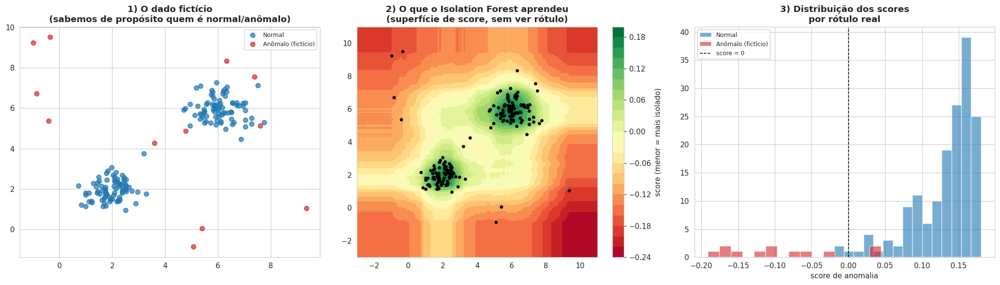

In [127]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

cores_ficticio = {'Normal': 'tab:blue', 'Anômalo (fictício)': 'tab:red'}
for rotulo, cor in cores_ficticio.items():
    m = rotulo_real_ficticio == rotulo
    axes[0].scatter(X_ficticio[m, 0], X_ficticio[m, 1], c=cor, label=rotulo, alpha=0.7, s=40)
axes[0].set_title('1) O dado fictício\n(sabemos de propósito quem é normal/anômalo)')
axes[0].legend(fontsize=8)

# superfície de score: o que o algoritmo "enxerga", sem ver rótulo nenhum
xx, yy = np.meshgrid(np.linspace(-3, 11, 300), np.linspace(-3, 11, 300))
Z = iso_ficticio.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
cs = axes[1].contourf(xx, yy, Z, levels=20, cmap='RdYlGn')
axes[1].scatter(X_ficticio[:, 0], X_ficticio[:, 1], c='black', s=12)
plt.colorbar(cs, ax=axes[1], label='score (menor = mais isolado)')
axes[1].set_title('2) O que o Isolation Forest aprendeu\n(superfície de score, sem ver rótulo)')

# distribuição dos scores por rótulo real
for rotulo, cor in cores_ficticio.items():
    m = rotulo_real_ficticio == rotulo
    axes[2].hist(score_ficticio[m], bins=15, color=cor, alpha=0.6, label=rotulo)
axes[2].axvline(0, color='black', linestyle='--', linewidth=1, label='score = 0')
axes[2].set_title('3) Distribuição dos scores\npor rótulo real')
axes[2].set_xlabel('score de anomalia')
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()


A superfície de score (painel 2) fica **verde** (score alto, "normal") bem em cima dos dois grupos densos, e **vermelha** (score baixo, "anômalo") nas bordas e longe de tudo — exatamente onde estão os pontos fictícios que geramos como "anômalos". O algoritmo nunca viu o rótulo `Normal`/`Anômalo (fictício)`: ele chegou nisso só de contar quão rápido cada ponto fica isolado. O histograma (painel 3) mostra a mesma coisa de outro ângulo: os scores dos pontos normais ficam concentrados bem acima de zero; os anômalos, misturados mais pra baixo — a separação não é perfeita (alguns anômalos fictícios caíram por sorte perto dos grupos densos), o que já é um bom aviso pra quando aplicarmos em dado real: o Isolation Forest não é infalível, é uma sugestão de onde olhar com mais atenção.


### Por dentro de uma única árvore

A superfície de score acima é o resultado **já combinado** de 200 árvores. Pra enxergar o mecanismo de verdade — os cortes aleatórios que dão nome ao algoritmo — olhamos uma árvore sozinha: cada linha abaixo é um corte (variável aleatória, ponto de corte aleatório entre o mínimo e o máximo ali). Escolhemos dois pontos de propósito — um bem no meio de um grupo denso, outro o mais "anômalo" segundo o próprio modelo — e comparamos quantos cortes cada um precisou até ficar sozinho numa partição.


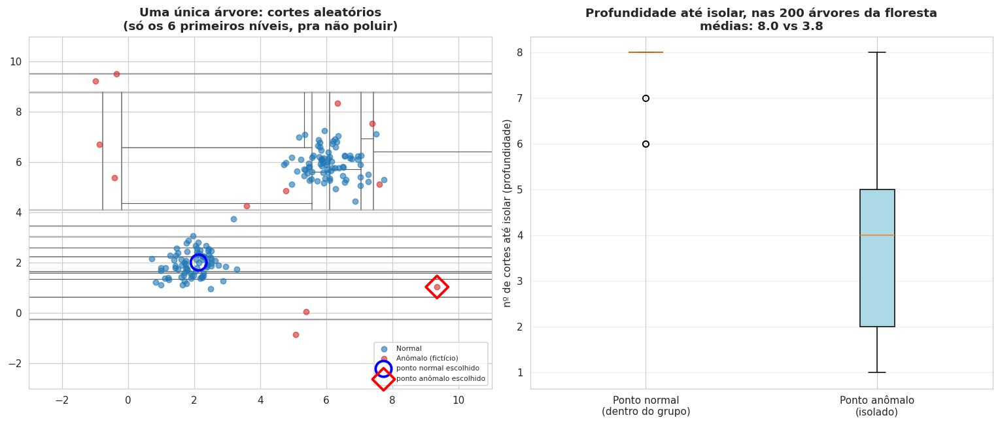

In [128]:
def desenhar_particoes(ax, tree_, no, x_min, x_max, y_min, y_max, profundidade=0, profundidade_max=6):
    """Desenha recursivamente os cortes de uma árvore de isolamento dentro de uma caixa
    [x_min,x_max] x [y_min,y_max]. Só os primeiros `profundidade_max` níveis são desenhados —
    a árvore de verdade continua até isolar cada ponto sozinho, mas isso poluiria demais o
    desenho sem ajudar a entender a ideia."""
    if profundidade >= profundidade_max or tree_.children_left[no] == -1:  # -1 = folha
        return
    variavel, limiar = tree_.feature[no], tree_.threshold[no]
    cor = plt.cm.Greys(0.3 + 0.5 * profundidade / profundidade_max)
    espessura = max(2 - 0.25 * profundidade, 0.4)
    if variavel == 0:
        ax.plot([limiar, limiar], [y_min, y_max], color=cor, linewidth=espessura)
        desenhar_particoes(ax, tree_, tree_.children_left[no], x_min, limiar, y_min, y_max, profundidade + 1, profundidade_max)
        desenhar_particoes(ax, tree_, tree_.children_right[no], limiar, x_max, y_min, y_max, profundidade + 1, profundidade_max)
    else:
        ax.plot([x_min, x_max], [limiar, limiar], color=cor, linewidth=espessura)
        desenhar_particoes(ax, tree_, tree_.children_left[no], x_min, x_max, y_min, limiar, profundidade + 1, profundidade_max)
        desenhar_particoes(ax, tree_, tree_.children_right[no], x_min, x_max, limiar, y_max, profundidade + 1, profundidade_max)


def profundidade_isolamento(tree_, ponto):
    """Quantos cortes uma árvore precisa até isolar `ponto` sozinho numa folha."""
    no, profundidade = 0, 0
    while tree_.children_left[no] != -1:
        variavel, limiar = tree_.feature[no], tree_.threshold[no]
        no = tree_.children_left[no] if ponto[variavel] <= limiar else tree_.children_right[no]
        profundidade += 1
    return profundidade


# dois pontos escolhidos de propósito: o mais "normal" (mais perto do centro do 1º grupo) e o
# mais "anômalo" de verdade segundo o próprio modelo (menor score entre os pontos fictícios)
ponto_normal = X_normal_ficticio[np.argmin(np.linalg.norm(X_normal_ficticio - [2, 2], axis=1))]
scores_dos_anomalos = iso_ficticio.decision_function(X_anomalo_ficticio)
ponto_anomalo = X_anomalo_ficticio[np.argmin(scores_dos_anomalos)]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# painel A: uma única árvore da floresta, cortes desenhados
ax = axes[0]
x_min, x_max, y_min, y_max = -3, 11, -3, 11
uma_arvore = iso_ficticio.estimators_[0].tree_
desenhar_particoes(ax, uma_arvore, 0, x_min, x_max, y_min, y_max)
for rotulo, cor in cores_ficticio.items():
    m = rotulo_real_ficticio == rotulo
    ax.scatter(X_ficticio[m, 0], X_ficticio[m, 1], c=cor, alpha=0.6, s=30, label=rotulo, zorder=3)
ax.scatter(*ponto_normal, s=250, facecolor='none', edgecolor='blue', linewidth=2.5, zorder=4, label='ponto normal escolhido')
ax.scatter(*ponto_anomalo, s=250, facecolor='none', edgecolor='red', linewidth=2.5, marker='D', zorder=4, label='ponto anômalo escolhido')
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.set_title('Uma única árvore: cortes aleatórios\n(só os 6 primeiros níveis, pra não poluir)')
ax.legend(fontsize=7, loc='lower right')

# painel B: profundidade até isolar cada um dos 2 pontos, em TODAS as árvores da floresta
profundidades_normal = [profundidade_isolamento(arv.tree_, ponto_normal) for arv in iso_ficticio.estimators_]
profundidades_anomalo = [profundidade_isolamento(arv.tree_, ponto_anomalo) for arv in iso_ficticio.estimators_]

ax2 = axes[1]
ax2.boxplot([profundidades_normal, profundidades_anomalo],
            tick_labels=['Ponto normal\n(dentro do grupo)', 'Ponto anômalo\n(isolado)'],
            patch_artist=True, boxprops=dict(facecolor='lightblue'))
ax2.set_ylabel('nº de cortes até isolar (profundidade)')
ax2.set_title(f'Profundidade até isolar, nas {len(iso_ficticio.estimators_)} árvores da floresta\n'
              f'médias: {np.mean(profundidades_normal):.1f} vs {np.mean(profundidades_anomalo):.1f}')
ax2.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


No painel A, repare que os cortes se acumulam (linhas mais escuras e grossas, dos primeiros níveis) tentando separar os dois grupos densos um do outro — é preciso *bastante* corte aleatório até isolar alguém que está cercado de vizinhos parecidos. Já nas regiões vazias, um corte já sobra bastante espaço sozinho.

O painel B mostra a consequência disso, com números de verdade: o ponto normal escolhido precisa, em média, de **quase o dobro** de cortes pra ficar isolado, comparado ao ponto anômalo. Repare também que a profundidade **varia bastante de árvore pra árvore** (a caixa do anômalo vai de 1 a 8 cortes) — cada árvore sorteou cortes diferentes, então uma única árvore pode "errar" por sorte. É exatamente por isso que o algoritmo tira a **média de centenas de árvores**, em vez de confiar numa só: no agregado, o padrão (caminho curto = anômalo) se sustenta, mesmo que árvore isolada nenhuma seja confiável sozinha.


---
## Detecção global: quem foge do padrão geral da base?

Reaproveitamos exatamente as mesmas 3 variáveis-driver já padronizadas na Fase 2 (`X`: `IDADE`, `ANOS_ESTUDO`, `Total_Bens_Log`) — mesma pergunta de negócio, agora olhando pra quem está nas bordas em vez de procurar grupos.

Antes de fixar `contamination`, vale ver como o número de candidatos sinalizados muda conforme a suposição:


In [129]:
for cont in [0.02, 0.03, 0.05, 0.08, 'auto']:
    iso_teste = IsolationForest(contamination=cont, random_state=SEMENTE, n_estimators=200)
    pred_teste = iso_teste.fit_predict(X)
    n_atipicos = int((pred_teste == -1).sum())
    print(f"contamination={cont!s:>6}: {n_atipicos:3d} atípicos de {len(X)} ({n_atipicos / len(X):.1%})")


contamination=  0.02:  19 atípicos de 925 (2.1%)
contamination=  0.03:  28 atípicos de 925 (3.0%)


contamination=  0.05:  47 atípicos de 925 (5.1%)


contamination=  0.08:  74 atípicos de 925 (8.0%)
contamination=  auto: 296 atípicos de 925 (32.0%)


O modo `'auto'` do scikit-learn usa uma heurística própria (baseada no paper original do Isolation Forest) que, nesta base pequena e sem outliers extremos (já filtramos os piores casos de patrimônio na Fase 0/2), acaba marcando cerca de 1 em cada 3 candidatos como "atípico" — claramente alto demais pra ser útil. Fixamos `contamination=0.05` (5%, ~10 candidatos): sinaliza um grupo pequeno o bastante pra examinar um por um, sem descartar a possibilidade de que existam mais.


In [130]:
contamination_global = 0.05  # ajuste conforme a célula anterior, se quiser um recorte maior/menor

iso_global = IsolationForest(contamination=contamination_global, random_state=SEMENTE, n_estimators=200)
pred_global = iso_global.fit_predict(X)
score_global = iso_global.decision_function(X)

df_cluster['anomalia_global'] = np.where(pred_global == -1, 'Atípico', 'Típico')
df_cluster['score_global'] = score_global

n_atipicos_global = (df_cluster['anomalia_global'] == 'Atípico').sum()
print(f"{n_atipicos_global} candidatos atípicos na base inteira (contamination={contamination_global})")

colunas_ficha_anomalia = ['NM_URNA_CANDIDATO', 'SG_PARTIDO', 'IDADE', 'ANOS_ESTUDO', 'Total_Bens', 'cluster']


47 candidatos atípicos na base inteira (contamination=0.05)


### Lista de atípicos (visão global)


In [131]:
atipicos_globais = df_cluster[df_cluster['anomalia_global'] == 'Atípico'] \
    .sort_values('score_global')[colunas_ficha_anomalia + ['score_global']]

atipicos_globais


,NM_URNA_CANDIDATO,SG_PARTIDO,IDADE,ANOS_ESTUDO,Total_Bens,cluster,score_global
77,CHICO SOMBRA,PSB,76,1,"505,499.15",Batalhadores,-0.11
33,MARINILDA NASCIMENTO,PT,59,1,0.00,Desassistidos,-0.09
402,IRMÃ ANTÔNIA,PDT,57,1,0.00,Desassistidos,-0.08
224,NONATO CHEGADO,DC,56,1,"17,280.00",Batalhadores,-0.08
32,SIDILENE SILVA,PV,37,1,0.00,Desassistidos,-0.08
708,REPORTER FELIPE BARROS,PSB,24,4,"70,000.00",Batalhadores,-0.08
302,RENATA KOKAMA,PDT,52,1,0.00,Desassistidos,-0.07
341,MARIA DO CARMO,DC,66,4,0.00,Desassistidos,-0.07
809,GAÚCHO DA SOJA,PDT,49,1,0.00,Desassistidos,-0.06
485,LUAN NUNES,PODE,29,4,"33,245.00",Batalhadores,-0.05


### Onde esses candidatos aparecem, visualmente


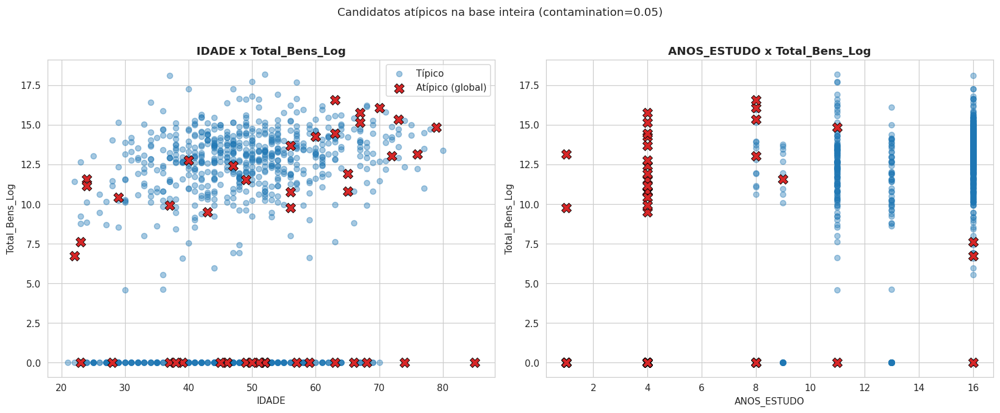

In [132]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, (x_col, y_col) in zip(axes, [('IDADE', 'Total_Bens_Log'), ('ANOS_ESTUDO', 'Total_Bens_Log')]):
    tipicos = df_cluster[df_cluster['anomalia_global'] == 'Típico']
    atipicos = df_cluster[df_cluster['anomalia_global'] == 'Atípico']
    ax.scatter(tipicos[x_col], tipicos[y_col], c='tab:blue', alpha=0.4, s=35, label='Típico')
    ax.scatter(atipicos[x_col], atipicos[y_col], c='tab:red', marker='X', s=110,
               edgecolor='black', linewidth=0.6, label='Atípico (global)')
    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)
    ax.set_title(f'{x_col} x {y_col}')

axes[0].legend()
plt.suptitle(f'Candidatos atípicos na base inteira (contamination={contamination_global})', y=1.02)
plt.tight_layout()
plt.show()


### O mesmo recorte, em 3D

As duas variáveis de cada vez (painel acima) escondem alguma coisa: dois candidatos podem parecer próximos no plano `IDADE` x `Total_Bens_Log` e estar bem longe um do outro na terceira variável (`ANOS_ESTUDO`). Como o modelo usa as **3 variáveis-driver ao mesmo tempo**, um gráfico 3D interativo mostra isso sem esconder nenhuma dimensão — arrastem pra rotacionar, passem o mouse num ponto pra ver quem é.


In [133]:
cores_iso = {'Típico': '#1f77b4', 'Atípico': '#d62728'}

fig3d = go.Figure()
for status, cor in cores_iso.items():
    sub = df_cluster[df_cluster['anomalia_global'] == status]
    fig3d.add_trace(go.Scatter3d(
        x=sub['IDADE'], y=sub['ANOS_ESTUDO'], z=sub['Total_Bens_Log'],
        mode='markers', name=status,
        marker=dict(
            size=6 if status == 'Típico' else 9,
            color=cor,
            symbol='circle' if status == 'Típico' else 'diamond',
            opacity=0.5 if status == 'Típico' else 0.95,
            line=dict(width=1, color='black'),
        ),
        text=sub['NM_URNA_CANDIDATO'] + ' — ' + sub['cluster'].astype(str),
        hovertemplate='<b>%{text}</b><br>IDADE=%{x}<br>ANOS_ESTUDO=%{y}<br>Total_Bens_Log=%{z:.2f}<extra></extra>',
    ))

fig3d.update_layout(
    scene=dict(xaxis_title='IDADE', yaxis_title='ANOS_ESTUDO', zaxis_title='Total_Bens_Log'),
    title=f'Candidatos atípicos (visão global) nas 3 variáveis-driver (contamination={contamination_global})',
    height=650, margin=dict(l=0, r=0, b=0, t=40),
)
fig3d.show()


---
## Detecção dentro de cada cluster: quem foge do padrão do próprio grupo?

Aqui está o detalhe metodológico que faz essa pergunta ser **diferente** da anterior, não uma repetição: se reaproveitássemos a mesma escala global (`X`, MinMax ajustado na base inteira) pra rodar o Isolation Forest separadamente por cluster, um candidato só apareceria como atípico dentro do cluster **Recém-chegados** se ele já fosse extremo pra base inteira — não é essa a pergunta. Pra perguntar "isso é estranho **para um Recém-chegado**?", precisamos **padronizar de novo, usando só a média e o desvio-padrão daquele cluster** (`StandardScaler` ajustado cluster a cluster).

Sobre `contamination` por cluster: os cinco clusters têm tamanhos bem diferentes (414 / 208 / 145 / 92 / 66 candidatos). Usamos `max(5%, 2 candidatos)` — um piso de pelo menos 2 candidatos sinalizados mesmo no cluster menor, sem passar de 50% do grupo. Com só 66 candidatos em **Desassistidos**, qualquer padrão encontrado ali é sustentado por pouquíssima gente — mesmo cuidado com amostra pequena que já apareceu nas Fases 2 e 3.


In [134]:
resultados_cluster = []

for nome in df_cluster['cluster'].unique():
    sub_idx = df_cluster.index[df_cluster['cluster'] == nome].to_numpy()
    n = len(sub_idx)

    X_cluster = df_cluster.loc[sub_idx, colunas_driver].values
    X_cluster_padronizado = StandardScaler().fit_transform(X_cluster)

    contaminacao_cluster = min(max(0.05, 2 / n), 0.5)
    iso_cluster = IsolationForest(contamination=contaminacao_cluster, random_state=SEMENTE, n_estimators=200)
    pred_cluster = iso_cluster.fit_predict(X_cluster_padronizado)
    score_cluster = iso_cluster.decision_function(X_cluster_padronizado)

    n_atipicos = int((pred_cluster == -1).sum())
    print(f"{nome} (n={n}, contamination={contaminacao_cluster:.3f}): {n_atipicos} atípicos dentro do grupo")

    resultados_cluster.append(pd.DataFrame({
        'indice_original': sub_idx,
        'anomalia_cluster': np.where(pred_cluster == -1, 'Atípico', 'Típico'),
        'score_cluster': score_cluster,
    }))

anomalia_cluster_df = pd.concat(resultados_cluster).set_index('indice_original').sort_index()
df_cluster['anomalia_cluster'] = anomalia_cluster_df['anomalia_cluster'].values
df_cluster['score_cluster'] = anomalia_cluster_df['score_cluster'].values


Prósperos (n=414, contamination=0.050): 21 atípicos dentro do grupo


Batalhadores (n=208, contamination=0.050): 11 atípicos dentro do grupo
Promissores (n=145, contamination=0.050): 8 atípicos dentro do grupo


Recém-chegados (n=92, contamination=0.050): 5 atípicos dentro do grupo
Desassistidos (n=66, contamination=0.050): 4 atípicos dentro do grupo


In [135]:
for nome in df_cluster['cluster'].unique():
    print(f"--- {nome}: mais atípicos dentro do grupo ---")
    sub = df_cluster[(df_cluster['cluster'] == nome) & (df_cluster['anomalia_cluster'] == 'Atípico')]
    display(sub.sort_values('score_cluster')[colunas_ficha_anomalia + ['score_cluster']])


--- Prósperos: mais atípicos dentro do grupo ---


,NM_URNA_CANDIDATO,SG_PARTIDO,IDADE,ANOS_ESTUDO,Total_Bens,cluster,score_cluster
116,SANDRA LACERDA,PODE,51,13,"10,000,000.00",Prósperos,-0.17
860,VILELA DO PT,PT,68,13,"1,051,667.00",Prósperos,-0.14
34,VIRGÍLIO VIANA,PV,23,16,"2,000.00",Prósperos,-0.13
130,CRIS NUNES,REDE,39,16,718.37,Prósperos,-0.10
653,JHONATA OLIVEIRA,MISSÃO,24,16,"7,000.00",Prósperos,-0.08
413,ADRIANO COELHO,MDB,37,16,"71,216,159.16",Prósperos,-0.07
227,PROFESSORA LENE MAIA,DC,47,16,"1,000.00",Prósperos,-0.07
223,DOUTORA AMANDA SOUZA,DC,48,16,"1,000.00",Prósperos,-0.07
333,PROFESSOR SILAS,DC,77,16,"60,193.12",Prósperos,-0.06
316,DOUTORA ALICE MAFRA,MOBILIZA,29,16,"5,000.00",Prósperos,-0.05


--- Batalhadores: mais atípicos dentro do grupo ---


,NM_URNA_CANDIDATO,SG_PARTIDO,IDADE,ANOS_ESTUDO,Total_Bens,cluster,score_cluster
77,CHICO SOMBRA,PSB,76,1,"505,499.15",Batalhadores,-0.13
224,NONATO CHEGADO,DC,56,1,"17,280.00",Batalhadores,-0.10
708,REPORTER FELIPE BARROS,PSB,24,4,"70,000.00",Batalhadores,-0.04
637,LUIZ CLAUDIO DA AGRICULTURA,PSD,66,13,"6,700.00",Batalhadores,-0.03
573,RAIMUNDO BELO,SOLIDARIEDADE,59,11,744.98,Batalhadores,-0.03
385,LUIZ REBELO,PSD,67,4,"6,947,024.42",Batalhadores,-0.02
876,LÁZARO BOTELHO,PP,79,11,"2,724,977.20",Batalhadores,-0.02
485,LUAN NUNES,PODE,29,4,"33,245.00",Batalhadores,-0.02
398,DJ GORDO DO CROCODILO,PDT,43,4,"13,465.00",Batalhadores,-0.00
5,VAGNER SALES,MDB,67,4,"3,728,000.00",Batalhadores,-0.00


--- Promissores: mais atípicos dentro do grupo ---


,NM_URNA_CANDIDATO,SG_PARTIDO,IDADE,ANOS_ESTUDO,Total_Bens,cluster,score_cluster
780,IRONDINA,NOVO,85,11,0.00,Promissores,-0.22
299,ANA ROQUE,UP,22,16,825.09,Promissores,-0.17
295,PROFESSOR ARQLEYDSSON,PCDOB,44,16,388.70,Promissores,-0.11
601,RAFAEL FERA,PODE,36,16,253.24,Promissores,-0.11
726,PAULO QUARTIERO,DC,74,16,0.00,Promissores,-0.06
572,CHICO DA PESCA,SOLIDARIEDADE,64,13,0.00,Promissores,-0.05
719,JOSUÉ SHOCKNESS,PSOL,61,13,0.00,Promissores,-0.01
324,LUIZ ANDRADE,REDE,49,13,0.00,Promissores,-0.00


--- Recém-chegados: mais atípicos dentro do grupo ---


,NM_URNA_CANDIDATO,SG_PARTIDO,IDADE,ANOS_ESTUDO,Total_Bens,cluster,score_cluster
597,CLEVIANE MOREIRA,NOVO,36,13,100.00,Recém-chegados,-0.17
251,IANA NADINA,MISSÃO,30,11,98.16,Recém-chegados,-0.14
55,HECHYLEN PEREIRA DAVILA,UNIÃO,23,8,0.00,Recém-chegados,-0.07
254,JOTA BRANDÃO,MISSÃO,35,8,0.00,Recém-chegados,-0.01
526,MARCUS JÚNIOR,AVANTE,35,8,0.00,Recém-chegados,-0.01


--- Desassistidos: mais atípicos dentro do grupo ---


,NM_URNA_CANDIDATO,SG_PARTIDO,IDADE,ANOS_ESTUDO,Total_Bens,cluster,score_cluster
749,NIMOZ LOPES,PSOL,28,4,0.00,Desassistidos,-0.06
32,SIDILENE SILVA,PV,37,1,0.00,Desassistidos,-0.05
89,ZÉ CARLOS,PRD,70,11,0.00,Desassistidos,-0.02
341,MARIA DO CARMO,DC,66,4,0.00,Desassistidos,-0.01


### O mesmo recorte, em 3D — filtrando por cluster

Mesma ideia do gráfico 3D global, agora um por cluster: escolham no menu qual grupo olhar (cada cluster usa a sua **própria** padronização, então os pontos vermelhos aqui são atípicos *dentro daquele grupo*, não em relação à base inteira). Os eixos ficam fixos entre um cluster e outro, pra dar pra comparar a posição relativa.


In [136]:
nomes_bisecting_ordenados = list(df_cluster['cluster'].unique())
n_status = len(cores_iso)  # 'Típico' e 'Atípico', mesmas cores do gráfico 3D global

fig3d_cluster = go.Figure()
for idx_cluster, nome in enumerate(nomes_bisecting_ordenados):
    for status, cor in cores_iso.items():
        sub = df_cluster[(df_cluster['cluster'] == nome) & (df_cluster['anomalia_cluster'] == status)]
        fig3d_cluster.add_trace(go.Scatter3d(
            x=sub['IDADE'], y=sub['ANOS_ESTUDO'], z=sub['Total_Bens_Log'],
            mode='markers', name=status,
            marker=dict(
                size=6 if status == 'Típico' else 9,
                color=cor,
                symbol='circle' if status == 'Típico' else 'diamond',
                opacity=0.55 if status == 'Típico' else 0.95,
                line=dict(width=1, color='black'),
            ),
            text=sub['NM_URNA_CANDIDATO'],
            hovertemplate='<b>%{text}</b><br>IDADE=%{x}<br>ANOS_ESTUDO=%{y}<br>Total_Bens_Log=%{z:.2f}<extra></extra>',
            visible=(idx_cluster == 0),       # só o primeiro cluster começa visível
            legendgroup=status,
            showlegend=(idx_cluster == 0),    # legenda não se repete a cada cluster
        ))

# um botão por cluster no menu suspenso — cada um liga só os 2 traços (Típico/Atípico) daquele cluster
botoes_cluster = []
for idx_cluster, nome in enumerate(nomes_bisecting_ordenados):
    visibilidade = [False] * (len(nomes_bisecting_ordenados) * n_status)
    for j in range(n_status):
        visibilidade[idx_cluster * n_status + j] = True
    botoes_cluster.append(dict(
        label=nome, method='update',
        args=[{'visible': visibilidade}, {'title': f'Atípicos dentro do cluster: {nome}'}],
    ))

fig3d_cluster.update_layout(
    scene=dict(
        xaxis_title='IDADE', yaxis_title='ANOS_ESTUDO', zaxis_title='Total_Bens_Log',
        xaxis=dict(range=[df_cluster['IDADE'].min() - 2, df_cluster['IDADE'].max() + 2]),
        yaxis=dict(range=[df_cluster['ANOS_ESTUDO'].min() - 1, df_cluster['ANOS_ESTUDO'].max() + 1]),
        zaxis=dict(range=[df_cluster['Total_Bens_Log'].min() - 0.5, df_cluster['Total_Bens_Log'].max() + 0.5]),
    ),
    updatemenus=[dict(active=0, buttons=botoes_cluster, x=0.02, y=1.05, xanchor='left')],
    title=f'Atípicos dentro do cluster: {nomes_bisecting_ordenados[0]}',
    height=650, margin=dict(l=0, r=0, b=0, t=60),
)
fig3d_cluster.show()


### Comparando: global vs. dentro do cluster

Quatro combinações possíveis pra cada candidato: atípico nos dois recortes (destoa de tudo, robusto), só globalmente, só dentro do cluster, ou típico nos dois. O caso mais interessante pedagogicamente é o **"só dentro do cluster"**: candidatos que passam despercebidos quando olhamos a base inteira, mas que não se parecem com seus próprios colegas de grupo.


In [137]:
tabela_comparacao = pd.crosstab(df_cluster['anomalia_global'], df_cluster['anomalia_cluster'])
tabela_comparacao.index.name = 'anomalia_global \\ anomalia_cluster'
display(tabela_comparacao)

so_no_cluster = df_cluster[(df_cluster['anomalia_global'] == 'Típico') & (df_cluster['anomalia_cluster'] == 'Atípico')]
print(f"\n{len(so_no_cluster)} candidatos são atípicos só DENTRO do próprio cluster (passariam despercebidos na análise global):")
so_no_cluster[colunas_ficha_anomalia + ['score_cluster']].sort_values('score_cluster')


anomalia_cluster,Atípico,Típico
anomalia_global \ anomalia_cluster,,
Atípico,17,30
Típico,32,846



32 candidatos são atípicos só DENTRO do próprio cluster (passariam despercebidos na análise global):


,NM_URNA_CANDIDATO,SG_PARTIDO,IDADE,ANOS_ESTUDO,Total_Bens,cluster,score_cluster
116,SANDRA LACERDA,PODE,51,13,"10,000,000.00",Prósperos,-0.17
597,CLEVIANE MOREIRA,NOVO,36,13,100.00,Recém-chegados,-0.17
251,IANA NADINA,MISSÃO,30,11,98.16,Recém-chegados,-0.14
860,VILELA DO PT,PT,68,13,"1,051,667.00",Prósperos,-0.14
295,PROFESSOR ARQLEYDSSON,PCDOB,44,16,388.70,Promissores,-0.11
601,RAFAEL FERA,PODE,36,16,253.24,Promissores,-0.11
130,CRIS NUNES,REDE,39,16,718.37,Prósperos,-0.10
653,JHONATA OLIVEIRA,MISSÃO,24,16,"7,000.00",Prósperos,-0.08
413,ADRIANO COELHO,MDB,37,16,"71,216,159.16",Prósperos,-0.07
227,PROFESSORA LENE MAIA,DC,47,16,"1,000.00",Prósperos,-0.07


---
## Fechamento

Com esta Fase 4, fecha-se o pipeline completo: preparação de dados (Fase 0), análise descritiva (Fase 1), clusterização — K-Means, Bisecting K-Means, DBSCAN e hierárquico (Fase 2), regras de associação (Fase 3) e, agora, detecção de anomalias, tanto na base inteira quanto dentro de cada cluster nomeado na Fase 2.

**Exercícios sugeridos:**
- Comparar com `sklearn.neighbors.LocalOutlierFactor` — outro clássico de detecção de anomalias, baseado em densidade local (mais parecido com a lógica do DBSCAN) em vez de isolamento por cortes aleatórios. Os dois concordam nos mesmos candidatos?
- Incluir as variáveis categóricas por quartil e/ou o gasto de campanha, se vocês fizeram o desafio da Fase 2 (`desafio_gastos_campanha.md`), como variáveis adicionais na detecção.
- Variar `contamination` (global e por cluster) e ver quão sensível é a lista de atípicos a essa escolha.
- Investigar manualmente 2 ou 3 candidatos da lista "só dentro do cluster" — o que a ficha completa deles (partido, ocupação, bens declarados) sugere sobre por que destoam do próprio grupo?
